In [1]:
#imported from Pranav Sanghavi's notebook -- 
import glob 
import os
import time
import h5py
import matplotlib.pylab as plt
import numpy as np
import numpy.ma as ma
from matplotlib.offsetbox import AnchoredText
from matplotlib.pylab import colorbar 
from skrf import Network, Frequency
from platform import python_version
from rawice import *
import math
import psutil
import matplotlib.cm as cm
#importing for Will's function --  
from scipy import interpolate
import datetime
from scipy.signal import square
from scipy.stats import pearsonr
import pandas
import time_utils as tu
from mpl_toolkits.axes_grid1 import make_axes_locatable

style = 'fast'
tick_dir = 'in'
plt.style.use(style)
plt.rcParams['xtick.direction'] = tick_dir
plt.rcParams['ytick.direction'] = tick_dir
plt.rcParams['axes.linewidth'] = 1
plt.rcParams['font.size'] = 15
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"})

###################################################################################
# Analog chain labels
###################################################################################

#pathtoacfile = "/home/observer/tone_jupyter/anachainz.csv"
#ac = np.genfromtxt(pathtoacfile, delimiter=",", names=True,
#                   dtype=(int, int, 'U5', 'U5', int, 'U2', int))
#inputs = ac['feed']

def get_beam_fwhm(d=6.0, nu=600):
    fwhm = constants.c/(nu*1e6)/d   # lambda/D
    return np.rad2deg(fwhm * 1.22)

def gaussian(x, a, mean, sigma):
    val = a * np.exp(-(x - mean)**2 / sigma**2)
    return val

def scale_zero_one(x):
    return (x - x.min())/(x.max() - x.min())

def seconds_to_degrees(seconds, declination=22.0145):
    """
        This function converts seconds to degrees of sky motion at a latitude 
        default TONE latitude -- default for crab.
    """
    return seconds * np.cos(np.deg2rad(declination)) / 240

def read_corr_mode_h5(file_path, f_start=None, f_stop=None):
    """
        This function reads all hdf5 files.
    """
    class correlator_data:
        def __init__(self, vis, time, sat, index_map):
            self.vis = vis
            self.time = time
            self.sat = sat
            self.freq = index_map["freq"][:]
            self.prod = index_map['prod'][:]
    files = glob.glob(file_path + "*[!.lock]")
    files.sort()
    
    #grab different sets of files.  
    if f_start is not None:
        if f_stop is not None:
            files = files[f_start:f_stop]
        else:
            files = files[f_start:]
    if f_start is None:
        if f_stop is not None:
            files = files[:f_stop]

    try:
        t = 0
        for x in files:
            print(f"Reading File: {x}")
            f = h5py.File(x, "r")
            index_map = f['index_map']
            if(t == 0):
                vis = f['vis'][:]
                time = index_map['time'][:]
                sat = f['sat'][:]
                print("Appended vis data and time stream from %s" % (x))
                t = t + 1
            else:
                time = np.append(time, index_map['time'][:])
                vis = np.append(vis, f['vis'][:], axis=0)
                sat = np.append(sat, f['sat'][:], axis=0)
                print("Appended vis data and time stream from %s" % (x))
        
        return correlator_data(
            vis,
            time,
            sat,
            index_map
        )
    finally:
        print("Done!!!!!!!")

def get_mag_phase(corr_dat):
    """
        This function returns magnitude and phase in degrees of correlations.
    """
    return np.absolute(corr_dat), np.rad2deg(np.angle(corr_dat))

def plot_waterfall_corr_data(data, corr_indices):
    """
        This function plots waterfall across 1024 frequency channels.
        Frequency range: 400-800MHz
    """
    fig=plt.figure(figsize=(20,15))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    for i,auto in enumerate(corr_indices):
        ax=plt.subplot(dim1, dim2, i + 1)
        wfall = data[:, :, auto] # auto -> corr index 
        im=plt.imshow(wfall, vmin = np.nanpercentile(wfall,5), vmax =np.nanpercentile(wfall,95), cmap='magma', aspect='auto')
        plt.xlabel("freq index")
        plt.ylabel("time index")
        plt.title(f"corr {corr_data.prod[auto]}")
        divider=make_axes_locatable(ax)
        cax=divider.append_axes("right", size="5%", pad=0.05)
        cbar=fig.colorbar(im,cax=cax)
        cbar.set_label('Power [$ADU^2$]')
    plt.tight_layout()
    #plt.savefig(f"/Users/kalyanibhopi94/Documents/kalyanib_dns/corr_dns_plots/drone_testing_4x2_Apr2025/Apr07...246Z/switched_mode_reset/waterfall_{f_start}_{f_stop}.pdf",
    #            dpi=300)

    
def plot_freq_channel_corr_data(pow_mag, freq_index, freq, corr_indices):
    """
        This function plots phase for a given frequency index for given time window.
    """
    plt.figure(figsize=(20, 20))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    for index, corr_index in enumerate(corr_indices):
            plt.subplot(dim1, dim2, index + 1)
            plt.title(f"Corr: {corr_data.prod[corr_index]}")
            plt.plot(pow_mag[:, freq_index, corr_index])
    plt.suptitle(f"Frequency {freq} MHz")
    plt.tight_layout()
    
def plot_phase_corr_data(pow_phase, corr_indices, t_ind_arr):
    """
        This function plots phase for a given time index across frequency range of 400-800MHz.
    """
    colorsarr=cm.magma(np.linspace(0,1,2048))
    for i, t_index in enumerate(t_ind_arr):
        fig= plt.figure(figsize=(25, 10))
        dim1 = math.floor(math.sqrt(len(corr_indices)*len(t_ind_arr)))
        dim2 = math.ceil(len(corr_indices)*len(t_ind_arr)/dim1)
        for index, corr_index in enumerate(corr_indices):
                ax = plt.subplot(dim2, dim1, i + 1)
                ax.plot(pow_phase[t_index,:, corr_index], c=colorsarr[300], label=f'time index {t_index}')
                ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
                plt.xlabel(f"frequency index")
                plt.ylabel(f"phase (degrees)")
                plt.title(f"Corr: {corr_data.prod[corr_index]}")
                #plt.suptitle(f"Correlated noise phase")
        plt.tight_layout()
    #plt.savefig(f"/Users/kalyanibhopi94/Documents/kalyanib_dns/corr_dns_plots/drone_testing_4x2_Apr2025/Apr07...246Z/switched_mode_reset/phase_{f_start}_{f_stop}.pdf",
    #            dpi=300)


In [2]:
print("current python version is:",python_version())
print("current numpy version is:",np.__version__)

current python version is: 3.9.10
current numpy version is: 1.22.4


## Reading digital gains for all the correlator channels 

In [ ]:
f = h5py.File("/Users/kalyanibhopi94/Documents/research/Projects/digital_cal_source/data_raw/iceboard_data/digital_gains/20250319T171034Z_WVUc52_digitalgain/00000057.h5","r")

#Plotting digital gains -- 
print(list(f.attrs))
print(f.attrs['acquisition_name'])
print(f.attrs['archive_version'])
print(f.attrs['collection_server'])
print(f.attrs['git_version_tag'])
print(f.attrs['instrument_name'])
print(f.attrs['notes'])
print(f.attrs['system_user'])
print(f.attrs['type'])
print(f.attrs['version'])

print(list(f.items()))
print((f['compute_time']))
print((f['index_map']))
print((f['gain_coeff']))
print((f['gain_exp']))

inputs = (f['index_map']['input'][:])
frqs = f['index_map']['freq'][:]
gaincoeff = f['gain_coeff'][()]
gainexp = f['gain_exp'][()]
gain = gaincoeff.real*np.exp2(gainexp)

plt.figure(figsize=[16,18])
print(f"Calculating digital gains of the channels...")
i = 0
for i in np.arange(0,4,1):  
    plt.subplot(8,2,i+1)
    #Digital gain of every channel
    plt.scatter(frqs['centre'], gain[0][:,i]) # i referes to input channel (total 16 ch on iceboard); 
    #plt.title( " %s and gain_exp = %s and rms %s for rms i/p %s" %(inputs[i], gainexp[:,i], rms[i][2], rms[i][0][2]))
    plt.title( " %s " %(inputs[i]))
plt.tight_layout()

In [ ]:
# gains related stats -- 

print(gainexp)
print(gaincoeff[0,:,1])
gain = gaincoeff.real*np.exp2(gainexp)
print(gain.shape)
print(gain[0,:,1])
print(gain[0,:,1].shape)
print(frqs['centre'])
print(inputs)

## Analysing raw adc rms of the whole data run; Plotting Histogram of the signal received per correlator channel; From Pranav's "analyse_raw_adc-checkpoint.ipynb" notebook

In [ ]:
folder_path = "/Users/kalyanibhopi94/Downloads/iceboard_data/corr_data/20250609T180246Z_WVUc52/raw_acq/"
try:
    file_name = get_newest_file(folder_path)
    raw_acq(file_name, False)
except OSError:
    file_name = get_second_newest_file(folder_path)
    raw_acq(file_name, False)

In [ ]:
crate_number = 0 
slot_number = 0

figrms = plt.figure(figsize=(30, 30))
figfft = plt.figure(figsize=(30, 30))
fighist = plt.figure(figsize=(30, 30))

figrms.suptitle(f"ADC RMS START: {raw_acq.start_time} STOP: {raw_acq.end_time}\n crate no.:{crate_number} slot no.:{crate_number}", y=0.92,
ha='center')
figfft.suptitle(f"FFT MAG START: {raw_acq.start_time} STOP:{raw_acq.end_time} \n crate no.:{crate_number} slot no.:{crate_number}", y=0.92,
ha='center')
fighist.suptitle(f"ADC Histogram START: {raw_acq.start_time} STOP:{raw_acq.end_time} \n crate no.:{crate_number} slot no.:{crate_number} ", y=0.92,
ha='center')


rms_above_threshold = {}
rms_below_threshold = {}

for i in range(4):
    input_to_check = [crate_number, slot_number, i]
    raw = raw_acq.check_input(input_to_check)
    rms = raw.rms
    if np.median(rms) > 60:
        rms_above_threshold[i] = "ADC RMS above 60"
    if np.median(rms) < 8:
        rms_below_threshold[i] = "ADC RMS below 8"
    fft = raw.mag_fft
    ts = raw.time_fpga_count
    times = (ts - ts[0])*2.56e-6/60
    axrms = figrms.add_subplot(4, 4, i+1)
    axrms.scatter(times, rms, s=1, c='k', rasterized=True)
    axrms.set_title(f'input: {i}')
    axrms.set_xlabel('minutes')
    axrms.set_ylabel('adc units')
    axrms.axhline([2], lw=0.5, c='r')
    axrms.grid(axis='both', linestyle='-', linewidth=1)
    
    axfft = figfft.add_subplot(4, 4, i+1)
    axfft.imshow(
        fft,
        aspect='auto',
        vmin=np.percentile(fft, 5),
        vmax=np.percentile(fft, 95),
        extent=[800, 400, times[-1], times[0]],
        interpolation='none',
        rasterized=True
    )
    axfft.set_title(f'input: {i}')
    axfft.set_ylabel("minutes")
    axfft.set_xlabel("MHz")
    
    inp0 = np.where(raw_acq.adc_input[:] == i)[0]
    ant0_data = raw_acq.timestream[:][inp0]
    ant0_data = ant0_data[:]
    axhist = fighist.add_subplot(4, 4, i+1)
    hist, bin_edges = np.histogram(ant0_data, bins=256,  density=True)
    axhist.step(bin_edges[1:], hist, where='mid', c='k', rasterized=True)
    axhist.set_title(f'input: {i}')
    axhist.set_xlim([-129, 129])
    axhist.set_ylim(0,0.1)
    
#pp = PdfPages(f"{SAVE_DIR}{raw_acq.start_time}_{raw_acq.end_time}_raw_acq.pdf")
#pp.savefig(figrms)
#pp.savefig(figfft)
#pp.savefig(fighist)
#pp.close()

## Analysis of correlator data for correlation powers, waterfall and phase

In [ ]:
#Reading correlation files -- 
file_path = '/Users/kalyanibhopi94/Downloads/drone_flight8_NWgrid_NWpol_42db_jul2_1930/*' 
f_start=1
f_stop=4
corr_data = read_corr_mode_h5(file_path, f_start, f_stop) 
print("getting auto and cross-correlation magnitudes and phase")
pow_mag, pow_phase = get_mag_phase(corr_data.vis)
print("done getting pow_mag and pow_phase")
sat_data = corr_data.sat.real

corr_size=corr_data.vis[:,:,:].shape
print('corr data shape: {}'.format(corr_size)) # time bins - freq bins - corr indices

Reading File: /Users/kalyanibhopi94/Downloads/drone_flight8_NWgrid_NWpol_42db_jul2_1930/1.hdf5
Appended vis data and time stream from /Users/kalyanibhopi94/Downloads/drone_flight8_NWgrid_NWpol_42db_jul2_1930/1.hdf5
Reading File: /Users/kalyanibhopi94/Downloads/drone_flight8_NWgrid_NWpol_42db_jul2_1930/10.hdf5
Appended vis data and time stream from /Users/kalyanibhopi94/Downloads/drone_flight8_NWgrid_NWpol_42db_jul2_1930/10.hdf5
Reading File: /Users/kalyanibhopi94/Downloads/drone_flight8_NWgrid_NWpol_42db_jul2_1930/11.hdf5
Appended vis data and time stream from /Users/kalyanibhopi94/Downloads/drone_flight8_NWgrid_NWpol_42db_jul2_1930/11.hdf5
Done!!!!!!!
getting auto and cross-correlation magnitudes and phase


In [ ]:
f=h5py.File("/Users/kalyanibhopi94/Documents/research/Projects/digital_cal_source/data_raw/iceboard_data/corr_data/20250407T195246Z_WVUc52/corr/20250407T195342Z/0000","r")

print(list(f.keys()))
print(f['index_map']['time'])
print(f['index_map']['time'][:])

In [126]:
# visibility data 
corr_data.vis[1][:][31] # correlation data having real and imag component 
print(corr_data.vis[:,:,:].shape) # time bins - freq bins - corr indices

(15360, 1024, 10)


Each time bin is: 0.04194304 seconds
total time bins (considered for the plots) are 15360
lowest time bin 0 and highest time bin 15360
644.2450944 seconds of data (considered for the plots)


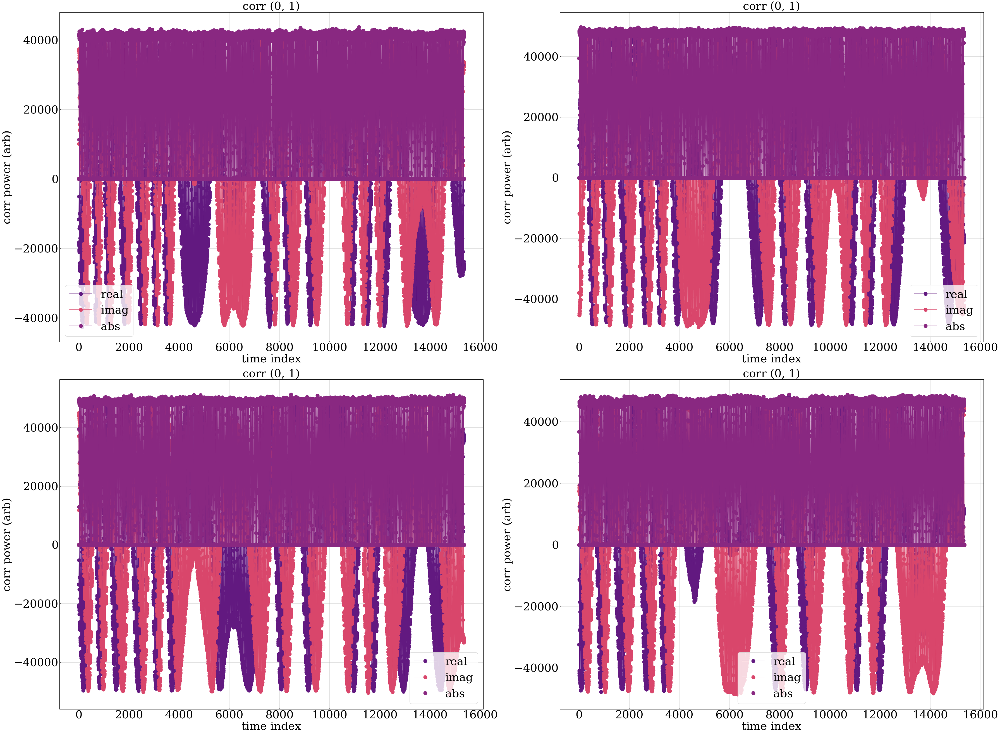

In [139]:
## Plotting real and imag correlated system noise powers against time index for a given set of frequencies -- 

tmin,tmax=[0,corr_size[0]]
#tmin,tmax=[2000, 7000]
freq_arr=[250,546,625,825]
#freq_arr=[325,546,625,745]
corr_indices=[1]
dim1 = math.floor(math.sqrt(len(corr_indices)*len(freq_arr)))
dim2 = math.ceil(len(corr_indices)*len(freq_arr)/dim1)
fig = plt.figure(figsize=[50,40])
for index1,f_ind in enumerate(freq_arr):
    colorsarr=cm.magma(np.linspace(0,1,2048))
    freq=400+((1024-f_ind)*0.390625)
    for index2, corr_index in enumerate(corr_indices): 
        panel_ind = index1 * len(corr_indices) + index2 + 1 
        ax=plt.subplot(dim2, dim1, panel_ind)
        ax.plot(corr_data.vis.real[tmin:tmax,f_ind,corr_index],'o-', markersize=13, c=colorsarr[600], label='real')
        ax.plot(corr_data.vis.imag[tmin:tmax,f_ind,corr_index],'o-', markersize=13, c=colorsarr[1200], label='imag')
        ax.plot(pow_mag[tmin:tmax,f_ind,corr_index],'o-', markersize=13, c=colorsarr[800], label='abs')
        #ax.set_xlim(100,300)
        #ax.set_ylim(35000,42000)
        ax.legend(fontsize=40)
        plt.xticks(fontsize=40)
        plt.yticks(fontsize=40)
        plt.title(f"corr {corr_data.prod[corr_index]}", fontsize=40)
        plt.xlabel("time index", fontsize=40)
        plt.ylabel("corr power (arb)", fontsize=40)
    #plt.suptitle(f"Absolute power for frequency {freq}MHz", ha='center', fontsize=20)
    fig.tight_layout(rect=[0, 0.03, 1, 0.95])
#fig.savefig(f"/Users/kalyanibhopi94/Downloads/June2025_pulsing_mode_time_stability_chamber/investigate_plots/20.png", dpi=300)
    

delta_time = np.diff(corr_data.time["irigb_time"])[1]*1e-9 
print(f"Each time bin is: {delta_time} seconds")
print(f"total time bins (considered for the plots) are {len(corr_data.vis[tmin:tmax,0,0])}") 
print(f"lowest time bin {tmin} and highest time bin {tmax}")
print(f"{delta_time*len(corr_data.vis[tmin:tmax,0,0])} seconds of data (considered for the plots)") 

/var/folders/g1/8y2gy6ys10d17y5j2rzwkwzc0000gn/T/ipykernel_59852/3550354547.py:140: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cbar=fig.colorbar(im,cax=cax)


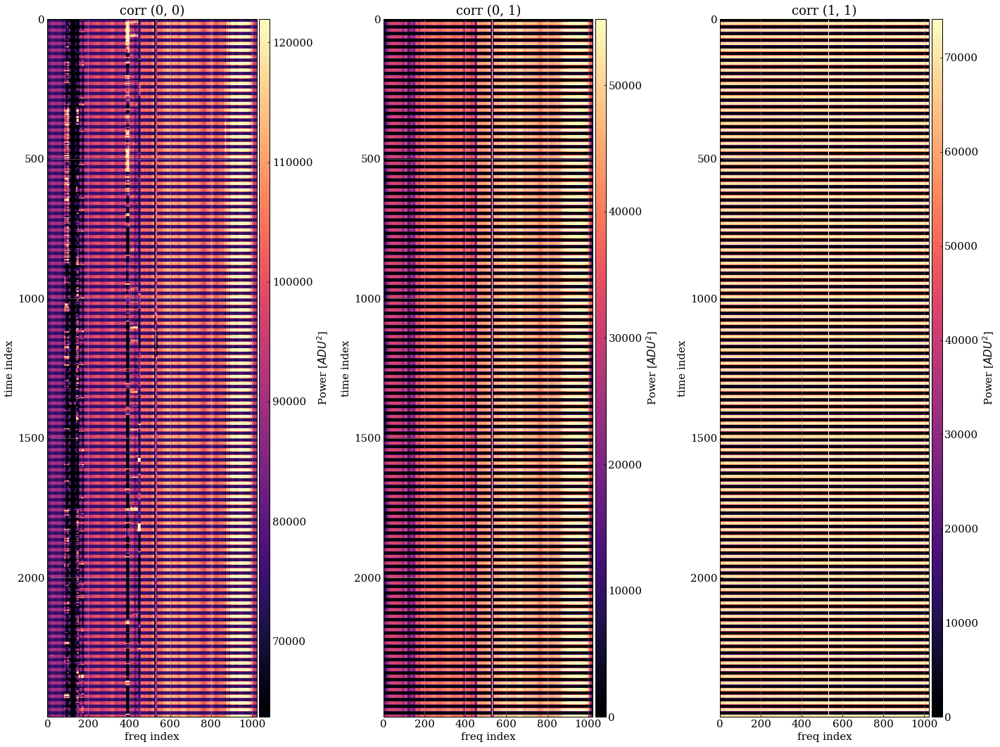

In [10]:
# plotting waterfall --

plot_waterfall_corr_data(pow_mag[:2500,:,:],[0,1,4])

In [140]:
# Phase variation for a single frequency bin as a function of time -- function defined 

def plot_freq_channel_corr_data(pow_phase, freq_index, corr_indices):
    plt.figure(figsize=(25, 10))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    frequency = corr_data.freq[freq_index]
    for index, corr_index in enumerate(corr_indices):
            plt.subplot(dim1, dim2, index + 1)
            plt.title(f"Corr: {corr_data.prod[corr_index]} : {frequency[0][0]} MHz")
            plt.plot(pow_phase[:,freq_index, corr_index])
            plt.xlabel("time indices")
            plt.ylabel("Phase (deg)")
    plt.savefig(f"/Users/kalyanibhopi94/Downloads/June2025_pulsing_mode_time_stability_chamber/investigate_plots/21.png", dpi=300)       
    #plt.suptitle(f"Frequency {freq} MHz")
    plt.tight_layout()

Frequency: [(477.734375, 0.390625)]


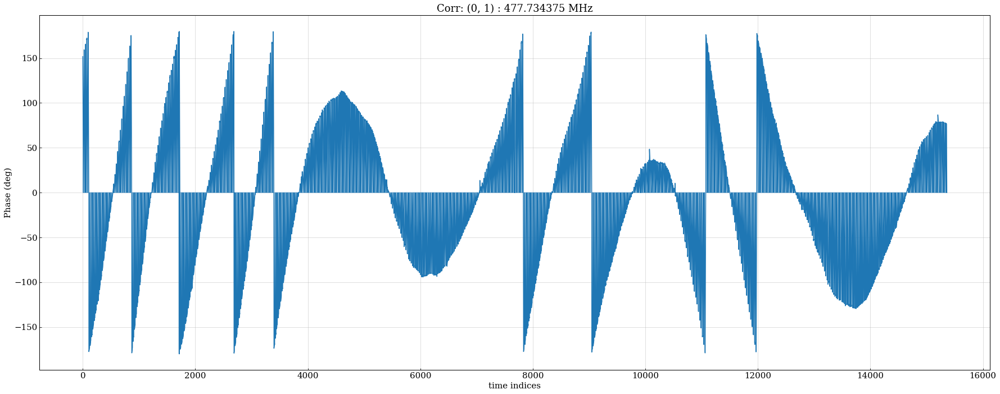

In [141]:
# Phase variation for a single frequency bin as a function of time -- calling a function

#frequency_index = np.arange(600,850,1)
#frequency_index = [250,546,625,825]
frequency_index = [825]
frequency = corr_data.freq[frequency_index]
print(f"Frequency: {frequency}")
plot_freq_channel_corr_data(pow_phase,frequency_index,[1])

on-fraction 0.500 | 644 blocks | bins/block median 11 (min 11, max 12) | pulse period median 1.007 s
blocks dropped for low phase quality: 0
max block-to-block phase step: 21.7 deg

Expected rate ratios  delay: 1.00 : 1.16 : 1.23 : 1.47   |   clock/LO: 1 : 1 : 1 : 1

[ALL]  22 windows of 30 s
  measured rate ratio r_i / r_ref : 1.00 : 1.16 : 1.23 : 1.47
  pooled RMS residual [deg/s]     : delay (r = k*f): 0.022   clock (r = c): 1.162   both (r = k*f + c): 0.017
  -> DELAY-like (rate scales with f);  best single-term model: delay (r = k*f)

[BEFORE t_idx 3800]  5 windows of 30 s
  measured rate ratio r_i / r_ref : 1.00 : 1.16 : 1.23 : 1.47
  pooled RMS residual [deg/s]     : delay (r = k*f): 0.021   clock (r = c): 1.803   both (r = k*f + c): 0.013
  -> DELAY-like (rate scales with f);  best single-term model: delay (r = k*f)

[AFTER  t_idx 3800]  17 windows of 30 s
  measured rate ratio r_i / r_ref : 1.00 : 1.17 : 1.23 : 1.47
  pooled RMS residual [deg/s]     : delay (r = k*f): 0.022   

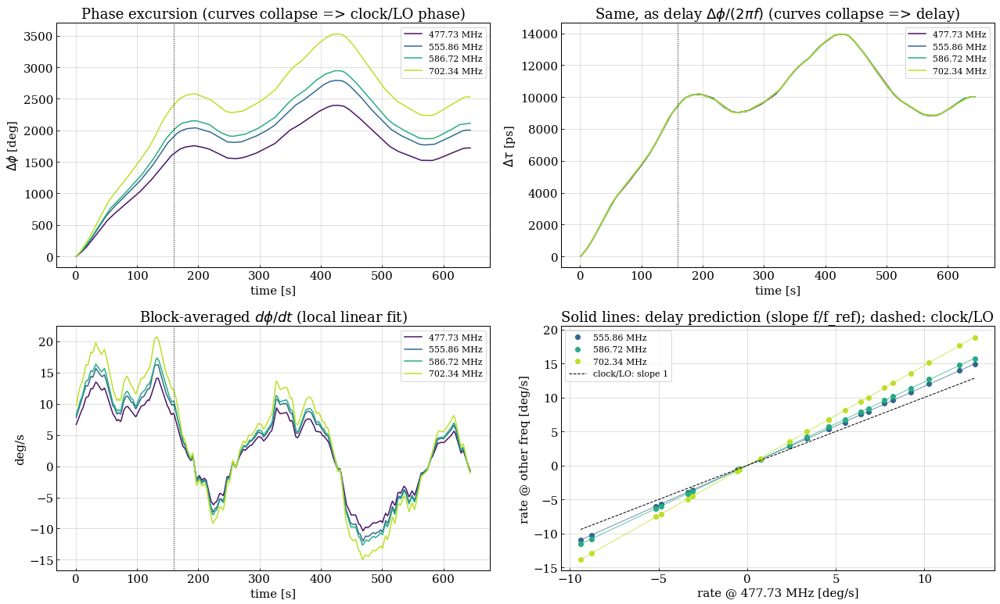

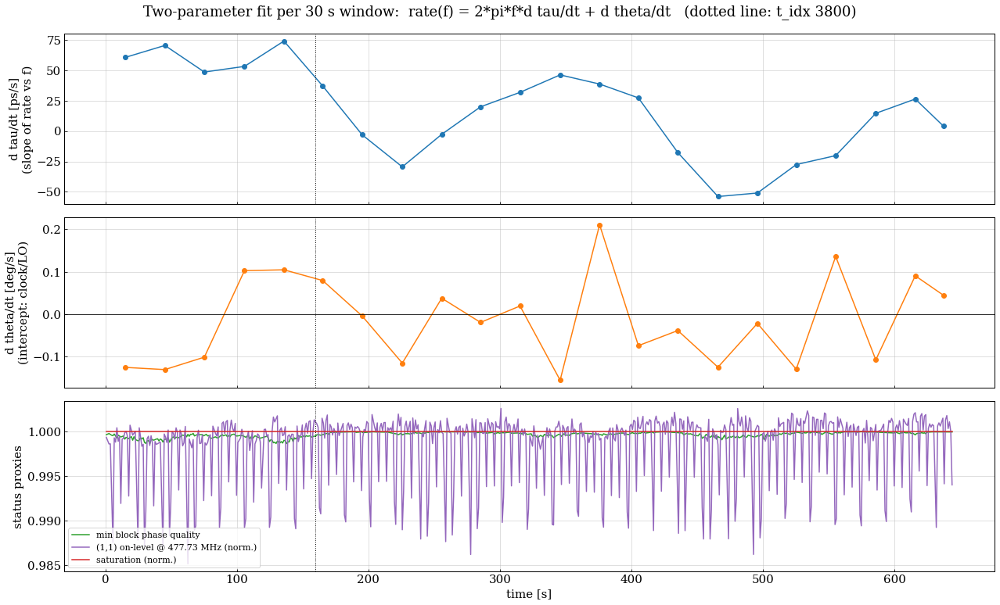

In [142]:
# =====================================================================
#  Block-averaged phase-rate test:  delay drift (rate ∝ f)  vs  clock/LO phase (rate = const)
#
#  Paste into a notebook cell, or %run it.  Run AFTER loading the PULSING-mode capture
#  (the cell reading .../June2025_pulsing_mode_time_stability_chamber/*).
#  NOTE: the later "cont_mode" cells overwrite `corr_data` - reload the pulsing data first.
#
#  Needs from the notebook:  corr_data (.vis [time,freq,prod], .time['irigb_time'], .sat)
#  Model:   phi(f,t) = 2*pi*f*tau(t) + theta(t)
#           dphi/dt  = 2*pi*f*dtau/dt + dtheta/dt
#           -> slope of (dphi/dt) vs f  = delay drift,   intercept = clock/LO phase rate
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
import pandas

# ------------------------------- config -------------------------------
FREQ_IDX      = [825, 625, 546, 250]   # 477.73, 555.86, 586.72, 702.34 MHz (first = reference)
CROSS_IDX     = 1                      # (0,1)
AUTO_B_IDX    = 4                      # (1,1): exactly 0 when the source is off -> clean gate
DELTA_TIME    = 0.04194304             # s per time bin (fallback if irigb_time is unusable)

ON_FRAC       = 0.5                    # gate > this  (x on-level)  -> "source on"
FULL_FRAC     = 0.85                   # keep only bins > this x on-level (drops partial edge bins)
MIN_BINS      = 6                      # min kept bins for a block to count (~12 expected)
MIN_BLOCK_Q   = 0.5                    # drop blocks whose phase quality < this x median quality
FIT_HALF      = 3                      # local slope uses +-FIT_HALF blocks
WIN_S         = 30.0                   # window length [s] for the frequency-scaling regression
T_SPLIT_BIN   = 3800                   # compare before / after this time index

LOCK_LOG      = None                   # path to CSV lock/clock-status log (see load_lock_log)
LOCK_TIME_COL = None                   # time column name in that CSV (default: first column)
EVENTS_S      = []                     # manual event times [s since first bin], e.g. [141.2, 160.0]
# ----------------------------------------------------------------------

F_MHZ = np.array([400.0 + (1024 - i) * 0.390625 for i in FREQ_IDX])   # same mapping as notebook
nF = len(FREQ_IDX)
fratio = F_MHZ / F_MHZ[0]


# ------------------------------- helpers -------------------------------
def load_lock_log(path, t0_unix, time_col=None):
    """CSV with a time column (unix s/ms/us/ns, ISO string, or seconds already relative to the
    first bin) and one or more status columns (numeric or text, e.g. LOCKED/HOLDOVER).
    Returns (t_rel_seconds, DataFrame of status columns)."""
    df = pandas.read_csv(path)
    tc = time_col or df.columns[0]
    s = df[tc]
    if pandas.api.types.is_numeric_dtype(s):
        t = s.to_numpy(float)
        a = np.nanmax(np.abs(t))
        if   a > 1e17: t = t * 1e-9 - t0_unix
        elif a > 1e14: t = t * 1e-6 - t0_unix
        elif a > 1e11: t = t * 1e-3 - t0_unix
        elif a > 1e8:  t = t - t0_unix          # unix seconds
        # else: already relative seconds
    else:
        t = pandas.to_datetime(s, utc=True).astype("int64").to_numpy() * 1e-9 - t0_unix
    return t, df.drop(columns=[tc])


def local_slope(t, y, half):
    n = len(t); out = np.full(n, np.nan)
    for k in range(n):
        lo, hi = max(0, k - half), min(n, k + half + 1)
        if hi - lo >= 3:
            out[k] = np.polyfit(t[lo:hi], y[lo:hi], 1)[0]
    return out


def model_rms(R):
    """R: (nF, nwin) rates [deg/s].  RMS residual of: delay-only, clock-only, both."""
    res = {"delay (r = k*f)": [], "clock (r = c)": [], "both (r = k*f + c)": []}
    A2 = np.column_stack([F_MHZ, np.ones(nF)])
    for r in R.T:
        k = (F_MHZ @ r) / (F_MHZ @ F_MHZ)
        res["delay (r = k*f)"].append(r - k * F_MHZ)
        res["clock (r = c)"].append(r - r.mean())
        res["both (r = k*f + c)"].append(r - A2 @ np.linalg.lstsq(A2, r, rcond=None)[0])
    return {k: float(np.sqrt(np.mean(np.square(v)))) for k, v in res.items()}


# ------------------------------- time axis -------------------------------
vis = corr_data.vis
nt = vis.shape[0]
try:
    t_abs_ns = np.asarray(corr_data.time["irigb_time"]).astype(np.int64)
    t_sec = (t_abs_ns - t_abs_ns[0]) * 1e-9
    t0_unix = t_abs_ns[0] * 1e-9
    assert np.all(np.diff(t_sec) > 0)
except Exception:
    print("irigb_time unusable -> using index * DELTA_TIME")
    t_sec = np.arange(nt) * DELTA_TIME
    t0_unix = 0.0
t_split = t_sec[min(T_SPLIT_BIN, nt - 1)]

V01 = vis[:, FREQ_IDX, CROSS_IDX].astype(np.complex128)          # (nt, nF)
P11 = np.abs(vis[:, FREQ_IDX, AUTO_B_IDX]).astype(float)         # (nt, nF)

# ------------------------------- step 0: on/off gate -------------------------------
gate = (P11 / np.percentile(P11, 99, axis=0)).sum(axis=1)       # broadband, noise-averaged
gate /= np.median(gate[gate > 0.5 * gate.max()])                # on-level -> 1
on, full = gate > ON_FRAC, gate > FULL_FRAC
if not (0.3 < on.mean() < 0.7):
    raise RuntimeError(f"on-fraction = {on.mean():.2f}: this is not a ~50% duty-cycle pulsing capture. "
                       "Reload the pulsing-mode data (corr_data currently holds something else?).")

# contiguous "on" runs -> blocks of fully-on bins
edges = np.flatnonzero(np.diff(np.r_[0, on.astype(int), 0]))
blocks = []
for a, b in zip(edges[0::2], edges[1::2]):
    idx = np.arange(a, b)[full[a:b]]
    if len(idx) >= MIN_BINS:
        blocks.append(idx)
nb = len(blocks)
bins_per = np.array([len(b) for b in blocks])
tb_all = np.array([t_sec[b].mean() for b in blocks])
print(f"on-fraction {on.mean():.3f} | {nb} blocks | bins/block median {np.median(bins_per):.0f} "
      f"(min {bins_per.min()}, max {bins_per.max()}) | pulse period median {np.median(np.diff(tb_all)):.3f} s")

# ------------------------------- step 1: block-average V01, unwrap -------------------------------
Vb = np.array([V01[b].mean(axis=0) for b in blocks]).T                       # (nF, nb) coherent mean
Q  = np.array([np.abs(V01[b].mean(axis=0)) / np.abs(V01[b]).mean(axis=0) for b in blocks]).T
keep = (Q > MIN_BLOCK_Q * np.median(Q, axis=1, keepdims=True)).all(axis=0)   # same blocks at all freqs
print(f"blocks dropped for low phase quality: {(~keep).sum()}")
Vb, Q, tb = Vb[:, keep], Q[:, keep], tb_all[keep]
kept_blocks = [b for b, k in zip(blocks, keep) if k]

phi = np.degrees(np.unwrap(np.angle(Vb), axis=1))                            # (nF, nblk) deg
step = np.abs(np.diff(phi, axis=1)).max()
print(f"max block-to-block phase step: {step:.1f} deg" + ("   <-- >90 deg: unwrap may be unsafe" if step > 90 else ""))
dphi = phi - phi[:, :1]                                                       # excursion from first block
dtau_ps = dphi / (360.0 * F_MHZ[:, None] * 1e6) * 1e12                        # equivalent delay [ps]

rate = np.array([local_slope(tb, p, FIT_HALF) for p in phi])                  # (nF, nblk) deg/s

# ------------------------------- step 2: compare rates across frequencies -------------------------------
wedges = np.arange(tb[0], tb[-1] + WIN_S, WIN_S)
tw, Rw = [], []
for lo, hi in zip(wedges[:-1], wedges[1:]):
    m = (tb >= lo) & (tb < hi)
    if m.sum() >= 5:
        tw.append(tb[m].mean())
        Rw.append([np.polyfit(tb[m], p[m], 1)[0] for p in phi])
tw, Rw = np.array(tw), np.array(Rw).T                                         # Rw: (nF, nwin) deg/s

print("\nExpected rate ratios  delay: " + " : ".join(f"{x:.2f}" for x in fratio) + "   |   clock/LO: 1 : 1 : 1 : 1")
for name, sel in [("ALL", np.ones(len(tw), bool)), (f"BEFORE t_idx {T_SPLIT_BIN}", tw < t_split),
                  (f"AFTER  t_idx {T_SPLIT_BIN}", tw >= t_split)]:
    if sel.sum() < 3:
        continue
    R = Rw[:, sel]
    g = (R @ R[0]) / (R[0] @ R[0])                                            # OLS-through-origin gain vs ref
    rms = model_rms(R)
    best = min(("delay (r = k*f)", "clock (r = c)"), key=rms.get)   # single-term models only
    print(f"\n[{name}]  {sel.sum()} windows of {WIN_S:.0f} s")
    print("  measured rate ratio r_i / r_ref :", " : ".join(f"{x:.2f}" for x in g))
    print("  pooled RMS residual [deg/s]     :", "   ".join(f"{k}: {v:.3f}" for k, v in rms.items()))
    d, c = rms["delay (r = k*f)"], rms["clock (r = c)"]
    verdict = ("DELAY-like (rate scales with f)" if d < 0.5 * c else
               "CLOCK/LO-like (rate ~ constant in f)" if c < 0.5 * d else
               "MIXED / inconclusive (compare 'both' fit; check noise floor)")
    print(f"  -> {verdict};  best single-term model: {best}")

# per-window two-parameter fit: slope = delay drift, intercept = clock/LO phase rate
A2 = np.column_stack([F_MHZ, np.ones(nF)])
kc = np.array([np.linalg.lstsq(A2, Rw[:, j], rcond=None)[0] for j in range(Rw.shape[1])])  # (nwin, 2)
dtau_dt_ps = kc[:, 0] / (360e6) * 1e12                                        # ps/s
dtheta_dt  = kc[:, 1]                                                         # deg/s

# ------------------------------- step 3: lock / clock-status overlay -------------------------------
lock_t = lock_df = None
if LOCK_LOG:
    lock_t, lock_df = load_lock_log(LOCK_LOG, t0_unix, LOCK_TIME_COL)


def overlay_events(ax):
    ax.axvline(t_split, color="k", ls=":", lw=1)
    for e in EVENTS_S:
        ax.axvline(e, color="r", ls="--", lw=1)
    if lock_t is not None:
        for e in lock_t:
            if tb[0] <= e <= tb[-1]:
                ax.axvline(e, color="tab:red", alpha=0.35, lw=0.8)


# ------------------------------- figures -------------------------------
cols = plt.cm.viridis(np.linspace(0.05, 0.9, nF))
lbl = [f"{f:.2f} MHz" for f in F_MHZ]

fig1, ax = plt.subplots(2, 2, figsize=(18, 11))
for i in range(nF):
    ax[0, 0].plot(tb, dphi[i], c=cols[i], label=lbl[i])
    ax[0, 1].plot(tb, dtau_ps[i], c=cols[i], label=lbl[i])
    ax[1, 0].plot(tb, rate[i], c=cols[i], label=lbl[i])
ax[0, 0].set_title("Phase excursion (curves collapse => clock/LO phase)")
ax[0, 0].set_ylabel(r"$\Delta\phi$ [deg]")
ax[0, 1].set_title(r"Same, as delay $\Delta\phi/(2\pi f)$ (curves collapse => delay)")
ax[0, 1].set_ylabel(r"$\Delta\tau$ [ps]")
ax[1, 0].set_title(r"Block-averaged $d\phi/dt$ (local linear fit)")
ax[1, 0].set_ylabel("deg/s")
for a in ax.ravel()[:3]:
    a.set_xlabel("time [s]"); a.legend(fontsize=11); overlay_events(a)

# scatter of window rates: r_i vs r_ref with the two hypotheses
x = np.linspace(Rw[0].min(), Rw[0].max(), 10)
for i in range(1, nF):
    ax[1, 1].plot(Rw[0], Rw[i], "o", c=cols[i], label=lbl[i])
    ax[1, 1].plot(x, fratio[i] * x, "-", c=cols[i], lw=1, alpha=0.7)
ax[1, 1].plot(x, x, "k--", lw=1, label="clock/LO: slope 1")
ax[1, 1].set_xlabel(f"rate @ {lbl[0]} [deg/s]"); ax[1, 1].set_ylabel("rate @ other freq [deg/s]")
ax[1, 1].set_title("Solid lines: delay prediction (slope f/f_ref); dashed: clock/LO")
ax[1, 1].legend(fontsize=11)
fig1.tight_layout()
#fig1.savefig(f"/Users/kalyanibhopi94/Downloads/June2025_pulsing_mode_time_stability_chamber/investigate_plots/22.png", dpi=300)       
    

fig2, ax2 = plt.subplots(3, 1, figsize=(18, 11), sharex=True)
ax2[0].plot(tw, dtau_dt_ps, "o-", c="tab:blue")
ax2[0].set_ylabel("d tau/dt [ps/s]\n(slope of rate vs f)")
ax2[1].plot(tw, dtheta_dt, "o-", c="tab:orange")
ax2[1].set_ylabel("d theta/dt [deg/s]\n(intercept: clock/LO)")
ax2[1].axhline(0, c="k", lw=0.8)
ax2[2].plot(tb, Q.min(axis=0), c="tab:green", label="min block phase quality")
onlev = np.array([P11[b, 0].mean() for b in kept_blocks]); onlev /= np.median(onlev)
ax2[2].plot(tb, onlev, c="tab:purple", label=f"(1,1) on-level @ {lbl[0]} (norm.)")
try:
    sat = np.asarray(corr_data.sat.real).reshape(nt, -1).max(axis=1)
    if sat.max() > 0:
        ax2[2].plot(tb, [sat[b].max() / sat.max() for b in kept_blocks], c="tab:red", label="saturation (norm.)")
except Exception:
    pass
if lock_df is not None:
    axl = ax2[2].twinx()
    for c in lock_df.columns:
        v = lock_df[c]
        v = v.to_numpy(float) if pandas.api.types.is_numeric_dtype(v) else pandas.factorize(v)[0]
        axl.step(lock_t, v, where="post", lw=1.5, label=f"log: {c}")
    axl.legend(loc="upper right", fontsize=11)
ax2[2].set_ylabel("status proxies"); ax2[2].set_xlabel("time [s]"); ax2[2].legend(loc="lower left", fontsize=11)
for a in ax2:
    overlay_events(a)
fig2.suptitle(f"Two-parameter fit per {WIN_S:.0f} s window:  rate(f) = 2*pi*f*d tau/dt + d theta/dt   "
              "(dotted line: t_idx %d)" % T_SPLIT_BIN)
fig2.tight_layout()
#fig2.savefig(f"/Users/kalyanibhopi94/Downloads/June2025_pulsing_mode_time_stability_chamber/investigate_plots/23.png", dpi=300)       
plt.show() 

644 blocks, 11 bins each, pulse period 1.007 s
channels used in the delay fit: 793 / 1024
blocks flagged bad (coherence dip) and interpolated over: 0
pass 1: residual delay after correction: rms 0.20 ps, max 2.2 ps

=== drift that was removed ===
tau_ref 187.498 ns | delay excursion peak-to-peak 13.96 ns | |d tau/dt| max 85 ps/s

=== phase after removal (block averages) ===
477.73 MHz: circular std 0.52 deg | peak-to-peak 2.29 deg
555.86 MHz: circular std 0.28 deg | peak-to-peak 1.70 deg
586.72 MHz: circular std 0.28 deg | peak-to-peak 1.59 deg
702.34 MHz: circular std 0.52 deg | peak-to-peak 2.28 deg

delay track saved to pulsing_delay_track.csv  (for the overlay with the NAV-TO clock record)


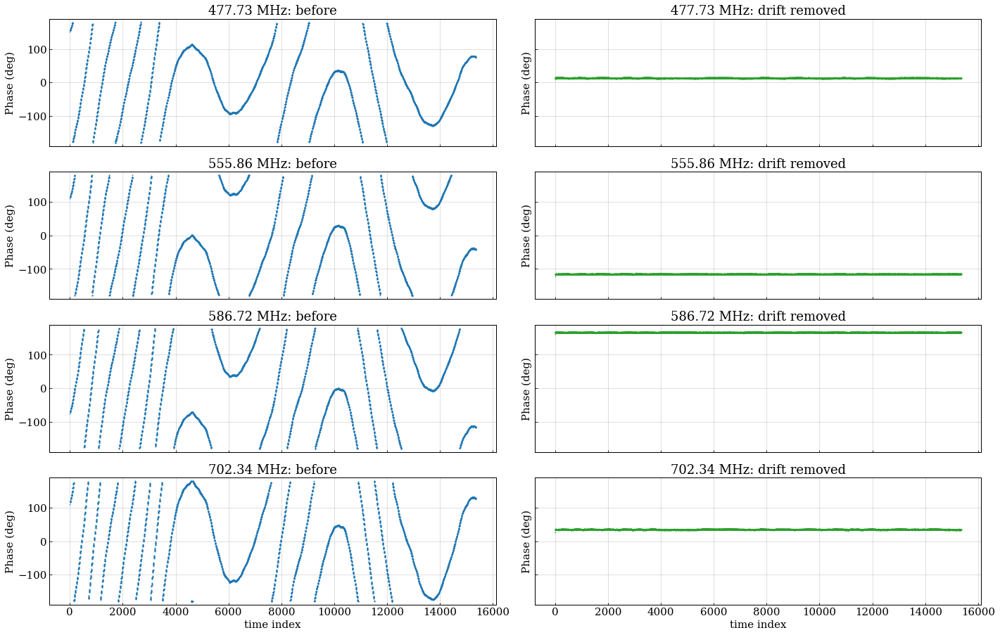

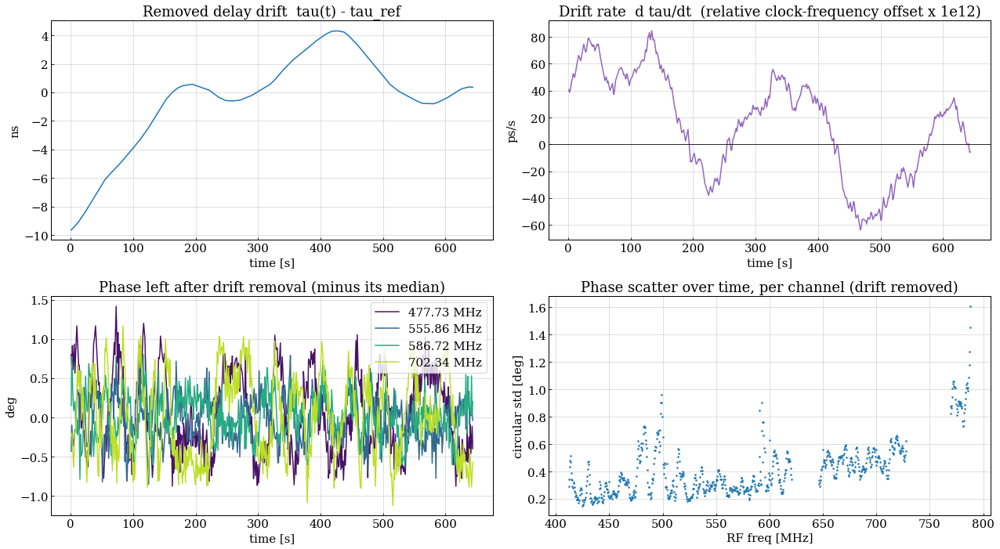

In [146]:
# =====================================================================
#  Delay-drift removal for the PULSING capture, block by block
#
#  Adapted from the notebook's estimate_delay / apply_correction, but with a NON-parametric
#  delay track tau(t) (one value per on-block) instead of "linear drift + toggling steps",
#  because the pulsing data wander up and down (no constant rate, no sample slips).
#
#  Run AFTER loading the PULSING-mode capture (corr_data = June2025_pulsing_mode...).
#  Self-contained: needs only corr_data, np, plt, pandas.  Run time ~ 10-30 s.
#
#  Model:  V01(f,t) ~ A * exp( i*[ 2*pi*f*tau(t) + theta(t) ] )
#  Output: tau(t) per block, V01_corr = V01 * exp(-2*pi*i*f*(tau(t) - tau_ref))
#          -> only the DRIFT is removed; the static delay tau_ref and the static phase stay,
#             so the corrected phase is still the physical phase response of the chain.
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
import pandas

# ------------------------------- config -------------------------------
FREQ_IDX     = [825, 625, 546, 250]    # 477.73, 555.86, 586.72, 702.34 MHz (used for plots + gate)
CROSS_IDX    = 1                       # (0,1)
AUTO_A_IDX   = 0                       # (0,0)
AUTO_B_IDX   = 4                       # (1,1): exactly 0 when the source is off -> clean gate
DELTA_TIME   = 0.04194304              # s / bin (fallback if irigb_time is unusable)

ON_FRAC      = 0.5                     # gate > this x on-level -> source on
FULL_FRAC    = 0.85                    # keep only bins > this x on-level (drops partial edge bins)
MIN_BINS     = 6                       # min kept bins per block (~11 expected)

MIN_COH      = 0.05                    # same channel selection as the notebook
MASK_RANGES  = [(80, 185), (395, 460)] # freq-index ranges excluded (RFI-ish), as in the notebook
EDGE_MHZ     = 12.0                    # mask Nyquist-edge aliasing
NFFT_PAD     = 16384                   # delay-transform length (same as notebook)
N_REFINE     = 201                     # fine-search points (same as notebook)
DIP_NSIGMA   = 6.0                     # block flagged bad if broadband coherence dips this far

N_PASS       = 2                       # 1 = estimate only; 2 = estimate, correct, re-estimate residual
REF          = "median"                # delay reference: "median" or "first" block
SAVE_CSV     = "pulsing_delay_track.csv"   # delay track for the later overlay with the clock record; None = skip
MAKE_VIS_CORR = False                  # True: also build a full corrected vis copy (uses a lot of RAM)
# ----------------------------------------------------------------------


# ------------------------------- notebook helpers (copied, unchanged logic) -------------------------------
def chan_freq_hz(nfreq):
    idx = np.arange(nfreq)
    return (400.0 + (1024 - idx) * 0.390625) * 1e6


def robust_sigma(x):
    x = np.asarray(x)[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x)))


def estimate_delay(V, freq_hz, w, nfft=NFFT_PAD, n_refine=N_REFINE):
    """Per-row delay from all channels: coherence-weighted delay transform (coarse FFT peak)
    + fine direct-DFT search with parabolic interpolation.  Returns tau [s], theta [rad]
    (phase at nu=0 after delay removal), normalised peak (broadband coherence), band centre."""
    order = np.argsort(freq_hz)
    f = freq_hz[order]
    wo = w[order]
    df = np.median(np.diff(f))
    nu_c = np.sum(f * wo) / np.sum(wo)
    fc = f - nu_c
    with np.errstate(divide="ignore", invalid="ignore"):
        z = V[:, order] / np.abs(V[:, order])
    z = np.where(np.isfinite(z), z, 0.0) * wo

    spec = np.abs(np.fft.fft(z, n=nfft, axis=1))
    m = np.argmax(spec, axis=1)
    m = np.where(m > nfft // 2, m - nfft, m)
    tau_coarse = m / (nfft * df)

    step = 1.0 / (nfft * df)
    grid = np.linspace(-1.5, 1.5, n_refine) * step
    dg = grid[1] - grid[0]
    n = V.shape[0]
    tau = np.full(n, np.nan); theta_c = np.full(n, np.nan); peak = np.full(n, np.nan)
    for i in range(n):
        if not np.any(z[i]):
            continue
        taus = tau_coarse[i] + grid
        s = np.exp(-2j * np.pi * np.outer(taus, fc)) @ z[i]
        a = np.abs(s)
        j = np.argmax(a)
        off = 0.0
        if 0 < j < n_refine - 1:
            den = a[j - 1] - 2 * a[j] + a[j + 1]
            if den != 0:
                off = 0.5 * (a[j - 1] - a[j + 1]) / den
        tau[i] = taus[j] + off * dg
        s_best = np.exp(-2j * np.pi * fc * tau[i]) @ z[i]
        theta_c[i] = np.angle(s_best)
        peak[i] = np.abs(s_best) / np.sum(wo)
    theta = np.angle(np.exp(1j * (theta_c - 2 * np.pi * nu_c * tau)))
    return tau, theta, peak, nu_c


def channel_weights_on(vis, idx_on, cross_idx, a_idx, b_idx, min_coh, mask_ranges):
    """Notebook's channel_weights, but the median coherence is taken over ON bins only
    (off bins have V = 0 and would spoil the median)."""
    V  = vis[idx_on, :, cross_idx]
    Pa = np.abs(vis[idx_on, :, a_idx]).astype(float)
    Pb = np.abs(vis[idx_on, :, b_idx]).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        coh = np.abs(V) / np.sqrt(Pa * Pb)
    coh_med = np.nanmedian(coh, axis=0)
    ok = np.isfinite(coh_med) & (coh_med > min_coh)
    for lo, hi in mask_ranges:
        ok[lo:hi] = False
    c = np.clip(np.nan_to_num(coh_med), 0, 0.99)
    w = np.where(ok, c ** 2 / (1 - c ** 2), 0.0)
    return w, ok


def correct_V(V, dtau_t, freq_hz, chunk=512):
    """V * exp(-2 pi i f dtau(t)) -- same sign convention as the notebook's apply_correction."""
    out = np.empty(V.shape, np.complex64)
    for a in range(0, V.shape[0], chunk):
        ph = 2 * np.pi * np.outer(dtau_t[a:a + chunk], freq_hz)
        out[a:a + chunk] = V[a:a + chunk] * np.exp(-1j * ph)
    return out


def block_mean(V, blocks):
    return np.array([V[b].mean(axis=0) for b in blocks])


def circ_std_deg(ph):
    R = np.abs(np.mean(np.exp(1j * ph), axis=0))
    return np.degrees(np.sqrt(-2 * np.log(np.clip(R, 1e-12, 1))))


# ------------------------------- time axis, channels -------------------------------
vis = corr_data.vis
nt, nf, _ = vis.shape
freq_hz = chan_freq_hz(nf)
fmhz = freq_hz / 1e6
try:
    t_abs_ns = np.asarray(corr_data.time["irigb_time"]).astype(np.int64)
    t_sec = (t_abs_ns - t_abs_ns[0]) * 1e-9
    t0_unix = t_abs_ns[0] * 1e-9
    assert np.all(np.diff(t_sec) > 0)
except Exception:
    print("irigb_time unusable -> using index * DELTA_TIME")
    t_sec = np.arange(nt) * DELTA_TIME
    t0_unix = np.nan
disp = list(FREQ_IDX)
lbl = [f"{fmhz[i]:.2f} MHz" for i in disp]

V01 = vis[:, :, CROSS_IDX]                                         # view (nt, nf)

# ------------------------------- on/off gate -> blocks -------------------------------
P11 = np.abs(vis[:, disp, AUTO_B_IDX]).astype(float)
gate = (P11 / np.percentile(P11, 99, axis=0)).sum(axis=1)
gate /= np.median(gate[gate > 0.5 * gate.max()])
on, full = gate > ON_FRAC, gate > FULL_FRAC
if not (0.3 < on.mean() < 0.7):
    raise RuntimeError(f"on-fraction = {on.mean():.2f}: not a ~50% duty-cycle pulsing capture. "
                       "Reload the pulsing-mode data (corr_data holds something else?).")
edges = np.flatnonzero(np.diff(np.r_[0, on.astype(int), 0]))
blocks = [np.arange(a, b)[full[a:b]] for a, b in zip(edges[0::2], edges[1::2])]
blocks = [b for b in blocks if len(b) >= MIN_BINS]
nb = len(blocks)
t_blk = np.array([t_sec[b].mean() for b in blocks])
print(f"{nb} blocks, {np.median([len(b) for b in blocks]):.0f} bins each, "
      f"pulse period {np.median(np.diff(t_blk)):.3f} s")

w, chan_ok = channel_weights_on(vis, np.concatenate(blocks), CROSS_IDX, AUTO_A_IDX, AUTO_B_IDX,
                                MIN_COH, MASK_RANGES)
chan_fit = chan_ok & (fmhz > 400 + EDGE_MHZ) & (fmhz < 800 - EDGE_MHZ)
w = np.where(chan_fit, w, 0.0)
print(f"channels used in the delay fit: {chan_fit.sum()} / {nf}")

# ------------------------------- delay track tau(t), block by block -------------------------------
Vb = block_mean(V01, blocks)                                        # (nb, nf) coherent block averages
tau, theta, peak, nu_c = estimate_delay(Vb, freq_hz, w)
bad = ~np.isfinite(tau) | (peak < np.nanmedian(peak) - DIP_NSIGMA * robust_sigma(peak))
good = ~bad
print(f"blocks flagged bad (coherence dip) and interpolated over: {bad.sum()}")
tau_est = np.interp(t_blk, t_blk[good], tau[good])                  # [s], absolute delay per block
tau_ref = tau_est[0] if REF == "first" else np.median(tau_est)


def dtau_per_bin(tau_blocks):
    return np.interp(t_sec, t_blk, tau_blocks - tau_ref)


for p in range(1, N_PASS):                                          # refine: correct, re-estimate residual
    Vc = correct_V(V01, dtau_per_bin(tau_est), freq_hz)
    tau2, _, peak2, _ = estimate_delay(block_mean(Vc, blocks), freq_hz, w)
    resid = np.where(good, tau2 - tau_ref, 0.0)                     # ~0 if the first estimate was exact
    print(f"pass {p}: residual delay after correction: rms {np.nanstd(resid[good]) * 1e12:.2f} ps, "
          f"max {np.nanmax(np.abs(resid[good])) * 1e12:.1f} ps")
    tau_est = tau_est + np.nan_to_num(resid)

dtau_blk = tau_est - tau_ref
V01_corr = correct_V(V01, dtau_per_bin(tau_est), freq_hz)            # (nt, nf) complex64
if MAKE_VIS_CORR:
    vis_corr = vis.copy(); vis_corr[:, :, CROSS_IDX] = V01_corr

# ------------------------------- numbers -------------------------------
rate_ps = np.gradient(tau_est, t_blk) * 1e12                         # ps/s
Vb_c = block_mean(V01_corr, blocks)
ph_c = np.angle(Vb_c)                                                # (nb, nf) rad, drift removed
print("\n=== drift that was removed ===")
print(f"tau_ref {tau_ref * 1e9:.3f} ns | delay excursion peak-to-peak {np.ptp(dtau_blk[good]) * 1e9:.2f} ns | "
      f"|d tau/dt| max {np.nanmax(np.abs(rate_ps[good])):.0f} ps/s")
print("\n=== phase after removal (block averages) ===")
for i, l in zip(disp, lbl):
    u = np.degrees(np.unwrap(ph_c[good, i]))          # flagged (interpolated) blocks excluded
    u -= np.median(u)
    print(f"{l}: circular std {circ_std_deg(ph_c[good][:, [i]])[0]:.2f} deg | peak-to-peak {np.ptp(u):.2f} deg")

if SAVE_CSV:
    pandas.DataFrame({"t_sec": t_blk, "unix_s": t0_unix + t_blk, "tau_abs_ns": tau_est * 1e9,
                      "dtau_ns": dtau_blk * 1e9, "bad_block": bad}).to_csv(SAVE_CSV, index=False)
    print(f"\ndelay track saved to {SAVE_CSV}  (for the overlay with the NAV-TO clock record)")

# ------------------------------- Fig 1: your original phase plot, before vs after -------------------------------
idx_axis = np.arange(nt)
fig1, ax = plt.subplots(len(disp), 2, figsize=(20, 3.2 * len(disp)), sharex=True, sharey=True)
ax = np.atleast_2d(ax)
for r, (i, l) in enumerate(zip(disp, lbl)):
    for c, (V, name) in enumerate([(V01, "before"), (V01_corr, "drift removed")]):
        ph = np.where(on, np.degrees(np.angle(V[:, i])), np.nan)        # off bins (V=0) hidden
        ax[r, c].plot(idx_axis, ph, ".", ms=1.5, c="tab:blue" if c == 0 else "tab:green")
        ax[r, c].set_title(f"{l}: {name}")
        ax[r, c].set_ylabel("Phase (deg)")
        ax[r, c].set_ylim(-190, 190)
ax[-1, 0].set_xlabel("time index"); ax[-1, 1].set_xlabel("time index")
fig1.tight_layout()
fig1.savefig(f"/Users/kalyanibhopi94/Downloads/June2025_pulsing_mode_time_stability_chamber/investigate_plots/24.png", dpi=300)

# ------------------------------- Fig 2: the removed delay + what is left -------------------------------
fig2, a2 = plt.subplots(2, 2, figsize=(18, 10))
a2[0, 0].plot(t_blk, dtau_blk * 1e9, c="tab:blue")
a2[0, 0].plot(t_blk[bad], dtau_blk[bad] * 1e9, "rx", label="interpolated blocks")
a2[0, 0].set_title("Removed delay drift  tau(t) - tau_ref")
a2[0, 0].set_ylabel("ns"); a2[0, 0].set_xlabel("time [s]")
if bad.any():
    a2[0, 0].legend()

a2[0, 1].plot(t_blk, rate_ps, c="tab:purple")
a2[0, 1].axhline(0, c="k", lw=0.8)
a2[0, 1].set_title("Drift rate  d tau/dt  (relative clock-frequency offset x 1e12)")
a2[0, 1].set_ylabel("ps/s"); a2[0, 1].set_xlabel("time [s]")

cols = plt.cm.viridis(np.linspace(0.05, 0.9, len(disp)))
for i, l, cc in zip(disp, lbl, cols):
    u = np.degrees(np.unwrap(ph_c[good, i])); u -= np.median(u)
    a2[1, 0].plot(t_blk[good], u, c=cc, label=l)
a2[1, 0].set_title("Phase left after drift removal (minus its median)")
a2[1, 0].set_ylabel("deg"); a2[1, 0].set_xlabel("time [s]"); a2[1, 0].legend()

sd = circ_std_deg(ph_c[good])
a2[1, 1].plot(fmhz[chan_fit], sd[chan_fit], ".", ms=3)
a2[1, 1].set_title("Phase scatter over time, per channel (drift removed)")
a2[1, 1].set_ylabel("circular std [deg]"); a2[1, 1].set_xlabel("RF freq [MHz]")
fig2.tight_layout()
fig2.savefig(f"/Users/kalyanibhopi94/Downloads/June2025_pulsing_mode_time_stability_chamber/investigate_plots/25.png", dpi=300)
plt.show()

result = dict(t_blk=t_blk, tau_est=tau_est, tau_ref=tau_ref, bad=bad, V01_corr=V01_corr, blocks=blocks)

Reading File: /Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20250609T180343Z/0025
Appended vis data and time stream from /Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20250609T180343Z/0025
Reading File: /Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20250609T180343Z/0026
Appended vis data and time stream from /Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20250609T180343Z/0026
Reading File: /Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20250609T180343Z/0027
Appended vis data and time stream from /Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20250609T180343Z/0027
Reading File: /Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20250609T180343Z/0028
Appended vis data and time stream from /Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20

/var/folders/g1/8y2gy6ys10d17y5j2rzwkwzc0000gn/T/ipykernel_27084/362563924.py:76: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cbar = fig.colorbar(im, cax=cax)


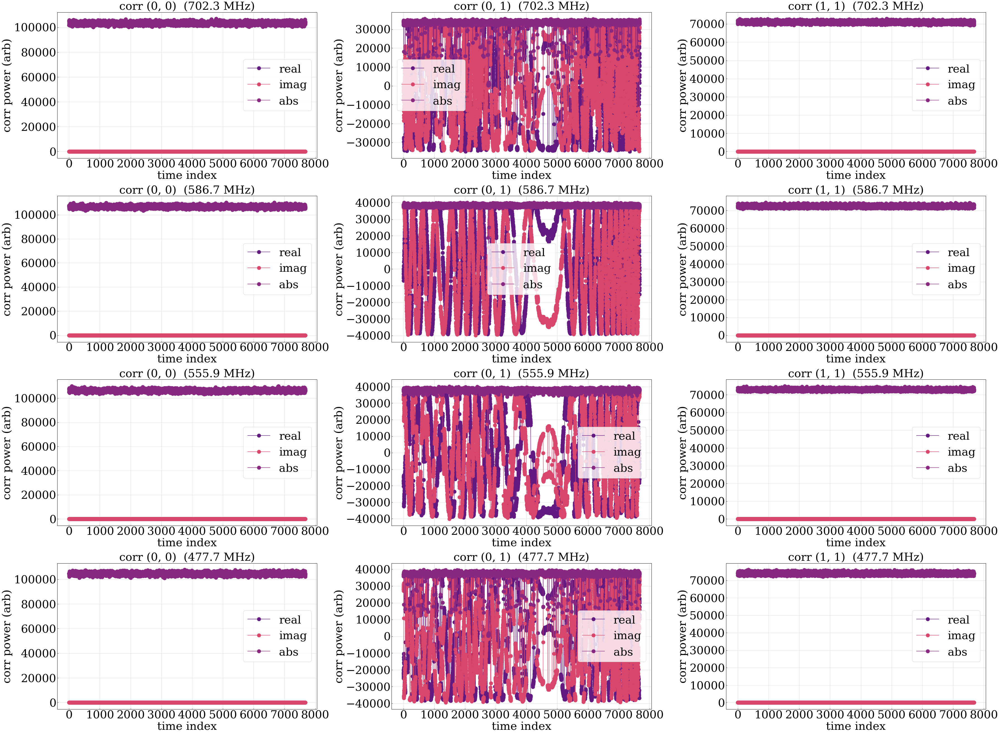

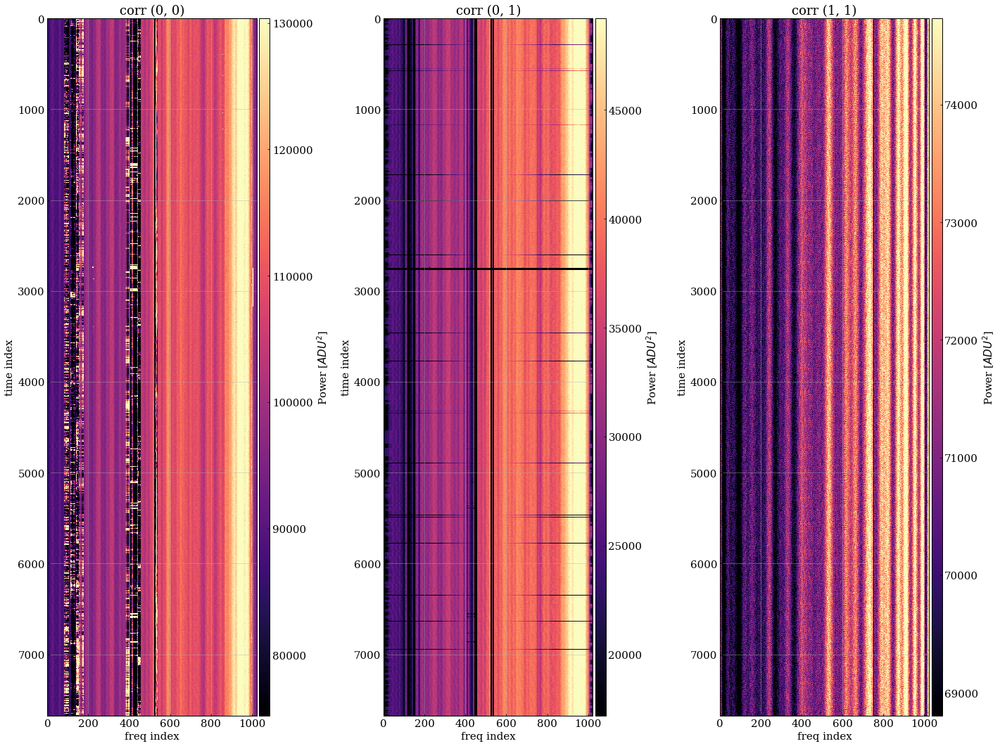

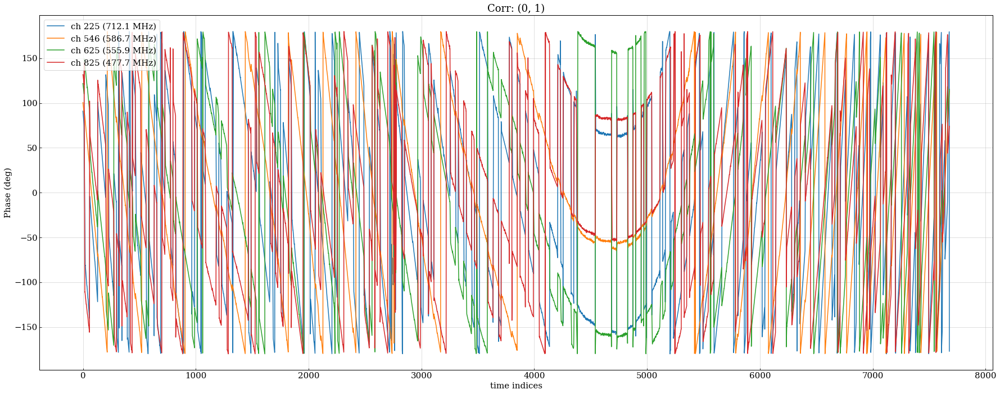

In [3]:
# =====================================================================
# Imports (read_corr_mode_h5 and get_mag_phase come from your own module)
# =====================================================================
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
# from your_module import read_corr_mode_h5, get_mag_phase

# =====================================================================
# Reading correlation files
# =====================================================================
file_path = '/Users/kalyanibhopi94/Downloads/June2025_cont_mode_time_stability_chamber/corr/20250609T180343Z/*'
f_start = 25
f_stop = 55
corr_data = read_corr_mode_h5(file_path, f_start, f_stop)
print("getting auto and cross-correlation magnitudes and phase")
pow_mag, pow_phase = get_mag_phase(corr_data.vis)
print("done getting pow_mag and pow_phase")
sat_data = corr_data.sat.real

corr_size = corr_data.vis[:, :, :].shape
print('corr data shape: {}'.format(corr_size))  # time bins - freq bins - corr indices

# =====================================================================
# Real / imag / abs vs time for a set of frequencies
# =====================================================================
tmin, tmax = [0, corr_size[0]]
freq_arr = [250, 546, 625, 825]
corr_indices = [0, 1, 4]
dim1 = math.floor(math.sqrt(len(corr_indices) * len(freq_arr)))
dim2 = math.ceil(len(corr_indices) * len(freq_arr) / dim1)
colorsarr = cm.magma(np.linspace(0, 1, 2048))
fig = plt.figure(figsize=[50, 40])
for index1, f_ind in enumerate(freq_arr):
    freq = 400 + ((1024 - f_ind) * 0.390625)
    for index2, corr_index in enumerate(corr_indices):
        panel_ind = index1 * len(corr_indices) + index2 + 1
        ax = plt.subplot(dim2, dim1, panel_ind)
        ax.plot(corr_data.vis.real[tmin:tmax, f_ind, corr_index], 'o-', markersize=13, c=colorsarr[600], label='real')
        ax.plot(corr_data.vis.imag[tmin:tmax, f_ind, corr_index], 'o-', markersize=13, c=colorsarr[1200], label='imag')
        ax.plot(pow_mag[tmin:tmax, f_ind, corr_index], 'o-', markersize=13, c=colorsarr[800], label='abs')
        ax.legend(fontsize=40)
        plt.xticks(fontsize=40)
        plt.yticks(fontsize=40)
        plt.title(f"corr {corr_data.prod[corr_index]}  ({freq:.1f} MHz)", fontsize=40)
        plt.xlabel("time index", fontsize=40)
        plt.ylabel("corr power (arb)", fontsize=40)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])

delta_time = np.diff(corr_data.time["irigb_time"])[1] * 1e-9
print(f"Each time bin is: {delta_time} seconds")
print(f"total time bins (considered for the plots) are {len(corr_data.vis[tmin:tmax, 0, 0])}")
print(f"lowest time bin {tmin} and highest time bin {tmax}")
print(f"{delta_time * len(corr_data.vis[tmin:tmax, 0, 0])} seconds of data (considered for the plots)")

# =====================================================================
# Waterfall
# =====================================================================
def plot_waterfall_corr_data(data, corr_indices, label='Power [$ADU^2$]', cmap='magma'):
    """Waterfall across 1024 frequency channels (400-800 MHz)."""
    fig = plt.figure(figsize=(20, 15))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices) / dim1)
    for i, auto in enumerate(corr_indices):
        ax = plt.subplot(dim1, dim2, i + 1)
        wfall = data[:, :, auto]
        im = plt.imshow(wfall, vmin=np.nanpercentile(wfall, 5), vmax=np.nanpercentile(wfall, 95),
                        cmap=cmap, aspect='auto', interpolation='nearest')
        plt.xlabel("freq index")
        plt.ylabel("time index")
        plt.title(f"corr {corr_data.prod[auto]}")
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        cbar = fig.colorbar(im, cax=cax)
        cbar.set_label(label)
    plt.tight_layout()

plot_waterfall_corr_data(pow_mag[:, :, :], [0, 1, 4])

# =====================================================================
# Phase vs time for chosen channels
# =====================================================================
def plot_freq_channel_corr_data(pow_phase, freq_index, corr_indices):
    plt.figure(figsize=(25, 10))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices) / dim1)
    for index, corr_index in enumerate(corr_indices):
        plt.subplot(dim1, dim2, index + 1)
        plt.title(f"Corr: {corr_data.prod[corr_index]}")
        plt.plot(pow_phase[:, freq_index, corr_index])
        plt.legend([f"ch {c} ({400 + (1024 - c) * 0.390625:.1f} MHz)" for c in freq_index])
        plt.xlabel("time indices")
        plt.ylabel("Phase (deg)")
    plt.tight_layout()

frequency_index = [225, 546, 625, 825]
plot_freq_channel_corr_data(pow_phase, frequency_index, [1])


# #####################################################################
#  CLOCK-SLIP MODEL: ±Δτ toggling delay step + linear delay drift
#
#  Phase model on the cross-correlation:
#      φ(ν, t) = 2π ν τ(t) + θ(t)
#      τ(t)    = τ0 + r·t + Δτ·s(t)
#      θ(t)    = θ0 + Δθ·s(t)          s(t) ∈ {0,1}, flips at each event
#  r  = fractional clock-rate offset between the two boards (s/s)
#  Δτ = slip size;  Δθ ≈ 0 (mod 360) means it's a pure sample/delay slip
# #####################################################################

# ---------------- user settings ----------------
CROSS_IDX    = 1                      # corr index of (0,1)
AUTO_A_IDX   = 0                      # (0,0)
AUTO_B_IDX   = 4                      # (1,1)
FS_ADC       = 800e6                  # ASSUMED effective sample rate, only used to express Δτ in samples
MASK_RANGES  = [(80, 185), (395, 460)]  # freq-index ranges to exclude from the delay fit (RFI-ish in (0,0)); edit
MIN_COH      = 0.05                   # drop channels with median coherence below this
NFFT_PAD     = 16384                  # zero-padded delay transform length
N_REFINE     = 201                    # fine-search points around the coarse delay peak
JUMP_NSIGMA  = 8.0                    # jump threshold in robust sigmas of bin-to-bin delay change
DIP_NSIGMA   = 6.0                    # coherence-dip threshold (flags bins where the step landed mid-integration)
MODE         = "free"               # "toggle" (one shared ±Δτ) or "free" (each step its own size)
REMOVE_DRIFT = True                   # False = remove only the steps, keep r·t (use for stability analysis)
PLOT_CHANS   = [225, 546, 625, 825]


def chan_freq_hz(nfreq):
    idx = np.arange(nfreq)
    return (400.0 + (1024 - idx) * 0.390625) * 1e6


def robust_sigma(x):
    x = np.asarray(x)[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x)))


def channel_weights(vis, cross_idx, a_idx, b_idx, min_coh, mask_ranges):
    """Per-channel weights ~ phase SNR^2, from median coherence |V01|/sqrt(P0 P1)."""
    V = vis[:, :, cross_idx]
    Pa = np.abs(vis[:, :, a_idx].real)
    Pb = np.abs(vis[:, :, b_idx].real)
    with np.errstate(divide="ignore", invalid="ignore"):
        coh = np.abs(V) / np.sqrt(Pa * Pb)
    coh_med = np.nanmedian(coh, axis=0)
    ok = np.isfinite(coh_med) & (coh_med > min_coh)
    for lo, hi in mask_ranges:
        ok[lo:hi] = False
    c = np.clip(np.nan_to_num(coh_med), 0, 0.99)
    w = np.where(ok, c**2 / (1 - c**2), 0.0)
    return w, coh, ok


def estimate_delay(V, freq_hz, w, nfft=NFFT_PAD, n_refine=N_REFINE):
    """
    Per-time-bin delay from all channels: coherence-weighted delay transform
    (coarse FFT peak) + fine direct-DFT search with parabolic interpolation.
    Returns tau(t) [s], theta_inst(t) [rad] (phase at nu=0 after delay removal),
    normalised peak height (broadband coherence proxy), weighted band centre.
    """
    order = np.argsort(freq_hz)
    f = freq_hz[order]
    wo = w[order]
    df = np.median(np.diff(f))
    nu_c = np.sum(f * wo) / np.sum(wo)
    fc = f - nu_c                      # centred freq -> decorrelates tau and theta
    with np.errstate(divide="ignore", invalid="ignore"):
        z = V[:, order] / np.abs(V[:, order])
    z = np.where(np.isfinite(z), z, 0.0) * wo

    spec = np.abs(np.fft.fft(z, n=nfft, axis=1))
    m = np.argmax(spec, axis=1)
    m = np.where(m > nfft // 2, m - nfft, m)
    tau_coarse = m / (nfft * df)

    step = 1.0 / (nfft * df)
    grid = np.linspace(-1.5, 1.5, n_refine) * step
    dg = grid[1] - grid[0]
    nt = V.shape[0]
    tau = np.full(nt, np.nan)
    theta_c = np.full(nt, np.nan)
    peak = np.full(nt, np.nan)
    for i in range(nt):
        if not np.any(z[i]):
            continue
        taus = tau_coarse[i] + grid
        s = np.exp(-2j * np.pi * np.outer(taus, fc)) @ z[i]
        a = np.abs(s)
        j = np.argmax(a)
        off = 0.0
        if 0 < j < n_refine - 1:
            den = a[j - 1] - 2 * a[j] + a[j + 1]
            if den != 0:
                off = 0.5 * (a[j - 1] - a[j + 1]) / den
        tau[i] = taus[j] + off * dg
        s_best = np.exp(-2j * np.pi * fc * tau[i]) @ z[i]
        theta_c[i] = np.angle(s_best)
        peak[i] = np.abs(s_best) / np.sum(wo)
    # convert band-centre phase to the phase of the full model φ = 2πντ + θ
    theta_inst = np.angle(np.exp(1j * (theta_c - 2 * np.pi * nu_c * tau)))
    return tau, theta_inst, peak, nu_c


def detect_events(tau, t_sec, peak, jump_nsigma=JUMP_NSIGMA, dip_nsigma=DIP_NSIGMA):
    """
    Events = delay jumps between clean bins (after removing median drift).
    Bins with a coherence dip, or bins sitting between two consecutive partial
    jumps, are flagged corrupted (step happened inside that integration).
    """
    valid = np.isfinite(tau)
    pk_med, pk_sig = np.nanmedian(peak), robust_sigma(peak)
    dip = valid & (peak < pk_med - dip_nsigma * pk_sig)
    corrupted = dip | ~valid

    good = np.where(~corrupted)[0]
    dt = np.diff(t_sec[good])
    dtau = np.diff(tau[good])
    rate0 = np.median(dtau / dt)
    resid = dtau - rate0 * dt
    sig = robust_sigma(resid)
    jk = np.where(np.abs(resid - np.median(resid)) > jump_nsigma * sig)[0]

    events = []
    if len(jk):
        groups = np.split(jk, np.where(np.diff(jk) > 1)[0] + 1)
        for g in groups:
            before, after = good[g[0]], good[g[-1] + 1]
            corrupted[good[g[0] + 1: g[-1] + 1]] = True   # interior partial-step bins
            events.append(dict(before=int(before), after=int(after), jump=float(resid[g].sum())))
    return events, corrupted, rate0, sig


def build_state(nt, events, mode):
    seg = np.zeros(nt, dtype=int)                 # number of events passed
    for ev in events:
        seg[ev["after"]:] += 1
    if mode == "toggle":
        S = (seg % 2).astype(float)[:, None]
    else:
        S = np.zeros((nt, len(events)))
        for k, ev in enumerate(events):
            S[ev["after"]:, k] = 1.0
    return S, seg


def fit_model(tau, theta_inst, t_sec, S, seg, use, mode):
    X = np.column_stack([np.ones_like(t_sec), t_sec, S])
    coef, *_ = np.linalg.lstsq(X[use], tau[use], rcond=None)
    tau0, rate, dtaus = coef[0], coef[1], coef[2:]
    tau_model = X @ coef
    tau_resid = tau - tau_model

    # θ: circular mean per state (toggle) or per segment (free)
    key = (seg % 2) if mode == "toggle" else seg
    theta_lvls = {}
    for k in np.unique(key[use]):
        sel = use & (key == k)
        theta_lvls[k] = np.angle(np.mean(np.exp(1j * theta_inst[sel])))
    theta0 = theta_lvls[key[use][0]]
    theta_model = np.array([theta_lvls.get(k, np.nan) for k in key])
    return dict(tau0=tau0, rate=rate, dtaus=dtaus, tau_model=tau_model,
                tau_resid=tau_resid, theta0=theta0, theta_model=theta_model,
                theta_lvls=theta_lvls)


def apply_correction(V, freq_hz, t_sec, fit, corrupted, remove_drift):
    dtau = fit["tau_model"] - fit["tau0"]
    if not remove_drift:
        dtau = dtau - fit["rate"] * t_sec
    dth = np.nan_to_num(fit["theta_model"] - fit["theta0"])
    ph = 2 * np.pi * np.outer(dtau, freq_hz) + dth[:, None]
    Vc = V * np.exp(-1j * ph)
    Vc[corrupted, :] = np.nan + 1j * np.nan
    return Vc


channels used in delay fit: 854 / 1024

=== delay model fit ===
per-bin delay noise (robust):      4.63 ps
tau0:                              129.0001 ns
drift rate r (fractional offset):  1.305e-11 s/s  -> 13.1 ps/s, 4204 ps over capture
   predicted phase drift ch 225 (712.1 MHz): 0.140 deg/bin
   predicted phase drift ch 546 (586.7 MHz): 0.116 deg/bin
   predicted phase drift ch 625 (555.9 MHz): 0.110 deg/bin
   predicted phase drift ch 825 (477.7 MHz): 0.094 deg/bin
step 0: Δτ = -2372.23 ps = -1.8978 samples
step 1: Δτ = -1555.27 ps = -1.2442 samples
step 2: Δτ = 1968.50 ps = 1.5748 samples
step 3: Δτ = -3679.34 ps = -2.9435 samples
step 4: Δτ = 4276.44 ps = 3.4212 samples
step 5: Δτ = -2344.85 ps = -1.8759 samples
step 6: Δτ = -1518.87 ps = -1.2151 samples
step 7: Δτ = 1826.93 ps = 1.4615 samples
step 8: Δτ = -3890.41 ps = -3.1123 samples
step 9: Δτ = 4095.98 ps = 3.2768 samples
step 10: Δτ = -3846.08 ps = -3.0769 samples
step 11: Δτ = 4206.21 ps = 3.3650 samples
step 12: Δτ = -39

/var/folders/g1/8y2gy6ys10d17y5j2rzwkwzc0000gn/T/ipykernel_27084/1670107806.py:107: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  plt.colorbar(im, ax=a, label='Phase [deg]')


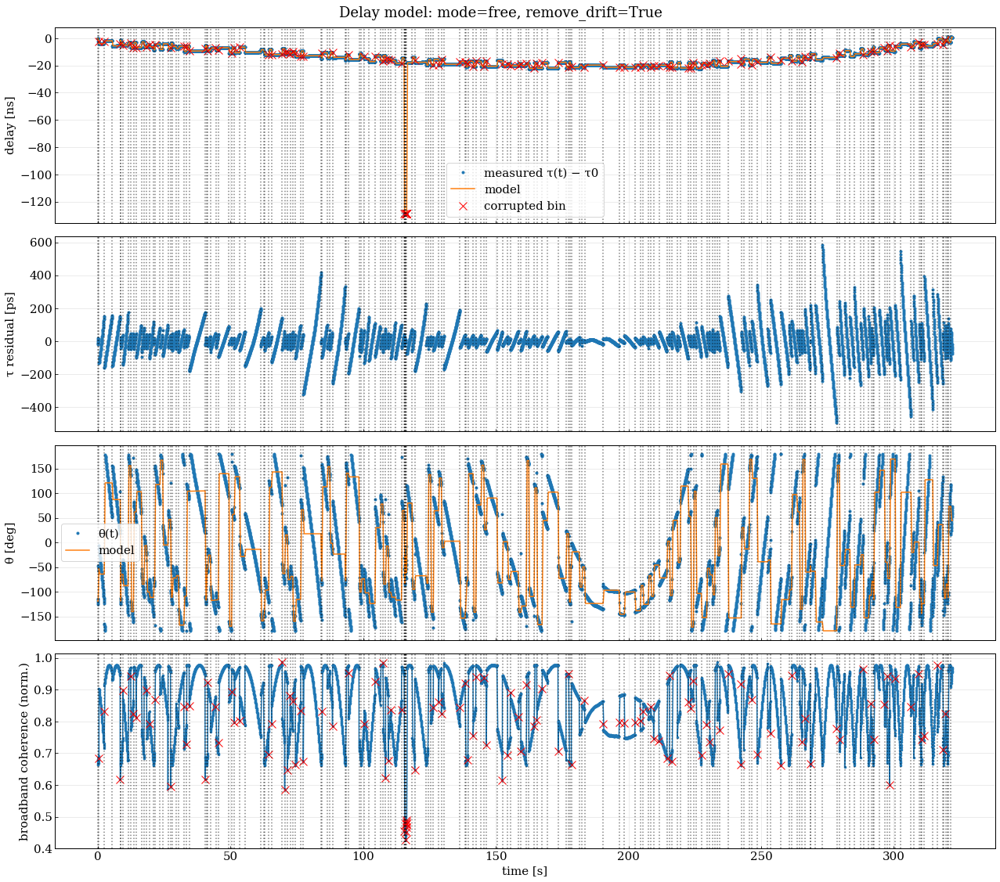

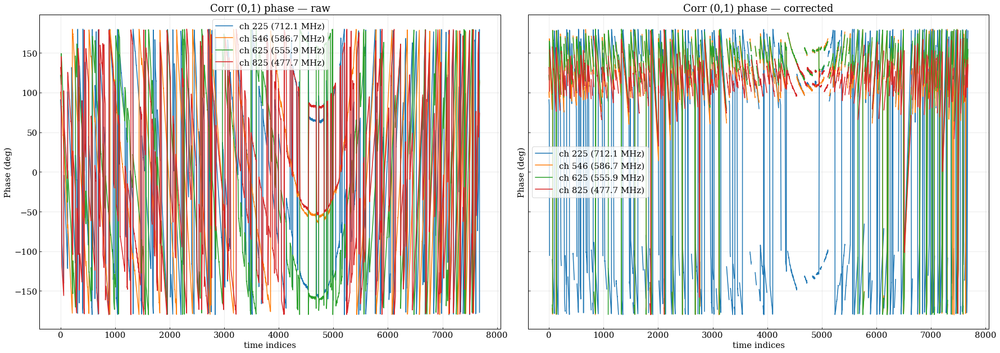

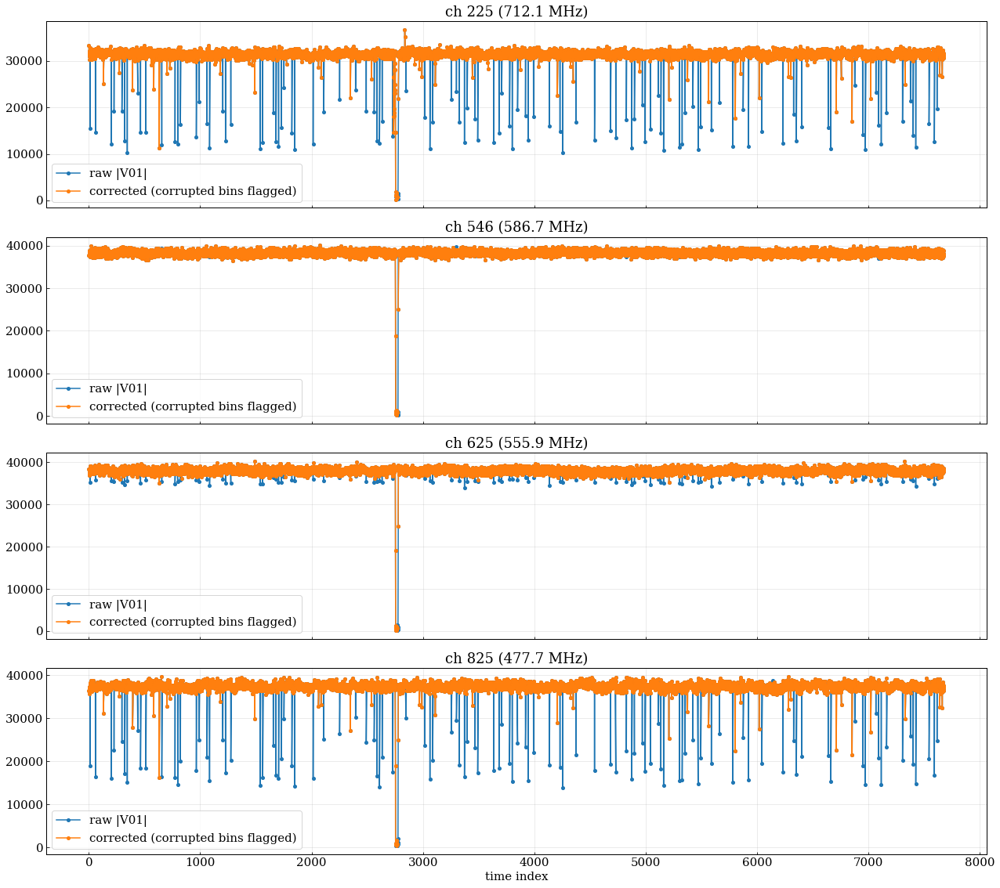

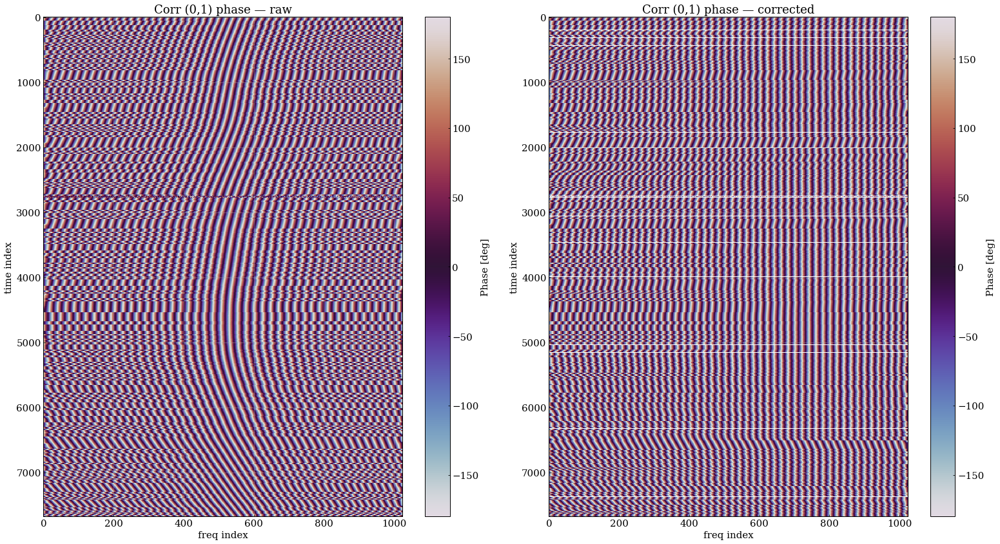

In [6]:
# ---------------- run ----------------
vis = corr_data.vis
nt, nf, _ = vis.shape
freq_hz = chan_freq_hz(nf)
t_abs_ns = np.asarray(corr_data.time["irigb_time"]).astype(np.int64)
t_sec = (t_abs_ns - t_abs_ns[0]) * 1e-9
V01 = vis[:, :, CROSS_IDX].astype(np.complex128)

w, coh, chan_ok = channel_weights(vis, CROSS_IDX, AUTO_A_IDX, AUTO_B_IDX, MIN_COH, MASK_RANGES)
print(f"channels used in delay fit: {chan_ok.sum()} / {nf}")

tau, theta_inst, peak, nu_c = estimate_delay(V01, freq_hz, w)
events, corrupted, rate0, tau_sig = detect_events(tau, t_sec, peak)
S, seg = build_state(nt, events, MODE)
use = ~corrupted & np.isfinite(tau)
fit = fit_model(tau, theta_inst, t_sec, S, seg, use, MODE)
V01_corr = apply_correction(V01, freq_hz, t_sec, fit, corrupted, REMOVE_DRIFT)

# corrected copy of the full visibility array (only (0,1) is corrected;
# other baselines involving input 0 need the same treatment)
vis_corr = vis.copy()
vis_corr[:, :, CROSS_IDX] = V01_corr

# ---------------- report ----------------
print("\n=== delay model fit ===")
print(f"per-bin delay noise (robust):      {tau_sig*1e12:.2f} ps")
print(f"tau0:                              {fit['tau0']*1e9:.4f} ns")
print(f"drift rate r (fractional offset):  {fit['rate']:.3e} s/s  "
      f"-> {fit['rate']*1e12:.1f} ps/s, {fit['rate']*t_sec[-1]*1e12:.0f} ps over capture")
for ch in PLOT_CHANS:
    print(f"   predicted phase drift ch {ch} ({freq_hz[ch]/1e6:.1f} MHz): "
          f"{360*freq_hz[ch]*fit['rate']*delta_time:.3f} deg/bin")
if MODE == "toggle" and len(fit["dtaus"]):
    d = fit["dtaus"][0]
    lv = fit["theta_lvls"]
    dth = np.degrees(np.angle(np.exp(1j * (lv.get(1, np.nan) - lv.get(0, np.nan))))) if 1 in lv else np.nan
    print(f"toggle step Δτ:                    {d*1e12:.2f} ps = {d*FS_ADC:.4f} samples @ {FS_ADC/1e6:.0f} MSPS")
    print(f"toggle step Δθ:                    {dth:.2f} deg   (≈0 => pure delay/sample slip)")
elif MODE == "free":
    for k, d in enumerate(fit["dtaus"]):
        print(f"step {k}: Δτ = {d*1e12:.2f} ps = {d*FS_ADC:.4f} samples")

print(f"\n=== events ({len(events)}) ===")
print(" #  bins(before->after)  t[s]     frac-of-second   jump[ps]")
for k, ev in enumerate(events):
    b = ev["after"]
    frac = (t_abs_ns[b] % 1_000_000_000) / 1e9
    print(f"{k:2d}  {ev['before']:4d} -> {ev['after']:4d}      {t_sec[b]:7.3f}   {frac:.4f}          {ev['jump']*1e12:+.1f}")
if len(events) > 1:
    gaps = np.diff([t_sec[ev["after"]] for ev in events])
    print("gaps between events [s]:", np.round(gaps, 3), " | offset from nearest integer s:",
          np.round(gaps - np.round(gaps), 3))
    signs = np.sign([ev["jump"] for ev in events])
    if MODE == "toggle" and np.any(signs[1:] == signs[:-1]):
        print("WARNING: jump signs do not strictly alternate -> toggle model is wrong for this data; try MODE='free'.")
print(f"corrupted (NaN'd) bins: {np.where(corrupted)[0].tolist()}")

# ---------------- diagnostic plots ----------------
ev_bins = [ev["after"] for ev in events]
fig, axs = plt.subplots(4, 1, figsize=(18, 16), sharex=True)
axs[0].plot(t_sec, (tau - fit["tau0"]) * 1e9, '.', ms=6, label='measured τ(t) − τ0')
axs[0].plot(t_sec, (fit["tau_model"] - fit["tau0"]) * 1e9, '-', lw=1.5, label='model')
axs[0].plot(t_sec[corrupted], (tau[corrupted] - fit["tau0"]) * 1e9, 'rx', ms=10, label='corrupted bin')
axs[0].set_ylabel('delay [ns]'); axs[0].legend()
axs[1].plot(t_sec[use], fit["tau_resid"][use] * 1e12, '.', ms=6)
axs[1].set_ylabel('τ residual [ps]')
axs[2].plot(t_sec, np.degrees(theta_inst), '.', ms=6, label='θ(t)')
axs[2].plot(t_sec, np.degrees(fit["theta_model"]), '-', label='model')
axs[2].set_ylabel('θ [deg]'); axs[2].legend()
axs[3].plot(t_sec, peak, '.-', ms=5)
axs[3].plot(t_sec[corrupted], peak[corrupted], 'rx', ms=10)
axs[3].set_ylabel('broadband coherence (norm.)'); axs[3].set_xlabel('time [s]')
for a in axs:
    for b in ev_bins:
        a.axvline(t_sec[b], color='k', ls=':', alpha=0.5)
    a.grid(alpha=0.3)
fig.suptitle(f"Delay model: mode={MODE}, remove_drift={REMOVE_DRIFT}")
fig.tight_layout()

# phase before / after for chosen channels
fig, axs = plt.subplots(1, 2, figsize=(25, 9), sharey=True)
for ch in PLOT_CHANS:
    lab = f"ch {ch} ({freq_hz[ch]/1e6:.1f} MHz)"
    axs[0].plot(np.degrees(np.angle(V01[:, ch])), label=lab)
    axs[1].plot(np.degrees(np.angle(V01_corr[:, ch])), label=lab)
axs[0].set_title("Corr (0,1) phase — raw"); axs[1].set_title("Corr (0,1) phase — corrected")
for a in axs:
    a.set_xlabel("time indices"); a.set_ylabel("Phase (deg)"); a.legend(); a.grid(alpha=0.3)
fig.tight_layout()

# magnitude before / after (corrupted bins NaN'd; un-corrupted bins are unchanged by a phase-only correction)
fig, axs = plt.subplots(len(PLOT_CHANS), 1, figsize=(18, 4 * len(PLOT_CHANS)), sharex=True)
for a, ch in zip(np.atleast_1d(axs), PLOT_CHANS):
    a.plot(np.abs(V01[:, ch]), 'o-', ms=4, label='raw |V01|')
    a.plot(np.abs(V01_corr[:, ch]), 'o-', ms=4, label='corrected (corrupted bins flagged)')
    a.set_title(f"ch {ch} ({freq_hz[ch]/1e6:.1f} MHz)"); a.legend(); a.grid(alpha=0.3)
np.atleast_1d(axs)[-1].set_xlabel("time index")
fig.tight_layout()

# phase waterfalls raw vs corrected
phase_raw = np.degrees(np.angle(V01))[:, :, None]
phase_cor = np.degrees(np.angle(V01_corr))[:, :, None]
fig, axs = plt.subplots(1, 2, figsize=(22, 12))
for a, ph, ttl in zip(axs, [phase_raw, phase_cor], ["raw", "corrected"]):
    im = a.imshow(ph[:, :, 0], vmin=-180, vmax=180, cmap='twilight', aspect='auto', interpolation='nearest')
    a.set_title(f"Corr (0,1) phase — {ttl}"); a.set_xlabel("freq index"); a.set_ylabel("time index")
    plt.colorbar(im, ax=a, label='Phase [deg]')
fig.tight_layout()

direct dτ/dt = -1.275e-10 s/s   (broadband fit gave 1.305e-11)
intercept    = -3.6 deg/s        (pure delay drift => ~0)


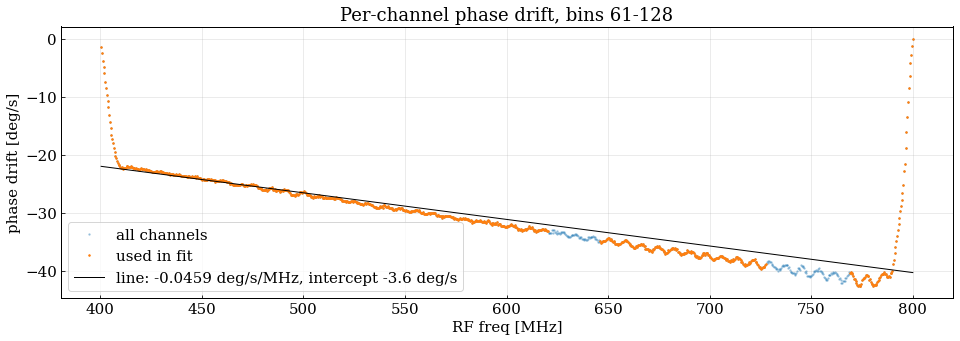




In [7]:
# ---------- Diagnostic A: per-channel phase drift rate vs frequency ----------
seg = slice(61, 129)                      # clean segment between events 2 and 3
tt = t_sec[seg] - t_sec[seg].mean()
ph = np.unwrap(np.angle(V01[seg, :]), axis=0)          # (ntime, nchan)
A = np.vstack([tt, np.ones_like(tt)]).T
rate_deg = np.degrees(np.linalg.lstsq(A, ph, rcond=None)[0][0])   # deg/s per channel

fmhz = freq_hz / 1e6
p = np.polyfit(fmhz[chan_ok], rate_deg[chan_ok], 1)
plt.figure(figsize=(16, 5))
plt.plot(fmhz, rate_deg, '.', ms=3, alpha=0.3, label='all channels')
plt.plot(fmhz[chan_ok], rate_deg[chan_ok], '.', ms=3, label='used in fit')
plt.plot(fmhz, np.polyval(p, fmhz), 'k-', lw=1,
         label=f'line: {p[0]:.4f} deg/s/MHz, intercept {p[1]:.1f} deg/s')
plt.xlabel('RF freq [MHz]'); plt.ylabel('phase drift [deg/s]'); plt.legend(); plt.grid(alpha=.3)
plt.title('Per-channel phase drift, bins 61-128')
print(f"direct dτ/dt = {p[0]/360/1e6:.3e} s/s   (broadband fit gave {fit['rate']:.3e})")
print(f"intercept    = {p[1]:.1f} deg/s        (pure delay drift => ~0)")

# ---------- Diagnostic B: phase step vs frequency at each event ----------
order = np.argsort(freq_hz)
fig, axs = plt.subplots(len(events), 1, figsize=(16, 3 * len(events)), sharex=True)
for a, (k, ev) in zip(np.atleast_1d(axs), enumerate(events)):
    pre, post = V01[ev['before']], V01[ev['after']]
    dphi = np.unwrap(np.angle(post * np.conj(pre))[order])
    f_s, ok_s = fmhz[order], chan_ok[order]
    q = np.polyfit(f_s[ok_s], dphi[ok_s], 1)
    a.plot(f_s, np.degrees(dphi), '.', ms=2)
    a.plot(f_s, np.degrees(np.polyval(q, f_s)), 'k-', lw=1)
    a.set_ylabel('Δφ [deg]'); a.grid(alpha=.3)
    a.set_title(f"event {k} (bins {ev['before']}->{ev['after']}): "
                f"Δτ = {q[0]/(2*np.pi*1e6)*1e9:+.3f} ns, offset {np.degrees(q[1]) % 360:.1f} deg")
np.atleast_1d(axs)[-1].set_xlabel('RF freq [MHz]')
fig.tight_layout()

channels used: 793 / 1024  (412.1-787.9 MHz)

=== pair-differenced model ===
pair fit residual (across freq, median): 1.05 deg
drift r:      -3.7785e-12 s/s  (-3.8 ps/s; -1217 ps over capture)
θ̇:            -0.02 deg/s   (pure delay drift => ~0)
slip Δτ:      -3.2557 ns
slip Δθ:      -25.40 deg      (pure delay slip => ~0)
Δτ in clock periods: 0.651 @ 200 MHz, 0.814 @ 250 MHz, 0.977 @ 300 MHz, 1.302 @ 400 MHz, 2.605 @ 800 MHz, 3.907 @ 1200 MHz, 5.209 @ 1600 MHz, 7.814 @ 2400 MHz, 8.001 @ 2457.6 MHz, 10.418 @ 3200 MHz
pair delay residual rms: 5.08 ps   phase residual rms: 0.21 deg

=== slips (160) ===
 bins      t[s]    frac-of-s   dτ-drift[ns]   resid[ps]   dθ[deg]
  10->  12   0.503   0.9388     -3.2708         -15.0      -24.5
  58->  60   2.517   0.9520     +3.2390         -16.7      +26.0
 129-> 131   5.495   0.9300     -3.2674         -11.7      -25.5
 201-> 203   8.514   0.9499     +3.2414         -14.4      +25.9
 225-> 227   9.521   0.9565     -3.2670         -11.2      -25.3



Validation A: median |residual drift| in fit band = 2.38 deg/s


/var/folders/g1/8y2gy6ys10d17y5j2rzwkwzc0000gn/T/ipykernel_27084/1626363015.py:153: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  plt.colorbar(im, ax=a, label='Phase [deg]')


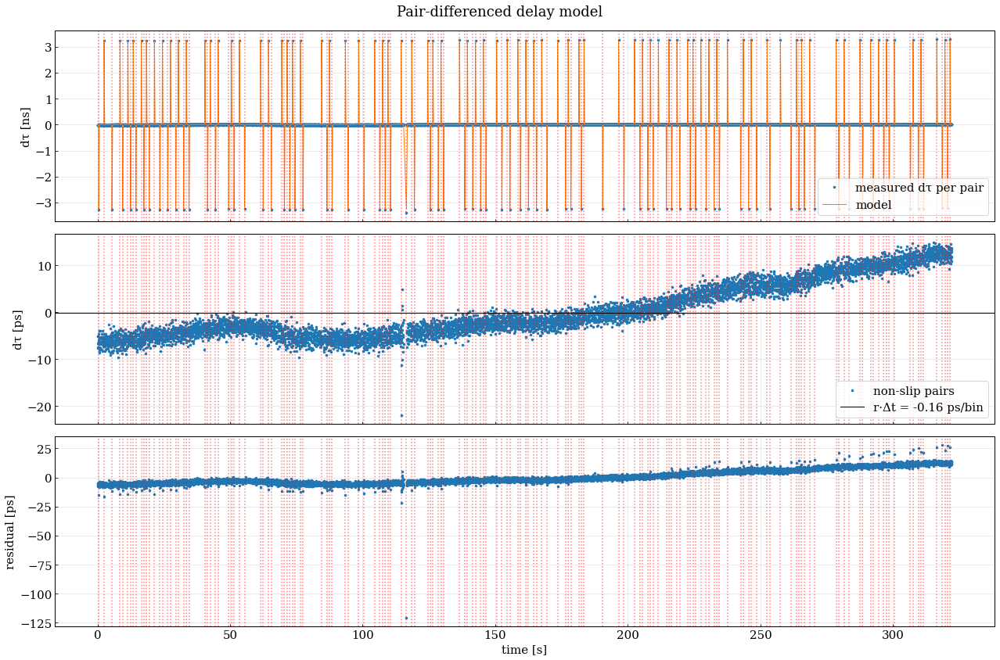

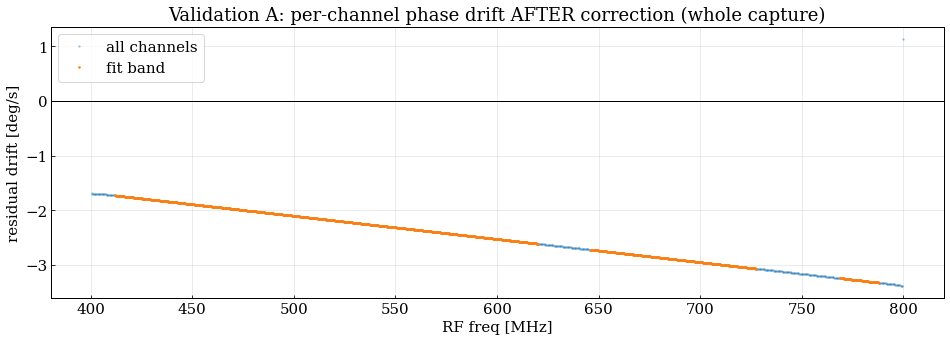




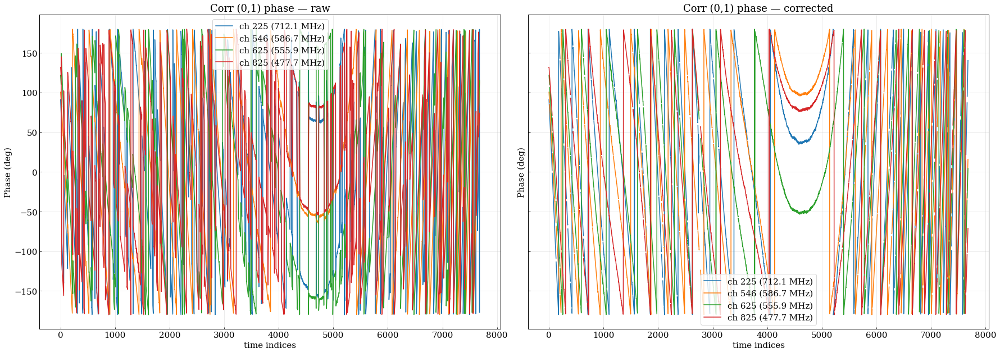

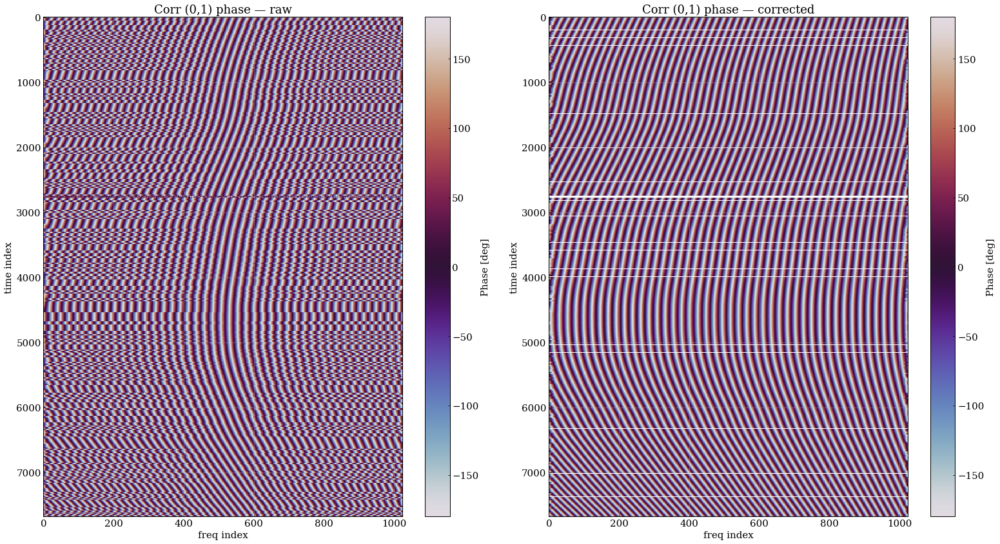

In [8]:
# =====================================================================
#  DIRECT PAIR-DIFFERENCED DELAY MODEL  (replaces the broadband estimator)
#  For consecutive clean bins (a, b):
#     Δφ_ab(ν) = angle(V_b · conj(V_a)) ≈ 2π ν dτ_ab + dθ_ab
#  Model:  dτ_ab = r·Δt_ab + Δτ·Δs_ab ,   dθ_ab = θ̇·Δt_ab + Δθ·Δs_ab
#  s(t) ∈ {0,1} toggles at each PPS-locked slip.
# =====================================================================
EDGE_MHZ     = 12.0      # mask Nyquist-edge aliasing
STEP_NS      = 0.5       # pair delay change (drift removed) above this = slip
DIP_NSIGMA   = 6.0
REMOVE_DRIFT = True      # False: remove only the slips (keep r·t for stability work)
CLOCK_CANDIDATES_HZ = [200e6, 250e6, 300e6, 400e6, 800e6, 1.2e9, 1.6e9, 2.4e9, 2.4576e9, 3.2e9]
PLOT_CHANS   = [225, 546, 625, 825]

fmhz = freq_hz / 1e6
chan_fit = chan_ok & (fmhz > 400 + EDGE_MHZ) & (fmhz < 800 - EDGE_MHZ)
order_fit = np.argsort(freq_hz)
order_fit = order_fit[chan_fit[order_fit]]          # ascending freq, fit channels only
f_fit = freq_hz[order_fit]
print(f"channels used: {len(order_fit)} / {nf}  ({f_fit.min()/1e6:.1f}-{f_fit.max()/1e6:.1f} MHz)")


def pair_delta(Va, Vb):
    """Linear fit of the phase change across frequency. Returns dτ [s], dθ at ν=0 [rad], rms resid [deg]."""
    d = np.unwrap(np.angle(Vb[order_fit] * np.conj(Va[order_fit])))
    q = np.polyfit(f_fit, d, 1)
    res = d - np.polyval(q, f_fit)
    return q[0] / (2 * np.pi), np.angle(np.exp(1j * q[1])), np.degrees(np.std(res))


# ---- clean bins: drop bins where a slip landed mid-integration (broadband coherence dip)
coh_t = np.nanmean(coh[:, chan_fit], axis=1)
bad = coh_t < np.nanmedian(coh_t) - DIP_NSIGMA * robust_sigma(coh_t)
good = np.where(~bad)[0]
a_idx, b_idx = good[:-1], good[1:]
dt = t_sec[b_idx] - t_sec[a_idx]

npair = len(a_idx)
dtau = np.empty(npair); dth = np.empty(npair); rres = np.empty(npair)
for k, (a, b) in enumerate(zip(a_idx, b_idx)):
    dtau[k], dth[k], rres[k] = pair_delta(V01[a], V01[b])

# ---- slips
rate_med = np.median(dtau / dt)
step_k = np.where(np.abs(dtau - rate_med * dt) > STEP_NS * 1e-9)[0]
ds = np.zeros(npair); s_cur = 0
for k in step_k:
    ds[k] = +1 if s_cur == 0 else -1
    s_cur = 1 - s_cur
sgn = np.sign(dtau[step_k] - rate_med * dt[step_k])
if len(sgn) > 1 and np.any(sgn[1:] == sgn[:-1]):
    print("WARNING: slips do not alternate in sign -> toggle model invalid for this capture")

# ---- regression in pair space (white noise, no random walk)
X = np.column_stack([dt, ds])
(rate, Dtau), *_ = np.linalg.lstsq(X, dtau, rcond=None)
(thdot, Dth), *_ = np.linalg.lstsq(X, dth, rcond=None)
tau_res = dtau - X @ np.array([rate, Dtau])
th_res = np.angle(np.exp(1j * (dth - X @ np.array([thdot, Dth]))))

# ---- per-bin model
flip_at = set(b_idx[step_k].tolist())
s_bin = np.zeros(nt); s_cur = 0
for i in range(nt):
    if i in flip_at:
        s_cur = 1 - s_cur
    s_bin[i] = s_cur
tau_model = Dtau * s_bin + (rate * t_sec if REMOVE_DRIFT else 0.0)
theta_model = Dth * s_bin + (thdot * t_sec if REMOVE_DRIFT else 0.0)

V01_corr = V01 * np.exp(-1j * (2 * np.pi * np.outer(tau_model, freq_hz) + theta_model[:, None]))
V01_corr[bad, :] = np.nan + 1j * np.nan
vis_corr = corr_data.vis.copy()
vis_corr[:, :, CROSS_IDX] = V01_corr

# ---- report
print("\n=== pair-differenced model ===")
print(f"pair fit residual (across freq, median): {np.median(rres):.2f} deg")
print(f"drift r:      {rate:.4e} s/s  ({rate*1e12:.1f} ps/s; {rate*t_sec[-1]*1e12:.0f} ps over capture)")
print(f"θ̇:            {np.degrees(thdot):.2f} deg/s   (pure delay drift => ~0)")
print(f"slip Δτ:      {Dtau*1e9:+.4f} ns")
print(f"slip Δθ:      {np.degrees(Dth):+.2f} deg      (pure delay slip => ~0)")
print("Δτ in clock periods:", ", ".join(f"{abs(Dtau)*f:.3f} @ {f/1e6:g} MHz" for f in CLOCK_CANDIDATES_HZ))
print(f"pair delay residual rms: {robust_sigma(tau_res)*1e12:.2f} ps   phase residual rms: {np.degrees(robust_sigma(th_res)):.2f} deg")
print(f"\n=== slips ({len(step_k)}) ===")
print(" bins      t[s]    frac-of-s   dτ-drift[ns]   resid[ps]   dθ[deg]")
for k in step_k:
    frac = (t_abs_ns[b_idx[k]] % 1_000_000_000) / 1e9
    print(f"{a_idx[k]:4d}->{b_idx[k]:4d}  {t_sec[b_idx[k]]:6.3f}   {frac:.4f}     "
          f"{(dtau[k]-rate*dt[k])*1e9:+.4f}       {tau_res[k]*1e12:+7.1f}    {np.degrees(dth[k]):+7.1f}")
if len(step_k) > 1:
    g = np.diff(t_sec[b_idx[step_k]])
    print("gaps [s]:", np.round(g, 3), "| offset from integer s:", np.round(g - np.round(g), 3))
print(f"bad (NaN'd) bins: {np.where(bad)[0].tolist()}")

# ---- plot 1: pair delay changes + model
fig, axs = plt.subplots(3, 1, figsize=(18, 12), sharex=True)
tp = t_sec[b_idx]
axs[0].plot(tp, dtau * 1e9, '.', ms=5, label='measured dτ per pair')
axs[0].plot(tp, (X @ np.array([rate, Dtau])) * 1e9, '-', lw=1, label='model')
axs[0].set_ylabel('dτ [ns]'); axs[0].legend()
ns = ds == 0
axs[1].plot(tp[ns], dtau[ns] * 1e12, '.', ms=5, label='non-slip pairs')
axs[1].axhline(np.median(rate * dt[ns]) * 1e12, color='k', lw=1, label=f'r·Δt = {rate*np.median(dt)*1e12:.2f} ps/bin')
axs[1].set_ylabel('dτ [ps]'); axs[1].legend()
axs[2].plot(tp, tau_res * 1e12, '.', ms=5)
axs[2].set_ylabel('residual [ps]'); axs[2].set_xlabel('time [s]')
for a in axs:
    for k in step_k:
        a.axvline(tp[k], color='r', ls=':', alpha=.5)
    a.grid(alpha=.3)
fig.suptitle('Pair-differenced delay model'); fig.tight_layout()

# ---- validation A: per-channel drift after correction (should be ~0 in the fit band)
ph_c = np.unwrap(np.angle(V01_corr[good]), axis=0)
tg = t_sec[good] - t_sec[good].mean()
rate_c = np.degrees(np.linalg.lstsq(np.vstack([tg, np.ones_like(tg)]).T, ph_c, rcond=None)[0][0])
plt.figure(figsize=(16, 5))
plt.plot(fmhz, rate_c, '.', ms=3, alpha=.3, label='all channels')
plt.plot(fmhz[chan_fit], rate_c[chan_fit], '.', ms=3, label='fit band')
plt.axhline(0, color='k', lw=1)
plt.xlabel('RF freq [MHz]'); plt.ylabel('residual drift [deg/s]'); plt.grid(alpha=.3); plt.legend()
plt.title('Validation A: per-channel phase drift AFTER correction (whole capture)')
print(f"\nValidation A: median |residual drift| in fit band = {np.median(np.abs(rate_c[chan_fit])):.2f} deg/s")

# ---- validation B: phase step across each slip after correction (should be flat ~0)
fig, axs = plt.subplots(len(step_k), 1, figsize=(16, 2.6 * max(len(step_k), 1)), sharex=True)
order_all = np.argsort(freq_hz)
for a, k in zip(np.atleast_1d(axs), step_k):
    d = np.angle(V01_corr[b_idx[k]] * np.conj(V01_corr[a_idx[k]]))[order_all]
    a.plot(fmhz[order_all], np.degrees(d), '.', ms=2)
    a.axhline(0, color='k', lw=1); a.set_ylim(-30, 30); a.grid(alpha=.3)
    a.set_ylabel('Δφ [deg]'); a.set_title(f'slip at bins {a_idx[k]}->{b_idx[k]} after correction')
np.atleast_1d(axs)[-1].set_xlabel('RF freq [MHz]'); fig.tight_layout()

# ---- corrected phase vs time, chosen channels
fig, axs = plt.subplots(1, 2, figsize=(25, 9), sharey=True)
for ch in PLOT_CHANS:
    lab = f"ch {ch} ({fmhz[ch]:.1f} MHz)"
    axs[0].plot(np.degrees(np.angle(V01[:, ch])), label=lab)
    axs[1].plot(np.degrees(np.angle(V01_corr[:, ch])), label=lab)
axs[0].set_title('Corr (0,1) phase — raw'); axs[1].set_title('Corr (0,1) phase — corrected')
for a in axs:
    a.set_xlabel('time indices'); a.set_ylabel('Phase (deg)'); a.legend(); a.grid(alpha=.3)
fig.tight_layout()

# ---- corrected phase waterfall
fig, axs = plt.subplots(1, 2, figsize=(22, 12))
for a, P, ttl in zip(axs, [V01, V01_corr], ['raw', 'corrected']):
    im = a.imshow(np.degrees(np.angle(P)), vmin=-180, vmax=180, cmap='twilight',
                  aspect='auto', interpolation='nearest')
    a.set_title(f'Corr (0,1) phase — {ttl}'); a.set_xlabel('freq index'); a.set_ylabel('time index')
    plt.colorbar(im, ax=a, label='Phase [deg]')
fig.tight_layout()

In [92]:
import warnings 
import numpy as np
import matplotlib.pyplot as plt

In [93]:
DT = 0.04194304                                     # s per correlator integration
FREQS_MHZ = np.array([673.0, 586.0, 555.0, 508.0])  # row order in your plots

In [94]:
# ----------------------------------------------------------------------------
# On-state classification
# ----------------------------------------------------------------------------
def classify_on(auto_ref, on_frac=0.9):
    """
    Boolean mask of integrations in the 'on' state.
 
    auto_ref : (n_time,) reference autocorrelation corr(1,1). Off-level ~0,
               on-level ~72k, transitions in between.
    on_frac  : keep bins above on_frac * on_level.
 
    Note: the cross-phase does not depend on the duty fraction within a bin,
    so this threshold mainly rejects low-SNR bins. Amplitude work needs the
    strict cut; phase work could go as low as ~0.3.
    """
    a = np.real(np.asarray(auto_ref))
    upper = a[a > 0.5 * np.nanmax(a)]
    on_level = np.median(upper)
    return a > on_frac * on_level, on_level

# ----------------------------------------------------------------------------
# Per-channel fit
# ----------------------------------------------------------------------------
def _chunk_slopes(t, phi, n_chunks):
    """Linear slope in each of n_chunks equal time segments."""
    edges = np.linspace(t[0], t[-1], n_chunks + 1)
    slopes = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (t >= lo) & (t < hi)
        if m.sum() > 10:
            slopes.append(np.polyfit(t[m], phi[m], 1)[0])
    return np.array(slopes)

def fit_fringe_rate(cross, auto_ref, dt=DT, on_frac=0.9, n_chunks=6):
    cross = np.asarray(cross)
    on, on_level = classify_on(auto_ref, on_frac)
    if on.sum() < 20:
        raise ValueError("Too few on-state bins; check auto_ref / on_frac.")
 
    t_all = np.arange(cross.size) * dt
    t = t_all[on]
    phi = np.unwrap(np.angle(cross[on]))
 
    # --- unwrap sanity checks ------------------------------------------------
    max_gap = np.diff(t).max()
    max_step = np.abs(np.diff(phi)).max()
    if max_step > np.pi / 2:
        warnings.warn(
            f"Largest phase step between on-bins is {np.degrees(max_step):.0f} deg "
            f"(max gap {max_gap:.2f} s). Unwrap may have slipped a cycle."
        )
 
    # --- global linear fit -------------------------------------------------------
    coeffs, cov = np.polyfit(t, phi, 1, cov=True)
    slope = coeffs[0]                              # rad/s
    slope_err_formal = np.sqrt(cov[0, 0])          # underestimates: residuals are correlated
    model = np.polyval(coeffs, t)
    resid = phi - model
 
    # --- chunked error estimate (captures slow GPSDO wander) ---------------------
    cs = _chunk_slopes(t, phi, n_chunks)
    slope_err_chunk = cs.std(ddof=1) / np.sqrt(len(cs)) if len(cs) > 1 else np.nan
    slope_err = np.nanmax([slope_err_formal, slope_err_chunk])
 
    return dict(
        t=t, phi=phi, model=model, resid=resid,
        f_hz=slope / (2 * np.pi),
        f_err=slope_err / (2 * np.pi),
        f_err_formal=slope_err_formal / (2 * np.pi),
        f_err_chunk=slope_err_chunk / (2 * np.pi),
        chunk_f_hz=cs / (2 * np.pi),
        resid_rms_deg=np.degrees(resid.std()),
        n_on=int(on.sum()), on_level=on_level, max_gap_s=max_gap,
    )

# ----------------------------------------------------------------------------
# Rate-vs-frequency model comparison
# ----------------------------------------------------------------------------
def compare_models(nu_hz, f, f_err):
    nu_hz, f, f_err = map(np.asarray, (nu_hz, f, f_err))
    w = 1.0 / f_err**2
    n = len(f)
 
    # H1: constant offset in Hz
    c = np.sum(w * f) / np.sum(w)
    chi2_c = np.sum(w * (f - c) ** 2)
 
    # H2: delay rate, f = eps * nu
    eps = np.sum(w * f * nu_hz) / np.sum(w * nu_hz**2)
    eps_err = 1.0 / np.sqrt(np.sum(w * nu_hz**2))
    chi2_p = np.sum(w * (f - eps * nu_hz) ** 2)
 
    # Free: f = a + eps2 * nu
    (eps2, a), cov = np.polyfit(nu_hz, f, 1, w=1.0 / f_err, cov="unscaled")
    chi2_free = np.sum(w * (f - (a + eps2 * nu_hz)) ** 2)
 
    return dict(
        const=dict(c=c, chi2_dof=chi2_c / (n - 1)),
        prop=dict(eps=eps, eps_err=eps_err, chi2_dof=chi2_p / (n - 1)),
        free=dict(a=a, a_err=np.sqrt(cov[1, 1]), eps=eps2,
                  eps_err=np.sqrt(cov[0, 0]),
                  chi2_dof=chi2_free / (n - 2) if n > 2 else np.nan),
    )

In [95]:
# ----------------------------------------------------------------------------
# Driver + plots
# ----------------------------------------------------------------------------
def run(cross, auto_ref, freqs_mhz=FREQS_MHZ, dt=DT, on_frac=0.9, n_chunks=6):
    cross = np.atleast_2d(cross)
    auto_ref = np.atleast_2d(auto_ref)
    freqs_mhz = np.asarray(freqs_mhz, dtype=float)
    nchan = cross.shape[0]
    assert nchan == len(freqs_mhz), "freqs_mhz must match number of channels"
 
    results = [fit_fringe_rate(cross[i], auto_ref[i], dt, on_frac, n_chunks)
               for i in range(nchan)]
 
    # ---- Figure 1: unwrapped phase + residuals per channel --------------------
    fig1, axes = plt.subplots(nchan, 2, figsize=(13, 2.7 * nchan),
                              sharex=True, squeeze=False)
    for i, r in enumerate(results):
        ax = axes[i, 0]
        ax.plot(r["t"], np.degrees(r["phi"]), ".", ms=2, label="on-state bins")
        ax.plot(r["t"], np.degrees(r["model"]), "k-", lw=1, label="linear fit")
        ax.set_ylabel("unwrapped phase (deg)")
        ax.set_title(f"{freqs_mhz[i]:.0f} MHz:  f = {r['f_hz']*1e3:.3f} "
                     f"± {r['f_err']*1e3:.3f} mHz  "
                     f"(P = {1/abs(r['f_hz']):.1f} s)", fontsize=10)
        ax.legend(fontsize=8, loc="best")
 
        ax2 = axes[i, 1]
        ax2.plot(r["t"], np.degrees(r["resid"]), ".", ms=2)
        ax2.axhline(0, color="k", lw=0.8)
        ax2.set_ylabel("residual (deg)")
        ax2.set_title(f"residual rms = {r['resid_rms_deg']:.2f} deg", fontsize=10)
    axes[-1, 0].set_xlabel("time (s)")
    axes[-1, 1].set_xlabel("time (s)")
    fig1.tight_layout()
 
    # ---- Figure 2: fringe rate vs frequency ----------------------------------
    nu = freqs_mhz * 1e6
    f = np.array([r["f_hz"] for r in results])
    fe = np.array([r["f_err"] for r in results])
    m = compare_models(nu, f, fe)
 
    grid = np.linspace(nu.min() * 0.95, nu.max() * 1.05, 200)
    fig2, ax = plt.subplots(figsize=(7, 4.5))
    ax.errorbar(freqs_mhz, f * 1e3, yerr=fe * 1e3, fmt="o", capsize=4,
                color="C0", label="measured")
    ax.plot(grid / 1e6, np.full_like(grid, m["const"]["c"]) * 1e3, "--",
            label=f"constant Hz  (χ²/dof={m['const']['chi2_dof']:.1f})")
    ax.plot(grid / 1e6, m["prop"]["eps"] * grid * 1e3, "-",
            label=f"∝ ν, ε={m['prop']['eps']:.2e}  (χ²/dof={m['prop']['chi2_dof']:.1f})")
    ax.plot(grid / 1e6, (m["free"]["a"] + m["free"]["eps"] * grid) * 1e3, ":",
            label="free linear")
    ax.set_xlabel("frequency (MHz)")
    ax.set_ylabel("fringe rate (mHz)")
    ax.set_title("corr(0,1) fringe rate vs frequency")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig2.tight_layout()
 
    # ---- Printed summary ------------------------------------------------------
    print(f"{'MHz':>6} {'f [mHz]':>10} {'err':>8} {'err_formal':>11} "
          f"{'err_chunk':>10} {'P [s]':>7} {'f/nu':>11} {'resid deg':>9} {'n_on':>6}")
    for nu_i, r in zip(freqs_mhz, results):
        print(f"{nu_i:6.0f} {r['f_hz']*1e3:10.3f} {r['f_err']*1e3:8.3f} "
              f"{r['f_err_formal']*1e3:11.4f} {r['f_err_chunk']*1e3:10.3f} "
              f"{1/abs(r['f_hz']):7.1f} {r['f_hz']/(nu_i*1e6):11.3e} "
              f"{r['resid_rms_deg']:9.2f} {r['n_on']:6d}")
 
    print("\nModel comparison")
    print(f"  constant Hz : f = {m['const']['c']*1e3:.3f} mHz, "
          f"chi2/dof = {m['const']['chi2_dof']:.2f}")
    p = m["prop"]
    print(f"  prop. to nu : eps = {p['eps']:.3e} ± {p['eps_err']:.1e}  "
          f"-> delay rate {p['eps']*1e12:.2f} ps/s, chi2/dof = {p['chi2_dof']:.2f}")
    fr = m["free"]
    print(f"  free fit    : a = {fr['a']*1e3:.3f} ± {fr['a_err']*1e3:.3f} mHz, "
          f"eps = {fr['eps']:.3e} ± {fr['eps_err']:.1e}")
    ratio_meas = f[np.argmax(freqs_mhz)] / f[np.argmin(freqs_mhz)]
    ratio_delay = freqs_mhz.max() / freqs_mhz.min()
    print(f"\n  f({freqs_mhz.max():.0f})/f({freqs_mhz.min():.0f}) measured = "
          f"{ratio_meas:.3f};  delay-rate prediction = {ratio_delay:.3f};  "
          f"constant-Hz prediction = 1.000")
 
    plt.show()
    return dict(per_channel=results, models=m, figs=(fig1, fig2))
 

In [96]:
tmin,tmax=[0,corr_size[0]]
chan_idx=[325,548,627,748]
auto_ref= corr_data.vis[tmin:tmax,chan_idx,4].real.T
cross = corr_data.vis[tmin:tmax,chan_idx,1].T

   MHz    f [mHz]      err  err_formal  err_chunk   P [s]        f/nu resid deg   n_on
   673     20.036    9.729      0.1793      9.729    49.9   2.977e-11    359.30   3588
   586     17.442    8.462      0.1560      8.462    57.3   2.976e-11    312.63   3587
   555     16.525    8.025      0.1481      8.025    60.5   2.978e-11    296.35   3579
   508     15.113    7.342      0.1351      7.342    66.2   2.975e-11    270.84   3586

Model comparison
  constant Hz : f = 16.929 mHz, chi2/dof = 0.06
  prop. to nu : eps = 2.977e-11 ± 7.2e-12  -> delay rate 29.77 ps/s, chi2/dof = 0.00
  free fit    : a = -0.037 ± 41.430 mHz, eps = 2.983e-11 ± 7.2e-11

  f(673)/f(508) measured = 1.326;  delay-rate prediction = 1.325;  constant-Hz prediction = 1.000


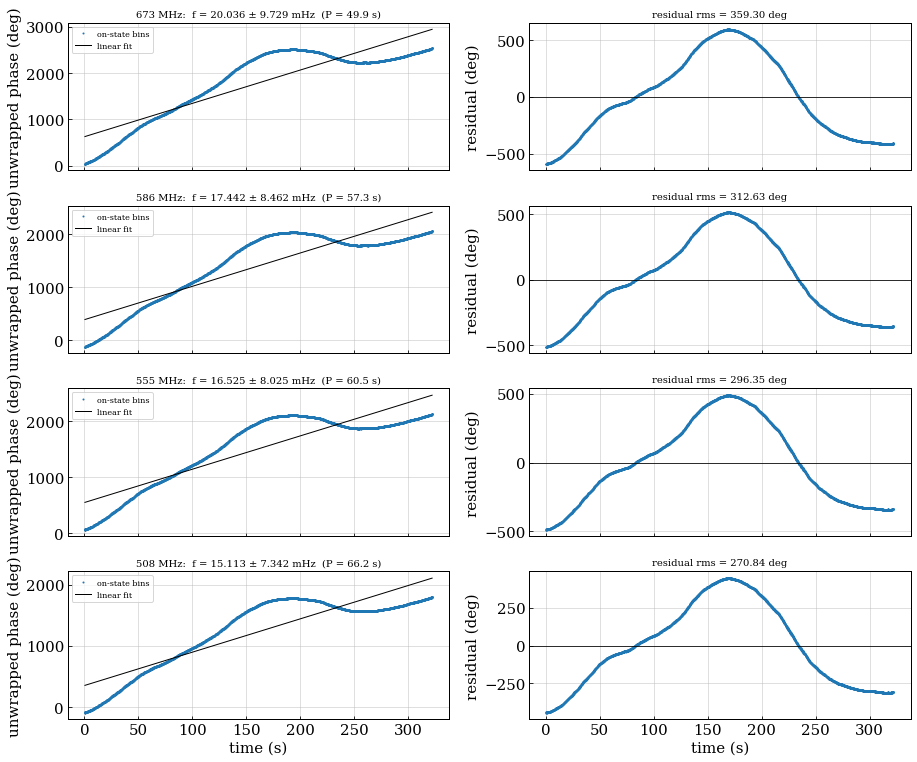

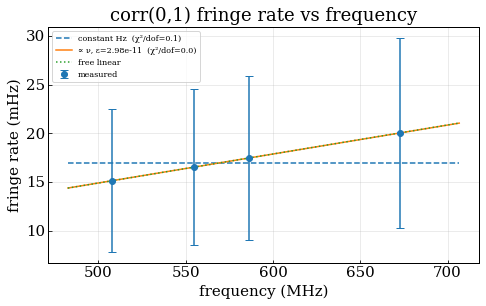

In [97]:
out = run(cross, auto_ref, freqs_mhz=[673, 586, 555, 508])

Text(0, 0.5, 'delay (ns)')

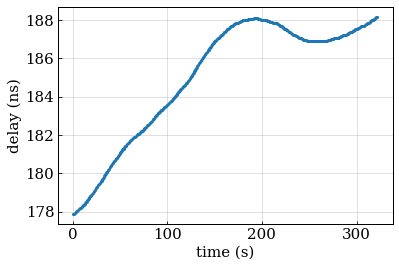

In [98]:
v01 = corr_data.vis[:, :, 1]                              # (7680, 1024) complex
on  = classify_on(corr_data.vis[:, 400, 4].real)[0]       # broadband switching -> one mask
freq_hz = (400 + ((1024- np.arange(1024)) * 400/1024)) * 1e6

# delay spectrum: FFT across frequency, zero-padded for fine delay resolution
pad = 64
dspec = np.fft.fftshift(np.fft.fft(v01[on], n=1024*pad, axis=1), axes=1)
df = 400e6 / 1024
tau_axis = np.fft.fftshift(np.fft.fftfreq(1024*pad, d=df))   # s
tau_t = tau_axis[np.argmax(np.abs(dspec), axis=1)]          # coarse peak per time

t = np.arange(v01.shape[0]) * 0.04194304
plt.plot(t[on], -tau_t * 1e9, ".", ms=2); plt.xlabel("time (s)"); plt.ylabel("delay (ns)")

In [99]:
"""
Overlay broadband delay track tau(t) (delay spectrum, all 1024 channels)
with per-channel phase-derived delay phi(t) / (2*pi*nu) from fringe_rate_fit.run().

Usage in the notebook (after `out = run(cross, auto_ref, freqs_mhz=freqs_ch)`):

    from delay_overlay import overlay
    res = overlay(corr_data, out, chan_idx)

Assumes: 400-800 MHz band, 1024 channels, descending frequency with index,
product 1 = corr(0,1), product 4 = corr(1,1). Change the constants if not.
"""

import numpy as np
import matplotlib.pyplot as plt

DT = 0.04194304
F_TOP_MHZ, BW_MHZ = 800.0, 400.0
P01, P11 = 1, 4


def chan_freq_mhz(idx, nf=1024):
    return F_TOP_MHZ - np.asarray(idx) * BW_MHZ / nf


def delay_track(X, W, df_hz, pad=8, chunk=512):
    """
    Peak of |FFT over frequency| per time row, with parabolic refinement.
    X  : (n_time, n_freq) complex, frequency ASCENDING
    W  : (n_freq,) channel weights (0 = flagged)
    Returns delay in seconds per row. Chunked to keep memory small.
    """
    nt, nf = X.shape
    n = nf * pad
    dtau = 1.0 / (n * df_hz)
    tau = np.empty(nt)
    for s in range(0, nt, chunk):
        D = np.abs(np.fft.fft(X[s:s + chunk] * W, n=n, axis=1))
        k = np.argmax(D, axis=1)
        i = np.arange(len(k))
        ym, y0, yp = D[i, (k - 1) % n], D[i, k], D[i, (k + 1) % n]
        denom = ym - 2 * y0 + yp
        delta = np.where(denom != 0, 0.5 * (ym - yp) / denom, 0.0)
        kk = k + delta
        kk = np.where(kk > n / 2, kk - n, kk)   # signed delay
        tau[s:s + chunk] = kk * dtau
    return tau


def overlay(corr_data, out, chan_idx, on_ref_chan=400, flag_frac=0.5,
            edge_chans=20):
    v = corr_data.vis
    nt, nf, _ = v.shape
    t = np.arange(nt) * DT

    # --- on-state mask from reference autocorrelation (switching is broadband)
    on, _ = classify_on(v[:, on_ref_chan, P11].real)
    t_on = t[on]

    # --- cross spectrum with ascending frequency
    f_mhz = chan_freq_mhz(np.arange(nf), nf)
    order = np.argsort(f_mhz)
    X = v[on][:, order, P01]
    df_hz = BW_MHZ * 1e6 / nf

    # --- channel flags: low amplitude (dead/filtered) and band edges
    amp = np.median(np.abs(X), axis=0)
    W = (amp > flag_frac * np.median(amp)).astype(float)
    W[:edge_chans] = 0
    W[-edge_chans:] = 0
    print(f"channels used in delay spectrum: {int(W.sum())} / {nf}")

    tau_ds = delay_track(X, W, df_hz)
    print(f"mean absolute delay (delay spectrum): {tau_ds.mean()*1e9:.3f} ns "
          f"(instrumental + path difference between the two inputs)")

    # --- per-channel phase delays
    freqs_ch = chan_freq_mhz(chan_idx, nf)
    curves = []
    for r, nu_mhz in zip(out["per_channel"], freqs_ch):
        tp = r["phi"] / (2 * np.pi * nu_mhz * 1e6)
        ds_i = np.interp(r["t"], t_on, tau_ds)
        curves.append((r["t"], tp, ds_i, nu_mhz))

    # --- one global sign check (conjugation / frequency-ordering convention)
    c = np.corrcoef(np.concatenate([cv[1] for cv in curves]),
                    np.concatenate([cv[2] for cv in curves]))[0, 1]
    sgn = 1.0 if c >= 0 else -1.0
    if sgn < 0:
        print("NOTE: phase-delay sign flipped to match delay spectrum "
              "(convention mismatch, not physics).")

    # --- plot
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                                 gridspec_kw=dict(height_ratios=[2, 1]))
    ds0 = tau_ds - tau_ds.mean()
    a1.plot(t_on, ds0 * 1e9, "k.", ms=1.5,
            label=f"delay spectrum (mean {tau_ds.mean()*1e9:.2f} ns removed)")

    print(f"\n{'MHz':>7} {'offset [ns]':>12} {'resid rms [ps]':>15} {'resid slope [ps/100s]':>22}")
    stats = []
    for (tt, tp, ds_i, nu_mhz) in curves:
        tp = sgn * tp
        # phase delay is known only up to a constant (cycle count + instrument phase)
        offset = np.mean(tp - (ds_i - tau_ds.mean()))
        tp_al = tp - offset
        resid = tp_al - (ds_i - tau_ds.mean())
        slope = np.polyfit(tt, resid, 1)[0]
        a1.plot(tt, tp_al * 1e9, ".", ms=1, label=f"{nu_mhz:.1f} MHz  φ/2πν")
        a2.plot(tt, resid * 1e12, ".", ms=1, label=f"{nu_mhz:.1f} MHz")
        rms = resid.std()
        print(f"{nu_mhz:7.1f} {offset*1e9:12.3f} {rms*1e12:15.2f} {slope*100*1e12:22.2f}")
        stats.append(dict(nu_mhz=nu_mhz, offset_s=offset, resid_rms_s=rms,
                          resid_slope=slope, t=tt, resid=resid))

    a1.set_ylabel("relative delay (ns)")
    a1.legend(fontsize=8, markerscale=6)
    a1.grid(alpha=0.3)
    a2.axhline(0, color="k", lw=0.8)
    a2.set_ylabel("phase delay − delay spectrum (ps)")
    a2.set_xlabel("time (s)")
    a2.legend(fontsize=8, markerscale=6, ncol=4)
    a2.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

    return dict(t_on=t_on, tau_ds=tau_ds, weights=W, sign=sgn,
                channels=stats, fig=fig)

channels used in delay spectrum: 937 / 1024
mean absolute delay (delay spectrum): 185.023 ns (instrumental + path difference between the two inputs)

    MHz  offset [ns]  resid rms [ps]  resid slope [ps/100s]
  673.0        7.381            3.47                  -0.18
  585.9        6.641            3.19                  -0.27
  555.1        7.543            3.44                  -0.11
  507.8        6.741            3.57                   0.07


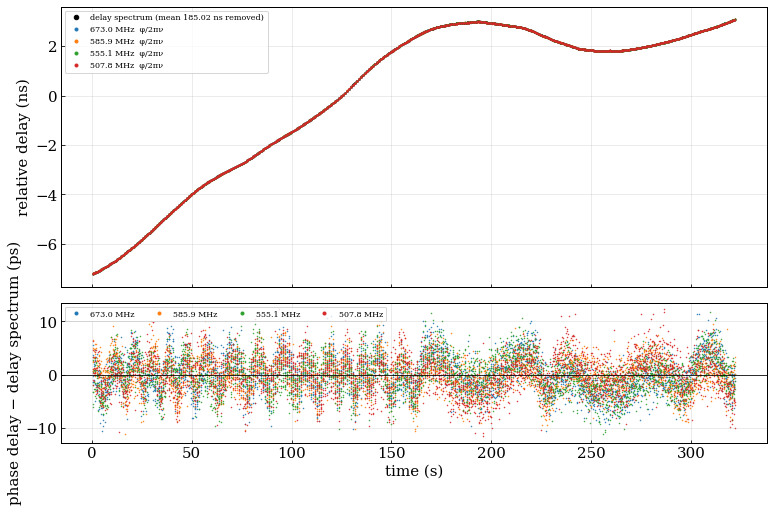

In [100]:
res = overlay(corr_data, out, chan_idx)

In [105]:
"""
On-state amplitude stability of the PEACC correlated signal.

Quantities tracked (on-state only):
  |V01|          cross amplitude                 -> depends on both chains' gains
  P11            reference autocorrelation       -> reference chain only
  dP00           telescope on minus off          -> telescope chain only (system noise removed)
  rho            |V01| / sqrt(dP00 * P11)        -> gain-independent coherence; duty-fraction independent

For each: 4 chosen channels + a band average (each channel normalised by its own
median, then averaged).

Outputs:
  - fractional deviation (%) vs time, averaged in base_s blocks
  - overlapping Allan deviation vs averaging time, with the white-noise
    (radiometer) expectation measured from the data itself
  - summary table: per-bin noise, expected vs measured block scatter,
    ADEV at chosen timescales, peak-to-peak of 10 s averages, linear drift

Usage:
    from amplitude_stability import amplitude_stability
    res = amplitude_stability(corr_data.vis, chan_idx)

    # longer data (contiguous files only; gaps break the Allan deviation):
    vis = np.concatenate([d.vis for d in list_of_corr_data], axis=0)
    res = amplitude_stability(vis, chan_idx)

To say anything about stability on timescale T you need >= 3T of data.
"""

import numpy as np
import matplotlib.pyplot as plt

DT = 0.04194304
P00, P01, P11 = 0, 1, 4          # (0,0), (0,1), (1,1) in a 4-input upper-triangle layout
F_TOP_MHZ, BW_MHZ = 800.0, 400.0


# ----------------------------------------------------------------------------
# State masks
# ----------------------------------------------------------------------------
def _interior(m):
    """Drop the first and last bin of every run: those may be partial-duty bins."""
    prev = np.r_[False, m[:-1]]
    nxt = np.r_[m[1:], False]
    return m & prev & nxt


def state_masks(vis, good_chans):
    """
    Clean on/off masks from the band-averaged reference autocorrelation.
    The threshold is only 50% of the on-level, so a real amplitude drift cannot
    push bins out of the mask; partial-duty bins are removed by dropping run edges.
    """
    p11b = vis[:, good_chans, P11].real.mean(axis=1)
    lvl = np.median(p11b[p11b > 0.5 * p11b.max()])
    on50 = p11b > 0.5 * lvl
    return _interior(on50), _interior(~on50), lvl


def good_channels(vis, edge_chans=20, flag_frac=0.5):
    nf = vis.shape[1]
    p11_med = np.median(np.abs(vis[::8, :, P11]), axis=0)   # subsample time for speed
    good = p11_med > flag_frac * np.median(p11_med)
    good[:edge_chans] = False
    good[-edge_chans:] = False
    return np.flatnonzero(good)


# ----------------------------------------------------------------------------
# Quantities
# ----------------------------------------------------------------------------
QNAMES = ["|V01|", "P11 (ref auto)", "ΔP00 (tel on−off)", "ρ coherence"]


def _quantities(vis, cols, t, on, off):
    a01 = np.abs(vis[:, cols, P01]).astype(np.float64)
    p11 = vis[:, cols, P11].real.astype(np.float64)
    p00 = vis[:, cols, P00].real.astype(np.float64)
    #p00_off = np.empty_like(p00)
    #for j in range(p00.shape[1]):
    #    p00_off[:, j] = np.interp(t, t[off], p00[off, j])
    dp00 = p00 - 80000
    dp00 = p00 
    with np.errstate(invalid="ignore", divide="ignore"):
        rho = a01 / np.sqrt(dp00 * p11)
    return dict(zip(QNAMES, [a01, p11, dp00, rho]))


def _block_mean(t, y, mask, base_s, nblk):
    b = (t[mask] // base_s).astype(int)
    n = np.bincount(b, minlength=nblk)[:nblk]
    s = np.bincount(b, weights=y[mask], minlength=nblk)[:nblk]
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n > 0, s / n, np.nan), n


def oadev(y, m_list):
    """Overlapping Allan deviation of a regularly sampled series y (NaNs interpolated)."""
    y = np.asarray(y, float)
    bad = np.isnan(y)
    if bad.any():
        i = np.arange(len(y))
        y = np.interp(i, i[~bad], y[~bad])
    x = np.r_[0.0, np.cumsum(y)]
    out = []
    for m in m_list:
        d = x[2 * m:] - 2 * x[m:-m] + x[:-2 * m]
        out.append(np.sqrt(np.mean(d ** 2) / (2 * m * m)))
    return np.array(out)


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
def amplitude_stability(vis, chan_idx, freqs_mhz=None, base_s=1.0,
                        adev_report_s=(10, 60), smooth_s=10.0,
                        n_band_chans=256, edge_chans=20):
    vis = np.asarray(vis)
    nt, nf, _ = vis.shape
    t = np.arange(nt) * DT
    chan_idx = list(chan_idx)
    if freqs_mhz is None:
        freqs_mhz = F_TOP_MHZ - np.array(chan_idx) * BW_MHZ / nf

    good = good_channels(vis, edge_chans)
    on, off, lvl = state_masks(vis, good)
    band = good[np.linspace(0, len(good) - 1, min(n_band_chans, len(good))).astype(int)]
    print(f"duration {nt*DT:.1f} s | clean on-bins {on.sum()} | clean off-bins {off.sum()} "
          f"| band average over {len(band)} channels")

    labels = [f"{f:.1f} MHz" for f in freqs_mhz] + ["band avg"]
    nblk = int(np.floor(nt * DT / base_s))
    t_blk = (np.arange(nblk) + 0.5) * base_s

    q_ch = _quantities(vis, chan_idx, t, on, off)
    q_bd = _quantities(vis, band, t, on, off)

    # Drop band channels where the telescope barely sees the source (small, noisy
    # on-off difference): normalising by a near-zero median blows them up.
    dp = q_bd["ΔP00 (tel on−off)"][on]
    snr = np.nanmedian(dp, axis=0) / np.nanstd(dp, axis=0)
    keep = np.isfinite(snr) & (snr > 0.5 * np.nanmedian(snr))
    for k in q_bd:
        q_bd[k] = q_bd[k][:, keep]
        q_bd[k][~np.isfinite(q_bd[k])] = np.nan
    band = band[keep]
    print(f"band channels kept after ΔP00 SNR cut: {keep.sum()}")

    # absolute coherence per channel (answers the earlier rho question)
    rho_abs = np.nanmedian(q_ch["ρ coherence"][on], axis=0)
    rho_band = np.nanmedian(np.nanmedian(q_bd["ρ coherence"][on], axis=0))
    print("median ρ:", ", ".join(f"{l} {r:.4f}" for l, r in zip(labels[:-1], rho_abs)),
          f", band {rho_band:.4f}")

    results = {}
    for q in QNAMES:
        Yc = q_ch[q] / np.nanmedian(q_ch[q][on], axis=0)
        Zb = q_bd[q] / np.nanmedian(q_bd[q][on], axis=0)
        Zb[~np.isfinite(Zb)] = np.nan
        Yb = np.nanmedian(Zb, axis=1)          # median across channels: robust to outliers
        Y = np.column_stack([Yc, Yb])                     # (nt, 5), normalised to ~1

        # per-bin white noise from adjacent clean on-bin pairs
        pair = on[:-1] & on[1:]
        d = (Y[1:] - Y[:-1])[pair]
        sig_bin = np.nanstd(d, axis=0) / np.sqrt(2)

        blk = np.empty((nblk, Y.shape[1]))
        for j in range(Y.shape[1]):
            blk[:, j], nper = _block_mean(t, Y[:, j], on, base_s, nblk)
        frac = blk / np.nanmedian(blk, axis=0) - 1.0
        nbar = np.mean(nper[nper > 0])
        sig_white_blk = sig_bin / np.sqrt(nbar)
        sig_blk = np.nanstd(frac, axis=0)

        m_max = max(1, nblk // 3)
        m_list = np.unique(np.round(np.logspace(0, np.log10(m_max), 25)).astype(int))
        adev = np.array([oadev(frac[:, j], m_list) for j in range(frac.shape[1])])
        tau = m_list * base_s

        k = max(1, int(round(smooth_s / base_s)))
        nk = nblk // k
        sm = np.nanmean(frac[:nk * k].reshape(nk, k, -1), axis=1)
        p2p = np.nanmax(sm, axis=0) - np.nanmin(sm, axis=0)

        ok = ~np.isnan(frac)
        drift = np.array([np.polyfit(t_blk[ok[:, j]], frac[ok[:, j], j], 1)[0]
                          for j in range(frac.shape[1])]) * 60   # per minute

        results[q] = dict(frac=frac, tau=tau, adev=adev, sig_bin=sig_bin,
                          sig_white_blk=sig_white_blk, sig_blk=sig_blk,
                          p2p_smooth=p2p, drift_per_min=drift)

    # ---------------- summary ----------------
    for q in QNAMES:
        r = results[q]
        print(f"\n=== {q} ===")
        hdr = (f"{'':>10} {'σ 42ms':>8} {'σ blk exp':>10} {'σ blk meas':>11} "
               + "".join(f"{'ADEV '+str(s)+'s':>11}" for s in adev_report_s)
               + f" {'p2p '+str(int(smooth_s))+'s':>10} {'drift/min':>10}")
        print(hdr + "   [all in %]")
        for j, lab in enumerate(labels):
            ad = [np.interp(np.log(s), np.log(r['tau']), r['adev'][j]) if s <= r['tau'][-1]
                  else np.nan for s in adev_report_s]
            print(f"{lab:>10} {r['sig_bin'][j]*100:8.3f} {r['sig_white_blk'][j]*100:10.3f} "
                  f"{r['sig_blk'][j]*100:11.3f} "
                  + "".join(f"{a*100:11.3f}" for a in ad)
                  + f" {r['p2p_smooth'][j]*100:10.3f} {r['drift_per_min'][j]*100:10.3f}")
    print(f"\nσ blk = scatter of {base_s:g} s block means. "
          "'exp' = white-noise expectation from adjacent-bin differences. "
          "meas >> exp  ->  real variation beyond radiometer noise.")

    # ---------------- plots ----------------
    colors = [f"C{i}" for i in range(len(labels) - 1)] + ["k"]
    fig1, ax1 = plt.subplots(len(QNAMES), 1, figsize=(12, 2.6 * len(QNAMES)), sharex=True)
    for a, q in zip(ax1, QNAMES):
        fr = results[q]["frac"] * 100
        for j, lab in enumerate(labels):
            a.plot(t_blk, fr[:, j], color=colors[j], lw=1.8 if lab == "band avg" else 0.7,
                   alpha=1 if lab == "band avg" else 0.7, label=lab)
        for y in (-1, 1):
            a.axhline(y, color="r", ls=":", lw=0.8)
        a.axhline(0, color="gray", lw=0.6)
        a.set_ylabel(f"{q}\nΔ (%)")
        a.grid(alpha=0.3)
        a.set_ylim(-5,5)

    ax1[0].legend(fontsize=8, ncol=5, loc="upper right")
    ax1[0].set_title(f"On-state fractional deviation, {base_s:g} s blocks (red dotted = ±1%)")
    ax1[-1].set_xlabel("time (s)")
    fig1.tight_layout()
    #plt.savefig("/Users/kalyanibhopi94/Downloads/June2025_pulsing_mode_time_stability_chamber/investigate_plots/11.png")

    fig2, ax2 = plt.subplots(1, len(QNAMES), figsize=(4.2 * len(QNAMES), 4), sharey=True)
    for a, q in zip(ax2, QNAMES):
        r = results[q]
        for j, lab in enumerate(labels):
            a.loglog(r["tau"], r["adev"][j] * 100, "o-", ms=3, color=colors[j],
                     lw=1.8 if lab == "band avg" else 0.8, label=lab)
            a.loglog(r["tau"], r["sig_white_blk"][j] * 100 / np.sqrt(r["tau"] / base_s),
                     "--", color=colors[j], lw=0.7)
        a.set_title(q, fontsize=10)
        a.set_xlabel("averaging time τ (s)")
        a.grid(alpha=0.3, which="both")
    ax2[0].set_ylabel("Allan deviation (%)")
    ax2[0].legend(fontsize=7)
    fig2.suptitle("Allan deviation (solid) vs white-noise expectation (dashed)")
    fig2.tight_layout()
    #plt.savefig("/Users/kalyanibhopi94/Downloads/June2025_pulsing_mode_time_stability_chamber/investigate_plots/10.png")
    plt.show()

    return dict(results=results, labels=labels, t_blk=t_blk, on=on, off=off,
                band_chans=band, rho_median=rho_abs, figs=(fig1, fig2))

duration 322.1 s | clean on-bins 3194 | clean off-bins 3195 | band average over 256 channels
band channels kept after ΔP00 SNR cut: 204
median ρ: 673.0 MHz 0.4984, 585.9 MHz 0.5396, 555.1 MHz 0.5405, 507.8 MHz 0.5358 , band 0.5348


/var/folders/g1/8y2gy6ys10d17y5j2rzwkwzc0000gn/T/ipykernel_59852/3446667689.py:142: RuntimeWarning: divide by zero encountered in true_divide
  snr = np.nanmedian(dp, axis=0) / np.nanstd(dp, axis=0)
/opt/homebrew/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,



=== |V01| ===
             σ 42ms  σ blk exp  σ blk meas    ADEV 10s   ADEV 60s    p2p 10s  drift/min   [all in %]
 673.0 MHz    1.192      0.379       0.709       0.544      0.125      1.812      0.036
 585.9 MHz    1.036      0.329       0.565       0.383      0.334      1.490      0.009
 555.1 MHz    1.408      0.447       0.532       0.408      0.067      1.450     -0.039
 507.8 MHz    1.370      0.435       0.405       0.232      0.184      0.952      0.026
  band avg    0.107      0.034       0.059       0.030      0.023      0.170      0.017

=== P11 (ref auto) ===
             σ 42ms  σ blk exp  σ blk meas    ADEV 10s   ADEV 60s    p2p 10s  drift/min   [all in %]
 673.0 MHz    0.671      0.213       0.155       0.109      0.045      0.409      0.024
 585.9 MHz    0.572      0.182       0.136       0.086      0.071      0.364      0.025
 555.1 MHz    1.032      0.328       0.113       0.078      0.025      0.333      0.026
 507.8 MHz    1.004      0.319       0.159       0.103 

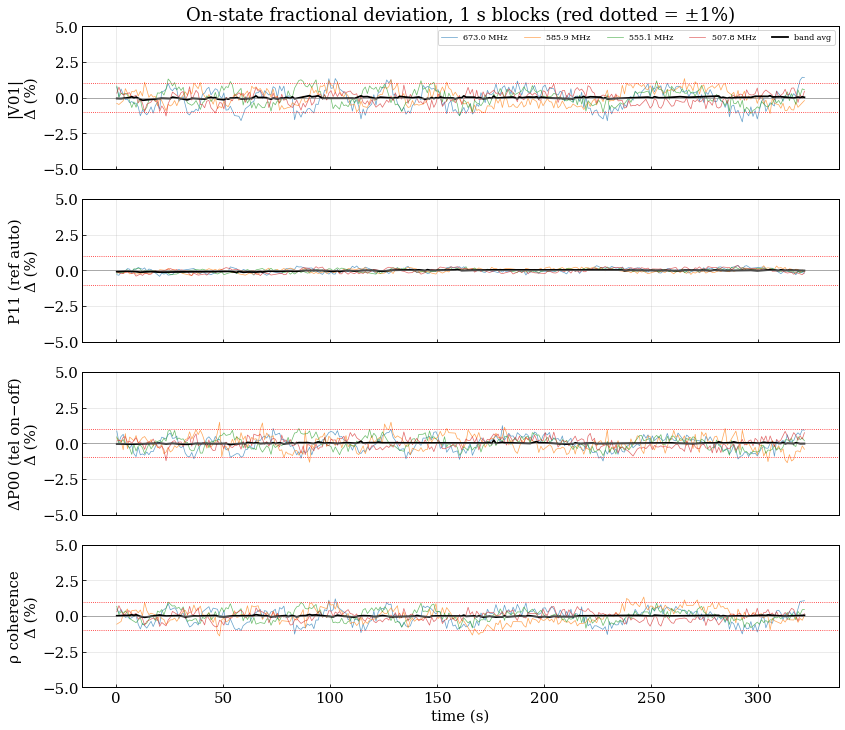

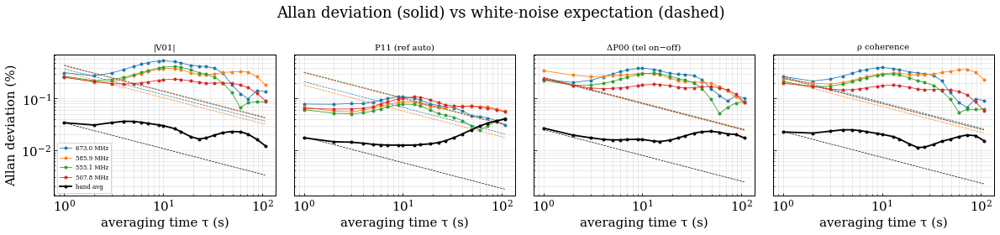

In [106]:
res = amplitude_stability(corr_data.vis, chan_idx)

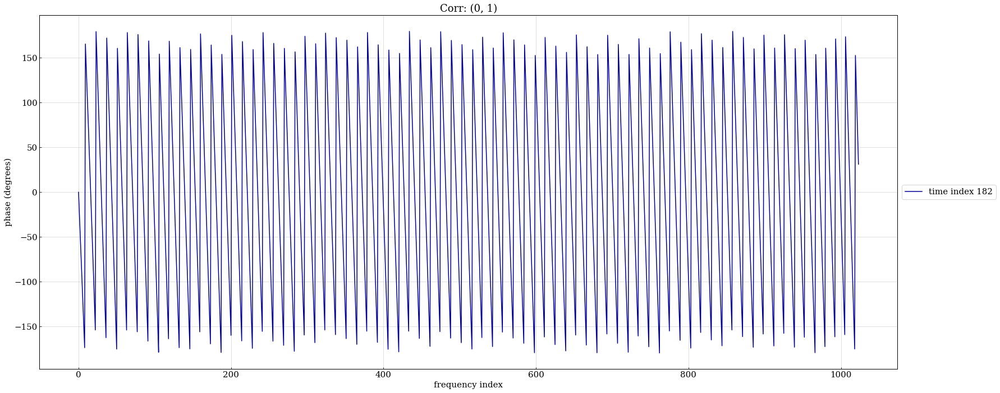

In [93]:
#Phase for a set of time indices as a function of frequency -- publication figures:

t_ind_arr= [182] 
corr_indices=[1] 

plot_phase_corr_data(pow_phase[:,:,:], corr_indices, t_ind_arr)

In [ ]:
# 1 sec contains 23.4818579 time bins ~24 time bins
# 0.5 sec -- 11.920929 ~12 time bins
# calculating medians for the set of x pulses  

med0, med1, med4 = [], [], []
step = 11 # 11 time bins refer to ON points in one pulse and 24 is roughly one complete pulse 
for i in np.arange(6903,7623,24): # need to give range manually every time depending on the sections of the dataset
    med0.append(np.median(pow_mag[i:i+step,fbin,0])) 
    med1.append(np.median(pow_mag[i:i+step,fbin,1])) 
    med4.append(np.median(pow_mag[i:i+step,fbin,4])) 

In [ ]:
# plotting standard deviations of medians (for few pulses) to see deviations in each channel 

fig = plt.figure(figsize=[8,5])
ax = plt.subplot(111)

ax.plot(med0, marker='o', label='corr: (0,0)')
ax.plot(med1, marker='*', label='corr: (0,1)')
ax.plot(med4, marker='.', label='corr: (1,1)')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlabel('pulses')
plt.ylabel('median (arb units)')

print(f"corr(0,0) : standard deviation of medians of corr powers for 30 sec pulses is {np.std(med0)}")
print(f"corr(0,1) : standard deviation of medians of corr powers for 30 sec pulses is {np.std(med1)}")
print(f"corr(1,1) : standard deviation of medians of corr powers for 30 sec pulses is {np.std(med4)}")

In [ ]:
# standard deviation in single ON pulse 

print(np.std(pow_mag[6903:6914,fbin,0]))
print(np.std(pow_mag[6903:6914,fbin,1]))
print(np.std(pow_mag[6903:6914,fbin,4]))

In [ ]:
# overplotting autos and crosses power to check difference

fig = plt.figure(figsize=[15,7])
ax = plt.subplot(111)

ax.plot(pow_mag[tmin:tmax,fbin,0], c=colorsarr[k],label='Corr: (0,0)' )
ax.plot(pow_mag[tmin:tmax,fbin,1],c=colorsarr[k+300], label='Corr: (0,1)')
ax.plot(pow_mag[tmin:tmax,fbin,4],c=colorsarr[k+600], label='Corr: (1,1)')
plt.xlabel("time index")
plt.ylabel("corr power (arb)")
plt.title(f"Corr power mag")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

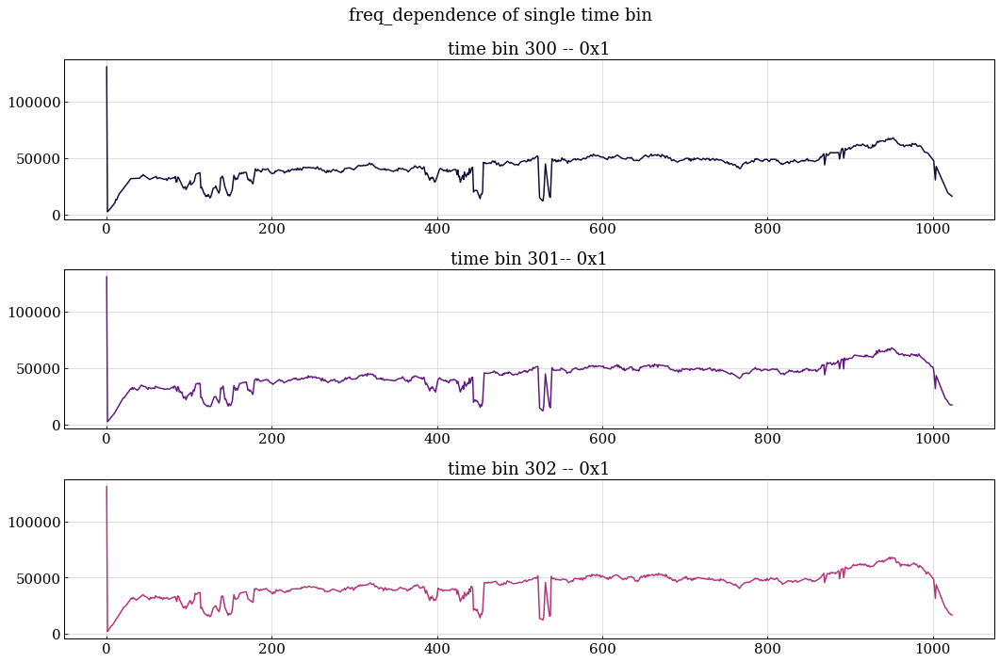

In [94]:
# plotting single 1 sec time samples across the 400-800MHz band 

colorsarr=cm.magma(np.linspace(0,1,1024))
plt.figure(figsize=[15,10])
k=100
tb_1=300
tb_2=301
tb_3=302
plt.subplot(3,1,1)
plt.plot(pow_mag[tb_1,:,1], c=colorsarr[k]) 
#plt.ylim(20000,50000)
plt.title("time bin {} -- 0x1".format(tb_1))

plt.subplot(3,1,2)
plt.plot(pow_mag[tb_2,:,1], c=colorsarr[k+200]) 
#plt.ylim(20000,60000)
plt.title("time bin {}-- 0x1".format(tb_2))

plt.subplot(3,1,3)
plt.plot(pow_mag[tb_3,:,1], c=colorsarr[k+400])
#plt.ylim(0,150000)
plt.title("time bin {} -- 0x1".format(tb_3))

plt.suptitle(f"freq_dependence of single time bin")
plt.tight_layout()

In [ ]:
# plotting waterfall --

plot_waterfall_corr_data(pow_mag[:,:,:],[0,1,4])

In [ ]:
# difference in corr powers between channels (0,0) and (0,1)

plt.plot(pow_mag.real[:,fbin,0] - pow_mag.real[:,fbin,1], c="magenta")

In [ ]:
## plot time bin durations for whole data (to see any glitch)

plt.figure()
plt.plot(np.diff(corr_data.time["irigb_time"])[1:], c="blue")
delta_time = np.diff(corr_data.time["irigb_time"])[1]*1e-9
print(f"Each time bin is: {delta_time} seconds")

In [ ]:
# Phase variation for a single time bin as a function of frequency -- function defined 

def plot_freq_channel_corr_data(pow_mag, freq_index, freq, corr_indices):
    fig= plt.figure(figsize=(10, 5))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    fbin = 3570
    for index, corr_index in enumerate(corr_indices):
            ax = plt.subplot(dim1, dim2, index + 1)
            plt.title(f"Corr: {corr_data.prod[corr_index]}")
            ax.plot(pow_mag[8097,500:950, corr_index], c=colorsarr[500], label='tbin 8097')
            #ax.plot(pow_mag[3710,510:550, corr_index], c=colorsarr[700], label='tbin 3710')
            #ax.plot(pow_mag[3860,510:550, corr_index], c=colorsarr[900], label='tbin 3860')
            #ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
            ax.legend()
            plt.xlabel(f"frequency index")
            plt.ylabel(f"phase (degrees)")

    plt.suptitle(f"Correlated noise phase - frequency: 500-950MHz")
    plt.tight_layout()

In [ ]:
# Phase variation for a single time bin as a function of frequency -- calling a function

print(corr_data.freq) # from corr file 
#print(f['index_map']['freq'][:]) # from digital gain file 
frequency_index = 200  # why 200? -> 200th freq bin refers to 721.875 MHz
frequency = corr_data.freq[0][0] # freq at that frequency bin 
plot_freq_channel_corr_data(pow_phase,frequency_index,frequency,[1])

In [ ]:
##-- write code again for determining the slopes | FIX THIS!!! --##

dx1=np.diff(np.arange(0,1024,1))
dy1=np.diff(pow_phase[2947:2957,fbin,1])
slopes1 = dy1/dx1

dx2=np.diff(np.arange(0,1024,1))
dy2=np.diff(pow_phase[2947:2957,fbin,1])
slopes2=dy2/dx2

dx3=np.diff(np.arange(0,1024,1))
dy3=np.diff(pow_phase[2947:2957,fbin,1])
slopes3=dy3/dx3

# determining std of those slopes 
std1=np.std(slopes1)
std2=np.std(slopes2)
std3=np.std(slopes3)
fig = plt.figure()
ax = plt.subplot(111)

ax.plot(std1, c=colorsarr[100], label='slopes1')
ax.plot(std2, c=colorsarr[500], label='slopes2')
ax.plot(std3, c=colorsarr[800], label='slopes3')
ax.legend()

plt.show()

In [ ]:
## plotting phase curve slopes for different correlation powers 

fig = plt.figure()
ax = plt.subplot(111)

ax.plot(slopes1, c=colorsarr[100],label='time bin - 3570')
ax.plot(slopes2, c=colorsarr[500],label='time bin - 3710')
ax.plot(slopes3, c=colorsarr[800],label='time bin - 3860')

ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

In [39]:
# Phase variation for a single frequency bin as a function of time -- function defined 

def plot_freq_channel_corr_data(pow_phase, freq_index, corr_indices):
    plt.figure(figsize=(25, 10))
    dim1 = math.floor(math.sqrt(len(corr_indices)))
    dim2 = math.ceil(len(corr_indices)/dim1)
    for index, corr_index in enumerate(corr_indices):
            plt.subplot(dim1, dim2, index + 1)
            plt.title(f"Corr: {corr_data.prod[corr_index]}")
            plt.plot(pow_phase[4000:4500,freq_index, corr_index])

    #plt.suptitle(f"Frequency {freq} MHz")
    plt.tight_layout()

In [ ]:
# Phase variation for a single frequency bin as a function of time -- calling a function

frequency_index = np.arange(600,850,1)
frequency = corr_data.freq[frequency_index][0]
print(f"Frequency: {frequency}")
plot_freq_channel_corr_data(pow_phase,frequency_index,[1])

In [ ]:
#### beam pattern ###

In [ ]:
## -- correlator data 
# reading the required only corr files for plotting beam pattern
file_path = '/Volumes/EXTRSSD/corr_dat4/20240724T205100Z_WVUc52/corr/*/*' 

# reading files for 0 degrees angle between rx and tx
corr_data0 = read_corr_mode_h5(file_path, f_start=40, f_stop=42)
pow_mag0, pow_phase0 = get_mag_phase(corr_data0.vis)
# reading files for negative 10 degrees angle between rx and tx
corr_data10n = read_corr_mode_h5(file_path, f_start=57, f_stop=59)
pow_mag10n, pow_phase10n = get_mag_phase(corr_data10n.vis)
# reading files for negative 20 degrees angle between rx and tx
corr_data20n = read_corr_mode_h5(file_path, f_start=63, f_stop=65)
pow_mag20n, pow_phase20n = get_mag_phase(corr_data20n.vis)
# reading files for negative 30 degrees angle between rx and tx
corr_data30n = read_corr_mode_h5(file_path, f_start=70, f_stop=72)
pow_mag30n, pow_phase30n = get_mag_phase(corr_data30n.vis)
# reading files for negative 40 degrees angle between rx and tx
corr_data40n = read_corr_mode_h5(file_path, f_start=78, f_stop=80)
pow_mag40n, pow_phase40n = get_mag_phase(corr_data40n.vis)
# reading files for negative 50 degrees angle between rx and tx
corr_data50n = read_corr_mode_h5(file_path, f_start=83, f_stop=85)
pow_mag50n, pow_phase50n = get_mag_phase(corr_data50n.vis)
# reading files for negative 60 degrees angle between rx and tx
corr_data60n = read_corr_mode_h5(file_path, f_start=90, f_stop=92)
pow_mag60n, pow_phase60n = get_mag_phase(corr_data60n.vis)
# reading files for negative 70 degrees angle between rx and tx
corr_data70n = read_corr_mode_h5(file_path, f_start=98, f_stop=100)
pow_mag70n, pow_phase70n = get_mag_phase(corr_data70n.vis)
# reading files for negative 80 degrees angle between rx and tx 
corr_data80n = read_corr_mode_h5(file_path, f_start=104, f_stop=106)
pow_mag80n, pow_phase80n = get_mag_phase(corr_data80n.vis)
# reading files for negative 90 degrees angle between rx and tx 
corr_data90n = read_corr_mode_h5(file_path, f_start=111, f_stop=113)
pow_mag90n, pow_phase90n = get_mag_phase(corr_data90n.vis)
# reading files for negative 100 degrees angle between rx and tx 
corr_data100n = read_corr_mode_h5(file_path, f_start=118, f_stop=120)
pow_mag100n, pow_phase100n = get_mag_phase(corr_data100n.vis)
# reading files for negative 110 degrees angle between rx and tx 
corr_data110n = read_corr_mode_h5(file_path, f_start=124, f_stop=126)
pow_mag110n, pow_phase110n = get_mag_phase(corr_data110n.vis)
# reading files for negative 120 degrees angle between rx and tx 
corr_data120n = read_corr_mode_h5(file_path, f_start=132, f_stop=134)
pow_mag120n, pow_phase120n = get_mag_phase(corr_data120n.vis)
# reading files for negative 130 degrees angle between rx and tx 
corr_data130n = read_corr_mode_h5(file_path, f_start=138, f_stop=140)
pow_mag130n, pow_phase130n = get_mag_phase(corr_data130n.vis)
# reading files for negative 140 degrees angle between rx and tx 
#corr_data140n = read_corr_mode_h5(file_path, f_start=147, f_stop=149)
#pow_mag140n, pow_phase140n = get_mag_phase(corr_data140n.vis)


# reading files for positive 10 degrees angle between rx and tx
corr_data10p = read_corr_mode_h5(file_path, f_start=158, f_stop=160)
pow_mag10p, pow_phase10p = get_mag_phase(corr_data10p.vis)
# reading files for positive 20 degrees angle between rx and tx 
corr_data20p = read_corr_mode_h5(file_path, f_start=164, f_stop=166)
pow_mag20p, pow_phase20p = get_mag_phase(corr_data20p.vis)
# reading files for positive 30 degrees angle between rx and tx
corr_data30p = read_corr_mode_h5(file_path, f_start=170, f_stop=172)
pow_mag30p, pow_phase30p = get_mag_phase(corr_data30p.vis)
# reading files for positive 40 degrees angle between rx and tx 
corr_data40p = read_corr_mode_h5(file_path, f_start=178, f_stop=180)
pow_mag40p, pow_phase40p = get_mag_phase(corr_data40p.vis)
# reading files for positive 50 degrees angle between rx and tx
corr_data50p = read_corr_mode_h5(file_path, f_start=184, f_stop=186)
pow_mag50p, pow_phase50p = get_mag_phase(corr_data50p.vis)
# reading files for positive 60 degrees angle between rx and tx 
corr_data60p = read_corr_mode_h5(file_path, f_start=193, f_stop=195)
pow_mag60p, pow_phase60p = get_mag_phase(corr_data60p.vis)
# reading files for positive 70 degrees angle between rx and tx
corr_data70p = read_corr_mode_h5(file_path, f_start=201, f_stop=203)
pow_mag70p, pow_phase70p = get_mag_phase(corr_data70p.vis)
# reading files for positive 80 degrees angle between rx and tx 
corr_data80p = read_corr_mode_h5(file_path, f_start=207, f_stop=209)
pow_mag80p, pow_phase80p = get_mag_phase(corr_data80p.vis)
# reading files for positive 90 degrees angle between rx and tx 
corr_data90p = read_corr_mode_h5(file_path, f_start=215, f_stop=217)
pow_mag90p, pow_phase90p = get_mag_phase(corr_data90p.vis)
# reading files for positive 100 degrees angle between rx and tx 
corr_data100p = read_corr_mode_h5(file_path, f_start=222, f_stop=224)
pow_mag100p, pow_phase100p = get_mag_phase(corr_data100p.vis)
# reading files for positive 110 degrees angle between rx and tx 
corr_data110p = read_corr_mode_h5(file_path, f_start=229, f_stop=231)
pow_mag110p, pow_phase110p = get_mag_phase(corr_data110p.vis)
# reading files for positive 120 degrees angle between rx and tx 
corr_data120p = read_corr_mode_h5(file_path, f_start=237, f_stop=239)
pow_mag120p, pow_phase120p = get_mag_phase(corr_data120p.vis)
# reading files for positive 130 degrees angle between rx and tx 
corr_data130p = read_corr_mode_h5(file_path, f_start=243, f_stop=245)
pow_mag130p, pow_phase130p = get_mag_phase(corr_data130p.vis)
# reading files for positive 140 degrees angle between rx and tx 
#corr_data140p = read_corr_mode_h5(file_path, f_start=243, f_stop=245)
#pow_mag140p, pow_phase140p = get_mag_phase(corr_data140p.vis)


print("getting autocorrelation magnitudes and phase")
print("done getting pow_mag and pow_phase")

In [ ]:
## averaging 0.5 sec ON pulse datapoints -- correlator data 

fbin = 890
m00=np.mean(pow_mag0[223:234,fbin,0])
m01=np.mean(pow_mag0[223:234,fbin,1])
m04=np.mean(pow_mag0[223:234,fbin,4])


m10n0=np.mean(pow_mag10n[210:221,fbin,0])
m10n1=np.mean(pow_mag10n[210:221,fbin,1])
m10n4=np.mean(pow_mag10n[210:221,fbin,4])
m20n0=np.mean(pow_mag20n[224:235,fbin,0])
m20n1=np.mean(pow_mag20n[224:235,fbin,1])
m20n4=np.mean(pow_mag20n[224:235,fbin,4])
m30n0=np.mean(pow_mag30n[220:231,fbin,0])
m30n1=np.mean(pow_mag30n[220:231,fbin,1])
m30n4=np.mean(pow_mag30n[220:231,fbin,4])
m40n0=np.mean(pow_mag40n[222:233,fbin,0])
m40n1=np.mean(pow_mag40n[222:233,fbin,1])
m40n4=np.mean(pow_mag40n[222:233,fbin,4])
m50n0=np.mean(pow_mag50n[206:217,fbin,0])
m50n1=np.mean(pow_mag50n[206:217,fbin,1])
m50n4=np.mean(pow_mag50n[206:217,fbin,4])
m60n0=np.mean(pow_mag60n[226:237,fbin,0])
m60n1=np.mean(pow_mag60n[226:237,fbin,1])
m60n4=np.mean(pow_mag60n[226:237,fbin,4])
m70n0=np.mean(pow_mag70n[228:239,fbin,0])
m70n1=np.mean(pow_mag70n[228:239,fbin,1])
m70n4=np.mean(pow_mag70n[228:239,fbin,4])
m80n0=np.mean(pow_mag80n[242:253,fbin,0])
m80n1=np.mean(pow_mag80n[242:253,fbin,1])
m80n4=np.mean(pow_mag80n[242:253,fbin,4])
m90n0=np.mean(pow_mag90n[214:225,fbin,0])
m90n1=np.mean(pow_mag90n[214:225,fbin,1])
m90n4=np.mean(pow_mag90n[214:225,fbin,4])
m100n0=np.mean(pow_mag100n[210:221,fbin,0])
m100n1=np.mean(pow_mag100n[210:221,fbin,1])
m100n4=np.mean(pow_mag100n[210:221,fbin,4])
m110n0=np.mean(pow_mag110n[224:235,fbin,0])
m110n1=np.mean(pow_mag110n[224:235,fbin,1])
m110n4=np.mean(pow_mag110n[224:235,fbin,4])
m120n0=np.mean(pow_mag120n[203:214,fbin,0])
m120n1=np.mean(pow_mag120n[203:214,fbin,1])
m120n4=np.mean(pow_mag120n[203:214,fbin,4])
m130n0=np.mean(pow_mag130n[216:227,fbin,0])
m130n1=np.mean(pow_mag130n[216:227,fbin,1])
m130n4=np.mean(pow_mag130n[216:227,fbin,4])
#m140n0=np.mean(pow_mag140n[206:217,fbin,0])
#m140n1=np.mean(pow_mag140n[206:217,fbin,1])
#m140n4=np.mean(pow_mag140n[206:217,fbin,4])


m10p0=np.mean(pow_mag10p[222:233,fbin,0])
m10p1=np.mean(pow_mag10p[222:233,fbin,1])
m10p4=np.mean(pow_mag10p[222:233,fbin,4])
m20p0=np.mean(pow_mag20p[236:247,fbin,0])
m20p1=np.mean(pow_mag20p[236:247,fbin,1])
m20p4=np.mean(pow_mag20p[236:247,fbin,4])
m30p0=np.mean(pow_mag30p[226:237,fbin,0])
m30p1=np.mean(pow_mag30p[226:237,fbin,1])
m30p4=np.mean(pow_mag30p[226:237,fbin,4])
m40p0=np.mean(pow_mag40p[228:239,fbin,0])
m40p1=np.mean(pow_mag40p[228:239,fbin,1])
m40p4=np.mean(pow_mag40p[228:239,fbin,4])
m50p0=np.mean(pow_mag50p[218:229,fbin,0])
m50p1=np.mean(pow_mag50p[218:229,fbin,1])
m50p4=np.mean(pow_mag50p[218:229,fbin,4])
m60p0=np.mean(pow_mag60p[227:238,fbin,0])
m60p1=np.mean(pow_mag60p[227:238,fbin,1])
m60p4=np.mean(pow_mag60p[227:238,fbin,4])
m70p0=np.mean(pow_mag70p[229:240,fbin,0])
m70p1=np.mean(pow_mag70p[229:240,fbin,1])
m70p4=np.mean(pow_mag70p[229:240,fbin,4])
m80p0=np.mean(pow_mag80p[219:230,fbin,0])
m80p1=np.mean(pow_mag80p[219:230,fbin,1])
m80p4=np.mean(pow_mag80p[219:230,fbin,4])
m90p0=np.mean(pow_mag90p[222:233,fbin,0])
m90p1=np.mean(pow_mag90p[222:233,fbin,1])
m90p4=np.mean(pow_mag90p[222:233,fbin,4])
m100p0=np.mean(pow_mag100p[218:229,fbin,0])
m100p1=np.mean(pow_mag100p[218:229,fbin,1])
m100p4=np.mean(pow_mag100p[218:229,fbin,4])
m110p0=np.mean(pow_mag110p[214:225,fbin,0])
m110p1=np.mean(pow_mag110p[214:225,fbin,1])
m110p4=np.mean(pow_mag110p[214:225,fbin,4])
m120p0=np.mean(pow_mag120p[216:227,fbin,0])
m120p1=np.mean(pow_mag120p[216:227,fbin,1])
m120p4=np.mean(pow_mag120p[216:227,fbin,4])
m130p0=np.mean(pow_mag130p[206:217,fbin,0])
m130p1=np.mean(pow_mag130p[206:217,fbin,1])
m130p4=np.mean(pow_mag130p[206:217,fbin,4])
#m140p0=np.mean(pow_mag140p[215:226,fbin,0])
#m140p1=np.mean(pow_mag140p[215:226,fbin,1])
#m140p4=np.mean(pow_mag140p[215:226,fbin,4])


In [ ]:
## Considering single datapoints from ON pulse 

fbin = 900
s00=pow_mag0[225:226,fbin,0].item()
s01=pow_mag0[225:226,fbin,1].item()
s04=pow_mag0[225:226,fbin,4].item()

s10n0=pow_mag10n[211:212,fbin,0].item()
s10n1=pow_mag10n[211:212,fbin,1].item()
s10n4=pow_mag10n[211:212,fbin,4].item()
s20n0=pow_mag20n[225:226,fbin,0].item()
s20n1=pow_mag20n[225:226,fbin,1].item()
s20n4=pow_mag20n[225:226,fbin,4].item()
s30n0=pow_mag30n[221:222,fbin,0].item()
s30n1=pow_mag30n[221:222,fbin,1].item()
s30n4=pow_mag30n[221:222,fbin,4].item()
s40n0=pow_mag40n[223:224,fbin,0].item()
s40n1=pow_mag40n[223:224,fbin,1].item()
s40n4=pow_mag40n[223:224,fbin,4].item()
s50n0=pow_mag50n[208:209,fbin,0].item()
s50n1=pow_mag50n[208:209,fbin,1].item()
s50n4=pow_mag50n[208:209,fbin,4].item()
s60n0=pow_mag60n[227:228,fbin,0].item()
s60n1=pow_mag60n[227:228,fbin,1].item()
s60n4=pow_mag60n[227:228,fbin,4].item()
s70n0=pow_mag70n[230:231,fbin,0].item()
s70n1=pow_mag70n[230:231,fbin,1].item()
s70n4=pow_mag70n[230:231,fbin,4].item()
s80n0=pow_mag80n[243:244,fbin,0].item()
s80n1=pow_mag80n[243:244,fbin,1].item()
s80n4=pow_mag80n[243:244,fbin,4].item()
s90n0=pow_mag90n[216:217,fbin,0].item()
s90n1=pow_mag90n[216:217,fbin,1].item()
s90n4=pow_mag90n[216:217,fbin,4].item()
s100n0=pow_mag100n[211:212,fbin,0].item()
s100n1=pow_mag100n[211:212,fbin,1].item()
s100n4=pow_mag100n[211:212,fbin,4].item()
s110n0=pow_mag110n[225:226,fbin,0].item()
s110n1=pow_mag110n[225:226,fbin,1].item()
s110n4=pow_mag110n[225:226,fbin,4].item()
s120n0=pow_mag120n[205:206,fbin,0].item()
s120n1=pow_mag120n[205:206,fbin,1].item()
s120n4=pow_mag120n[205:206,fbin,4].item()
s130n0=pow_mag130n[217:218,fbin,0].item()
s130n1=pow_mag130n[217:218,fbin,1].item()
s130n4=pow_mag130n[217:218,fbin,4].item()
#m140n0=np.mean(pow_mag140n[206:217,fbin,0])
#m140n1=np.mean(pow_mag140n[206:217,fbin,1])
#m140n4=np.mean(pow_mag140n[206:217,fbin,4])

s10p0=pow_mag10p[224:225,fbin,0].item()
s10p1=pow_mag10p[224:225,fbin,1].item()
s10p4=pow_mag10p[224:225,fbin,4].item()
s20p0=pow_mag20p[238:239,fbin,0].item()
s20p1=pow_mag20p[238:239,fbin,1].item()
s20p4=pow_mag20p[238:239,fbin,4].item()
s30p0=pow_mag30p[227:228,fbin,0].item()
s30p1=pow_mag30p[227:228,fbin,1].item()
s30p4=pow_mag30p[227:228,fbin,4].item()
s40p0=pow_mag40p[230:231,fbin,0].item()
s40p1=pow_mag40p[230:231,fbin,1].item()
s40p4=pow_mag40p[230:231,fbin,4].item()
s50p0=pow_mag50p[220:221,fbin,0].item()
s50p1=pow_mag50p[220:221,fbin,1].item()
s50p4=pow_mag50p[220:221,fbin,4].item()
s60p0=pow_mag60p[229:230,fbin,0].item()
s60p1=pow_mag60p[229:230,fbin,1].item()
s60p4=pow_mag60p[229:230,fbin,4].item()
s70p0=pow_mag70p[231:232,fbin,0].item()
s70p1=pow_mag70p[231:232,fbin,1].item()
s70p4=pow_mag70p[231:232,fbin,4].item()
s80p0=pow_mag80p[221:222,fbin,0].item()
s80p1=pow_mag80p[221:222,fbin,1].item()
s80p4=pow_mag80p[221:222,fbin,4].item()
s90p0=pow_mag90p[224:225,fbin,0].item()
s90p1=pow_mag90p[224:225,fbin,1].item()
s90p4=pow_mag90p[224:225,fbin,4].item()
s100p0=pow_mag100p[221:222,fbin,0].item()
s100p1=pow_mag100p[221:222,fbin,1].item()
s100p4=pow_mag100p[221:222,fbin,4].item()
s110p0=pow_mag110p[215:216,fbin,0].item()
s110p1=pow_mag110p[215:216,fbin,1].item()
s110p4=pow_mag110p[215:216,fbin,4].item()
s120p0=pow_mag120p[218:219,fbin,0].item()
s120p1=pow_mag120p[218:219,fbin,1].item()
s120p4=pow_mag120p[218:219,fbin,4].item()
s130p0=pow_mag130p[208:209,fbin,0].item()
s130p1=pow_mag130p[208:209,fbin,1].item()
s130p4=pow_mag130p[208:209,fbin,4].item()
#m140p0=np.mean(pow_mag140p[215:226,fbin,0])
#m140p1=np.mean(pow_mag140p[215:226,fbin,1])
#m140p4=np.mean(pow_mag140p[215:226,fbin,4])


In [ ]:
## averaging 0.5 sec OFF pulse datapoints -- correlator data 

m04_off=np.mean(pow_mag0[235:246,fbin,4])

m10n4_off=np.mean(pow_mag10n[222:233,fbin,4])
m20n4_off=np.mean(pow_mag20n[236:247,fbin,4])
m30n4_off=np.mean(pow_mag30n[232:243,fbin,4])
m40n4_off=np.mean(pow_mag40n[234:245,fbin,4])
m50n4_off=np.mean(pow_mag50n[218:229,fbin,4])
m60n4_off=np.mean(pow_mag60n[238:249,fbin,4])
m70n4_off=np.mean(pow_mag70n[240:251,fbin,4])
m80n4_off=np.mean(pow_mag80n[254:265,fbin,4])
m90n4_off=np.mean(pow_mag90n[226:237,fbin,4])
m100n4_off=np.mean(pow_mag100n[222:233,fbin,4])
m110n4_off=np.mean(pow_mag110n[236:247,fbin,4])
m120n4_off=np.mean(pow_mag120n[215:226,fbin,4])
m130n4_off=np.mean(pow_mag130n[228:239,fbin,4])

m10p4_off=np.mean(pow_mag10p[234:245,fbin,4])
m20p4_off=np.mean(pow_mag20p[248:259,fbin,4])
m30p4_off=np.mean(pow_mag30p[238:249,fbin,4])
m40p4_off=np.mean(pow_mag40p[240:251,fbin,4])
m50p4_off=np.mean(pow_mag50p[230:241,fbin,4])
m60p4_off=np.mean(pow_mag60p[239:250,fbin,4])
m70p4_off=np.mean(pow_mag70p[241:252,fbin,4])
m80p4_off=np.mean(pow_mag80p[231:242,fbin,4])
m90p4_off=np.mean(pow_mag90p[234:245,fbin,4])
m100p4_off=np.mean(pow_mag100p[218:229,fbin,4])
m110p4_off=np.mean(pow_mag110p[226:237,fbin,4])
m120p4_off=np.mean(pow_mag120p[228:239,fbin,4])
m130p4_off=np.mean(pow_mag130p[218:229,fbin,4])

In [ ]:
## Considering single datapoints from OFF pulse 

s04_off=pow_mag0[235:236,fbin,4].item()

s10n4_off=pow_mag10n[222:223,fbin,4].item()
s20n4_off=pow_mag20n[236:237,fbin,4].item()
s30n4_off=pow_mag30n[232:233,fbin,4].item()
s40n4_off=pow_mag40n[234:235,fbin,4].item()
s50n4_off=pow_mag50n[218:219,fbin,4].item()
s60n4_off=pow_mag60n[238:239,fbin,4].item()
s70n4_off=pow_mag70n[240:241,fbin,4].item()
s80n4_off=pow_mag80n[254:255,fbin,4].item()
s90n4_off=pow_mag90n[226:227,fbin,4].item()
s100n4_off=pow_mag100n[222:223,fbin,4].item()
s110n4_off=pow_mag110n[236:237,fbin,4].item()
s120n4_off=pow_mag120n[215:216,fbin,4].item()
s130n4_off=pow_mag130n[228:229,fbin,4].item()

s10p4_off=pow_mag10p[234:235,fbin,4].item()
s20p4_off=pow_mag20p[248:249,fbin,4].item()
s30p4_off=pow_mag30p[238:239,fbin,4].item()
s40p4_off=pow_mag40p[240:241,fbin,4].item()
s50p4_off=pow_mag50p[230:231,fbin,4].item()
s60p4_off=pow_mag60p[239:240,fbin,4].item()
s70p4_off=pow_mag70p[241:242,fbin,4].item()
s80p4_off=pow_mag80p[231:232,fbin,4].item()
s90p4_off=pow_mag90p[234:235,fbin,4].item()
s100p4_off=pow_mag100p[218:219,fbin,4].item()
s110p4_off=pow_mag110p[226:227,fbin,4].item()
s120p4_off=pow_mag120p[228:229,fbin,4].item()
s130p4_off=pow_mag130p[218:219,fbin,4].item()

In [ ]:
## Calculating SD for 0.5sec ON pulse datapoints -- correlator data 


std01=np.std(pow_mag0[223:234,fbin,1])

std10n1=np.std(pow_mag10n[210:221,fbin,1])
std20n1=np.std(pow_mag20n[224:235,fbin,1])
std30n1=np.std(pow_mag30n[220:231,fbin,1])
std40n1=np.std(pow_mag40n[222:233,fbin,1])
std50n1=np.std(pow_mag50n[206:217,fbin,1])
std60n1=np.std(pow_mag60n[226:237,fbin,1])
std70n1=np.std(pow_mag70n[228:239,fbin,1])
std80n1=np.std(pow_mag80n[242:253,fbin,1])
std90n1=np.std(pow_mag90n[214:225,fbin,1])
std100n1=np.std(pow_mag100n[210:221,fbin,1])
std110n1=np.std(pow_mag110n[224:235,fbin,1])
std120n1=np.std(pow_mag120n[203:214,fbin,1])
std130n1=np.std(pow_mag130n[216:227,fbin,1])

std10p1=np.std(pow_mag10p[222:233,fbin,1])
std20p1=np.std(pow_mag20p[236:247,fbin,1])
std30p1=np.std(pow_mag30p[226:237,fbin,1])
std40p1=np.std(pow_mag40p[228:239,fbin,1])
std50p1=np.std(pow_mag50p[218:229,fbin,1])
std60p1=np.std(pow_mag60p[227:238,fbin,1])
std70p1=np.std(pow_mag70p[229:240,fbin,1])
std80p1=np.std(pow_mag80p[219:230,fbin,1])
std90p1=np.std(pow_mag90p[222:233,fbin,1])
std100p1=np.std(pow_mag100p[218:229,fbin,1])
std110p1=np.std(pow_mag110p[214:225,fbin,1])
std120p1=np.std(pow_mag120p[216:227,fbin,1])
std130p1=np.std(pow_mag130p[206:217,fbin,1])

In [ ]:
# autos and crosses means and standard deviations lists-- correlator data 
# autos_0x0 -- <VV*>ref,ON
# crosses_0x1 -- <VtVref*>ON
# autos_1x1_ -- <VV*>t,ON 
# autos_1x1_off -- <VV*>t,OFF
# <VV*>ref,OFF --> 0 (this can be autos_0x0_off)

angles = np.arange(-130, 140, 10)

autos_0x0 = [m130n0, m120n0, m110n0, m100n0, m90n0, m80n0, m70n0, m60n0, m50n0, m40n0, m30n0, m20n0, m10n0, m00, m10p0, m20p0, m30p0, m40p0, m50p0, m60p0, m70p0, m80p0, m90p0, m100p0, m110p0, m120p0, m130p0]
crosses_0x1 = [m130n1, m120n1, m110n1, m100n1, m90n1, m80n1, m70n1, m60n1, m50n1, m40n1, m30n1, m20n1, m10n1, m01, m10p1, m20p1, m30p1, m40p1, m50p1, m60p1, m70p1, m80p1, m90p1, m100p1, m110p1, m120p1, m130p1]
autos_1x1_ = [m130n4, m120n4, m110n4, m100n4, m90n4, m80n4, m70n4, m60n4, m50n4, m40n4, m30n4, m20n4, m10n4, m04, m10p4, m20p4, m30p4, m40p4, m50p4, m60p4, m70p4, m80p4, m90p4, m100p4, m110p4, m120p4, m130p4]
autos_1x1_off = [m130n4_off, m120n4_off, m110n4_off, m100n4_off, m90n4_off, m80n4_off, m70n4_off, m60n4_off, m50n4_off, m40n4_off, m30n4_off, m20n4_off, m10n4_off, m04_off, m10p4_off, m20p4_off, m30p4_off, m40p4_off, m50p4_off, m60p4_off, m70p4_off, m80p4_off, m90p4_off, m100p4_off, m110p4_off, m120p4_off, m130p4_off]
stddev = [std130n1, std120n1, std110n1, std100n1, std90n1, std80n1, std70n1, std60n1, std50n1, std40n1, std30n1, std20n1, std10n1, std01, std10p1, std20p1, std30p1, std40p1, std50p1, std60p1, std70p1, std80p1, std90p1, std100p1, std110p1, std120p1, std130p1]


In [ ]:
# Single point corr power lists --

angles = np.arange(-130, 140, 10)

spt_autos_0x0 = [s130n0, s120n0, s110n0, s100n0, s90n0, s80n0, s70n0, s60n0, s50n0, s40n0, s30n0, s20n0, s10n0, s00, s10p0, s20p0, s30p0, s40p0, s50p0, s60p0, s70p0, s80p0, s90p0, s100p0, s110p0, s120p0, s130p0]
spt_crosses_0x1 = [s130n1, s120n1, s110n1, s100n1, s90n1, s80n1, s70n1, s60n1, s50n1, s40n1, s30n1, s20n1, s10n1,s01, s10p1, s20p1, s30p1, s40p1, s50p1, s60p1, s70p1, s80p1, s90p1, s100p1, s110p1, s120p1, s130p1]
spt_autos_1x1_ = [s130n4, s120n4, s110n4, s100n4, s90n4, s80n4, s70n4, s60n4, s50n4, s40n4, s30n4, s20n4, s10n4, s04, s10p4, s20p4, s30p4, s40p4, s50p4, s60p4, s70p4, s80p4, s90p4, s100p4, s110p4, s120p4, s130p4]
spt_autos_1x1_off = [s130n4_off, s120n4_off, s110n4_off, s100n4_off, s90n4_off, s80n4_off, s70n4_off, s60n4_off, s50n4_off, s40n4_off, s30n4_off, s20n4_off, s10n4_off, s04_off, s10p4_off, s20p4_off, s30p4_off, s40p4_off, s50p4_off, s60p4_off, s70p4_off, s80p4_off, s90p4_off, s100p4_off, s110p4_off, s120p4_off, s130p4_off]
stddev = [std130n1, std120n1, std110n1, std100n1, std90n1, std80n1, std70n1, std60n1, std50n1, std40n1, std30n1, std20n1, std10n1, std01, std10p1, std20p1, std30p1, std40p1, std50p1, std60p1, std70p1, std80p1, std90p1, std100p1, std110p1, std120p1, std130p1]


In [ ]:
## autos1x1 --  <VV*>t,ON - <VV*>t,OFF / <VV*>ref,ON - <VV*>ref,OFF
autos_1x1 = []
[autos_1x1.append((autos_1x1_[i] - autos_1x1_off[i]) / autos_0x0[i]) for i in np.arange(0, np.size(autos_1x1_))]

    
## Calculating 1-sigma error bars on crosses
yerr_low = []
yerr_high = []
[yerr_low.append(crosses_0x1[i] - (1*stddev[i])) for i in np.arange(0,np.size(stddev))]
[yerr_high.append(crosses_0x1[i] + (1*stddev[i])) for i in np.arange(0,np.size(stddev))]
    
## Calculating 2-sigma error bars on crosses
yerr_low2 = []
yerr_high2 = []
[yerr_low2.append(crosses_0x1[i] - (2*stddev[i])) for i in np.arange(0,np.size(stddev))]
[yerr_high2.append(crosses_0x1[i] + (2*stddev[i])) for i in np.arange(0,np.size(stddev))]


In [ ]:
## for single data point -- calculating autos(1,1) as
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
## autos1x1 --  <VV*>t,ON - <VV*>t,OFF / <VV*>ref,ON - <VV*>ref,OFF

spt_autos_1x1 = []
for i in np.arange(0, np.size(spt_autos_1x1_)):
    a1x1 = (spt_autos_1x1_[i] - spt_autos_1x1_off[i]) / spt_autos_0x0[i]
    spt_autos_1x1.append(a1x1) 
    
## calculating 1-sigma error bar on crosses 
spt_yerr_low = []
spt_yerr_high = []
for i in np.arange(0,np.size(stddev)):
    spt_yerr_l=spt_crosses_0x1[i] - (1*stddev[i])
    spt_yerr_low.append(spt_yerr_l)
    spt_yerr_h=spt_crosses_0x1[i] + (1*stddev[i])
    spt_yerr_high.append(spt_yerr_h)
    
## Calculating 2-sigma error bars on crosses
spt_yerr_low2 = []
spt_yerr_high2 = []
for i in np.arange(0,np.size(stddev)):
    spt_yerr_l2=spt_crosses_0x1[i] - (2*stddev[i])
    spt_yerr_low2.append(spt_yerr_l2)
    spt_yerr_h2=spt_crosses_0x1[i] + (2*stddev[i])
    spt_yerr_high2.append(spt_yerr_h2)

In [ ]:
##conversion to log scale  -- correlator data 
# dividing factor -- np.sqrt(autos_0x0)

autolog_0x0=10*np.log10(autos_0x0)- 62.7 # giving offset to match the range of VNA plots 
crosslog_0x1=20*np.log10(crosses_0x1/np.sqrt(autos_0x0)) - 62.5 # giving offset to match the range of VNA plots 
autolog_1x1=10*np.log10(autos_1x1) - 14.75 # giving offset to match the range of VNA plots
autolog_1x1_off=10*np.log10(autos_1x1_off) - 72.75
# above "OFF" offset includes difference between auto on and auto off and the one wrt vna which matches with "auto-ON"
# giving offset to match the range of VNA plots 

## error bars in log scale -- something wrong with log conversions 
yerr_lo=20*np.log10(yerr_low/np.sqrt(autos_0x0)) - 62.5
yerr_hi=20*np.log10(yerr_high/np.sqrt(autos_0x0)) - 62.5
yerr_lo2=20*np.log10(yerr_low2/np.sqrt(autos_0x0)) - 62.5
yerr_hi2=20*np.log10(yerr_high2/np.sqrt(autos_0x0)) - 62.5

In [ ]:
## single data point -- conversion to log scale  -- correlator data 
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
## dividing factor -- np.sqrt(autos_0x0)

spt_autolog_0x0=10*np.log10(spt_autos_0x0)- 62.7 # giving offset to match the range of VNA plots 
spt_crosslog_0x1=20*np.log10(spt_crosses_0x1/np.sqrt(spt_autos_0x0)) - 62.5 # giving offset to match the range of VNA plots 
spt_autolog_1x1=10*np.log10(spt_autos_1x1) - 14.75 # giving offset to match the range of VNA plots
spt_autolog_1x1_off=10*np.log10(spt_autos_1x1_off) - 72.75
# above "OFF" offset includes difference between auto on and auto off and the one wrt vna which matches with "auto-ON"
# giving offset to match the range of VNA plots 

In [ ]:
## Approach 1 with error bars --  in log scale (looks right)
spt_yerr_lo=20*np.log10(spt_yerr_low/np.sqrt(spt_autos_0x0)) - 62.5
spt_yerr_hi=20*np.log10(spt_yerr_high/np.sqrt(spt_autos_0x0)) - 62.5
spt_yerr_lo2=20*np.log10(spt_yerr_low2/np.sqrt(spt_autos_0x0)) - 62.5
spt_yerr_hi2=20*np.log10(spt_yerr_high2/np.sqrt(spt_autos_0x0)) - 62.5

In [ ]:
## Approach 2 with error bars -- at lower angles where mean values are comparable to error bars log value 
# would just increase and at higher angles where mean values are much higher that error bars log value would shrink

##### WRONG APPROACH #####

spt_yerr_lo = 20*np.log10(spt_crosses_0x1/np.sqrt(spt_autos_0x0)) - 20*np.log10(stddev/np.sqrt(spt_autos_0x0)) - 62.5
spt_yerr_hi = 20*np.log10(spt_crosses_0x1/np.sqrt(spt_autos_0x0)) + 20*np.log10(stddev/np.sqrt(spt_autos_0x0)) - 62.5

spt_yerr_lo2 = 20*np.log10(spt_crosses_0x1/np.sqrt(spt_autos_0x0)) - 40*np.log10(stddev/np.sqrt(spt_autos_0x0)) - 62.5
spt_yerr_hi2 = 20*np.log10(spt_crosses_0x1/np.sqrt(spt_autos_0x0)) + 40*np.log10(stddev/np.sqrt(spt_autos_0x0)) - 62.5

In [ ]:
## Aprroach 3 with error bars -- at lower angles where mean values are comparable to error bars log value 
# would just increase and at higher angles where mean values are much higher that error bars log value would shrink

##### WRONG APPROACH #####

spt_yerr_lo = 10*np.log10(spt_crosses_0x1) - 20*np.log10(spt_yerr_low)-15.5
spt_yerr_hi = 10*np.log10(spt_yerr_high) - 20*np.log10(spt_crosses_0x1)-15.5

spt_yerr_lo2 = 10*np.log10(spt_crosses_0x1) - 20*np.log10(spt_yerr_low2)-15.5
spt_yerr_hi2 = 10*np.log10(spt_yerr_high2) - 20*np.log10(spt_crosses_0x1)-15.5



In [ ]:
### Using touchstone files from VNA (.s2p files) ###

In [ ]:
## reading all s2p files and saving them in dictionary "dataframes" first with keys and 
## extracting every file in list "s12f" using key

directory = os.getcwd()
data_folder = os.path.join(directory, "/Volumes/EXTRSSD/7_1_AnechoicChamber/7_1_Anechoic_Chamber_SecondTest/s2p_files/")
s2p_files = os.listdir(data_folder)

prefix_ext=len('.s2p')
sorteds2p_files=sorted(s2p_files, key = lambda x: float(x[:-prefix_ext])) # sorting files from -135 to +135 deg
dataframes = {}

s2pf = []
for file in sorteds2p_files:
    dataframe_name = file.split(".")[0]  # Get the name of the file without the extension
    dataframes[dataframe_name] = Network(os.path.join(data_folder, file))
    s2pf.append(dataframes[dataframe_name]) 
    

In [ ]:
## extracting s12 parameter for frequency bin of a choice using plotting functions of Network class from skrf

s12mag_arr = []
s12mags = []
for i in np.arange(1, len(s2pf), 2, dtype=int):
    s12=s2pf[i]["466.4711632453568MHz"].s12.s_db
    s12mag_arr.append(s12)

for j in np.arange(0, np.floor(len(s2pf)/2), dtype=int):
    s12mags.append(s12mag_arr[j][0][0][0])

In [ ]:
##plotting beam pattern with correlator as well as vna data 

colorsarr=cm.magma(np.linspace(0,1,1024))
fig = plt.figure(figsize=[10,8])
ax = plt.subplot(111)

# logarithmic scale --
angles1=np.arange(-130,140,10)
angles = np.arange(-130,140,10)
ax.plot(angles1, list(reversed(s12mags)), ".", c=colorsarr[fbin-300], label='VNA measurements (S12)')
ax.plot(angles, autolog_0x0, "x", c=colorsarr[fbin-300], label='Corr: (0,0)')
ax.plot(angles, crosslog_0x1, "s",  c=colorsarr[fbin-200],label='Corr: (0,1)')
ax.plot(angles, autolog_1x1, "^", c=colorsarr[fbin-500],label='Corr: (1,1)')
ax.plot(angles, autolog_1x1_off, ".--", c=colorsarr[fbin], label='noise floor')

ax.fill_between(angles, yerr_lo, yerr_hi, alpha=0.25, color='tab:blue', label='1$\sigma$ error')
ax.fill_between(angles, yerr_lo2, yerr_hi2, alpha=0.15, color='tab:pink', label='2$\sigma$ error')
#ax.legend()
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
freq=400+((1024-fbin)*0.390625)
plt.title("Beam map at freq bin {} i.e. {}MHZ".format(fbin, freq))
plt.xlabel("angle (deg)")
plt.ylabel("corr power (dB)")

plt.show()

In [ ]:
## single point -- correlator data 
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
## plotting beam pattern with correlator as well as vna data 

colorsarr=cm.magma(np.linspace(0,1,1024))
fig = plt.figure(figsize=[10,8])
ax = plt.subplot(111)

# logarithmic scale --
angles1=np.arange(-130,140,10)
angles = np.arange(-130,140,10)
ax.plot(angles1, list(reversed(s12mags)), ".", c=colorsarr[fbin-300], label='VNA measurements (S12)')
ax.plot(angles, spt_autolog_0x0, "x", c=colorsarr[fbin-300], label='Corr: (0,0)')
ax.plot(angles, spt_crosslog_0x1, "s",  c=colorsarr[fbin-200],label='Corr: (0,1)')
ax.plot(angles, spt_autolog_1x1, "^", c=colorsarr[fbin-500],label='Corr: (1,1)')
ax.plot(angles, spt_autolog_1x1_off, ".--", c=colorsarr[fbin], label='noise floor')
#plt.ylim(-20,-10)

ax.fill_between(angles, spt_yerr_lo, spt_yerr_hi, alpha=0.25, color='tab:blue', label='1$\sigma$ error')
ax.fill_between(angles, spt_yerr_lo2, spt_yerr_hi2, alpha=0.15, color='tab:pink', label='2$\sigma$ error')
#ax.legend()
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
freq=400+((1024-fbin)*0.390625)
plt.title("Beam map at freq bin {} i.e. {}MHZ".format(fbin, freq))
plt.xlabel("angle (deg)")
plt.ylabel("corr power (dB)")

plt.show()

In [ ]:
## log scale using in-built function scale --- beam mapping 

colorsarr=cm.magma(np.linspace(0,1,1024))
fig = plt.figure(figsize=[10,8])
ax = plt.subplot(111)

# logarithmic scale --
angles1=np.arange(-130,140,10)
angles = np.arange(-130,140,10)
#ax.plot(angles1, list(reversed(s12mags)), ".", c=colorsarr[fbin-300], label='VNA measurements (S12)')
#ax.plot(angles, spt_autos_0x0, "x", c=colorsarr[fbin-300], label='Corr: (0,0)')
ax.plot(angles, spt_crosses_0x1, "s",  c=colorsarr[fbin-200],label='Corr: (0,1)')
#ax.plot(angles, spt_autos_1x1, "^", c=colorsarr[fbin-500],label='Corr: (1,1)')
ax.plot(angles, spt_autos_1x1_off, ".--", c=colorsarr[fbin], label='noise floor')
#plt.ylim(-20,-10)
plt.yscale("log")


ax.fill_between(angles, spt_yerr_low, spt_yerr_high, alpha=0.25, color='tab:blue', label='1$\sigma$ error')
ax.fill_between(angles, spt_yerr_low2, spt_yerr_high2, alpha=0.15, color='tab:pink', label='2$\sigma$ error')
#ax.legend()
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
freq=400+((1024-fbin)*0.390625)
plt.title("Beam map at freq bin {} i.e. {}MHZ".format(fbin, freq))
plt.xlabel("angle (deg)")
plt.ylabel("corr power (dB)")


plt.show()

In [ ]:
## VNA data -- Morgan's code  

In [ ]:
import csv
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import wfdb
from PIL import Image
from IPython.display import display, Image

In [ ]:
## Morgan's code -- VNA data 
## Get the data files and store them in dataframes where they can be called on as dataframes["name##"]

# Get the current directory
directory = os.getcwd()

# Path to the data folder
data_folder = os.path.join(directory, "/Users/kalyanibhopi94/Downloads/anechoic_chamber_data2/") #replace with your path to the data

# List all files in the data folder
files = os.listdir(data_folder)

# Filter files that start with "antwo" and end with ".csv"
outside_files = [file for file in files if file.startswith("antwo") and file.endswith(".csv")]

# Create a dictionary to hold the dataframes
dataframes = {}

# Read each CSV file into a dataframe and store it in the dictionary
for file in outside_files:
    dataframe_name = file.split(".")[0]  # Get the name of the file without the extension
    dataframes[dataframe_name] = pd.read_csv(os.path.join(data_folder, file))

In [ ]:
## Morgan's code -- VNA data
def csv_reframe(csv_file):
    # Load the CSV file into a DataFrame (assuming csv_file is already a DataFrame)
    df = csv_file
    
    # Step 1: Find the index where the first column contains the value "Frequency [Hz]" and "Bridge Name"
    index_frequency = df.index[df.iloc[:, 0] == "Frequency [Hz]"].tolist()[0]
    index_bridge = df.index[df.iloc[:, 0] == "Bridge Mode"].tolist()

    # Extract suffix_name_1 and suffix_name_2 as strings
    suffix_name_1 = str(df.iloc[index_bridge[0], 1])
    suffix_name_2 = str(df.iloc[index_bridge[0], 5])
    
    # Step 3: Extract the row at index `index_frequency` as new column names
    new_column_names = df.iloc[index_frequency].astype(str).tolist()  # Ensure all names are strings

    # Step 4: Check for duplicate column names and add distinguishing suffix
    seen = {}
    suffix_counter = {}
    
    for i, name in enumerate(new_column_names):
        if name not in seen:
            seen[name] = 1  # First occurrence, use suffix_name_1
            new_column_names[i] += f"_{suffix_name_1}"
        else:
            seen[name] += 1
            if seen[name] == 2:
                new_column_names[i] += f"_{suffix_name_2}"  # Second occurrence, use suffix_name_2
            elif seen[name] % 4 == 3:  # Third occurrence (and every fourth occurrence)
                new_column_names[i] += f"_{suffix_name_1}_1"  # Use suffix_name_1 + _1
            else:
                new_column_names[i] += f"_{suffix_name_2}"  # Fourth occurrence, use suffix_name_2

    # Step 5: Copy and store rows including and after the index_frequency row
    new_df = df.iloc[index_frequency+1:].copy()

    # Step 6: Set the new column names
    new_df.columns = new_column_names

    # Step 7: Remove columns with NaN names
    new_df = new_df.dropna(axis=1, how='all')

    # Return the new DataFrame
    return new_df

In [ ]:
## Morgan's code -- VNA data 
#reframing all the data

# Dictionary to hold reframed dataframes
reframed_dfs = {}

for filename, dataframe in dataframes.items():
    # Extract the number from the filename
    num_str = filename.split("antwo")[1].split(".csv")[0]
    num = int(num_str) if num_str else 0
    # Call csv_reframe function on the current dataframe
    reframed_dfs[f"antwo_{num}"] = csv_reframe(dataframe)

In [ ]:
## Morgan's code -- VNA data 
#Displaying as an example

reframed_dfs["antwo_5"]

In [ ]:
## Morgan's code -- VNA data 
# Define function to retrieve specific CSV files from the dataframes dictionary

def retrieve_files(dataframes, file_numbers):
    retrieved_dataframes = {}
    for num in file_numbers:
        filename = f"antwo_{num}"
        if filename in dataframes:
            retrieved_dataframes[filename] = dataframes[filename]
        else:
            print(f"DataFrame {filename} not found.")
    return retrieved_dataframes

In [ ]:
## Morgan's code -- VNA data 
#place where I define & retrieve the files of the different groups of measurements I want

s21_12 = [5,7,8,11,12,15,16,19,20,23,24,27,28,31,32,35,36,39,40,42,45,46,49,50,53,54,57,58,61,62,65,66,69,70,73,74,77]
s11_22 = [4,6,9,10,13,14,17,18,21,22,25,26,29,30,33,34,37,38,41,43,44,47,48,51,52,55,56,59,60,63,64,67,68,71,72,75,76]

s21_12_data = retrieve_files(reframed_dfs,s21_12)
s11_22_data = retrieve_files(reframed_dfs,s11_22)

In [ ]:
## Morgan's code -- VNA data 
#To Match Kalyani's bins

def interpolate_value(step, total_steps, start_value, end_value):
    # Calculate the fraction of the total range
    fraction = step / total_steps
    
    # Interpolate to find the value at the specified step
    interpolated_value = start_value + fraction * (end_value - start_value)
    
    return interpolated_value

# Given values
total_steps = 1024
start_value = 800e6
end_value = 400e6

step_to_find = 778 #enter whatever you want here

# Calculate the interpolated value at step 245
value_at_step = interpolate_value(step_to_find, total_steps, start_value, end_value)

print(f"The value at bin "+str(step_to_find)+" is: " +str(value_at_step)+" Hz")


In [ ]:
colorsarr=cm.magma(np.linspace(0,1,1024))
desired_freq = value_at_step  
frequency_column = (s21_12_data['antwo_5']['Frequency [Hz]_S21']).astype(float)

# Find the index of the closest value
fav_freq_index = (np.abs(frequency_column - desired_freq)).idxmin()

# Get the actual closest value
closest_value = frequency_column[fav_freq_index]

#print("Index of Closest Value:", fav_freq_index)
#print("Closest Value:", closest_value)

s21mags = []
s21phases = []
for key, df in s21_12_data.items():
    # Extract magnitude and phase values for S21 from specific row and column indices
    mag = df.iloc[:, 1]
    all_mags_corrected1 = mag.astype(float) 
    mag = all_mags_corrected1[fav_freq_index]
    phase = float(df.iloc[fav_freq_index, 2]) % 360  # Ensure the value is numeric before applying modulo
    if phase > 180:
        phase -= 360
    # Append the values to the arrays
    s21mags.append(mag)
    s21phases.append(phase)

s12mags = []
s12phases = []
for key, df in s21_12_data.items():
    # Extract magnitude and phase values for S12 from specific row and column indices
    mag = df.iloc[:, 4]
    all_mags_corrected1 = mag.astype(float)
    mag = all_mags_corrected1[fav_freq_index]
    phase = float(df.iloc[fav_freq_index, 5]) % 360  # Ensure the value is numeric before applying modulo
    if phase > 180:
        phase -= 360
    # Append the values to the arrays
    # Append the values to the arrays
    s12mags.append(mag)
    s12phases.append(phase)

# Convert angles1 and s21mags to numpy arrays for easier handling

angles1 = np.array([-90,-85,-80,-75,-70,-65,-60,-55,-50,-45,-40,-35,-30,-25,-20,-15,-10,-5,0,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90])
mags21_float = np.array([float(value) for value in s21mags])
mags12_float = np.array([float(value) for value in s12mags])

fig = plt.figure(figsize=[7,5])
ax = plt.subplot(111)
# Plotting scatter plot with bolder dots
#plt.scatter(angles1, mags1_float, marker='o', s=20, label='Bicolog Transmission on Chime Antenna', alpha=0.75, edgecolors='black',c='orange')  # Increased 's' for larger dots, 'alpha' for transparency, 'edgecolors' for bolder dots

# Plotting line connecting the points
ax.plot(angles1, mags12_float, "s--", color= colorsarr[fbin], label='VNA (S12) measurements')  # Adjust linestyle, linewidth, and alpha as needed
ax.plot(angles, crosslog_0x1, "v--",  c=colorsarr[fbin-300],label='Corr: (0,1)')
ax.plot(angles, autolog_1x1, "^--", c=colorsarr[fbin-600],label='Corr: (1,1)')
#Marking the actual peaks
#plt.axvline(x=angles1[mags1_float.index(max(mags1_float))], color='pink', linestyle='--')
plt.xlabel('Angle (degrees)')
plt.ylabel('Received power (dB)')
# Adding values to x-axis ticks
#plt.xticks(ticks=all_angles, labels=[f'{angle}' for angle in angles1])
# Adding dB unit to y-axis ticks
#plt.yticks(ticks=plt.yticks()[0], labels=[f'{gain} dB' for gain in plt.yticks()[0]])
plt.title('Freq ' +str(s21_12_data['antwo_5']['Frequency [Hz]_S21'][fav_freq_index])+' MHz (freq bin '+str(step_to_find)+')')
plt.legend(loc='upper left',bbox_to_anchor=(1.05, 1))
plt.grid(True, alpha=0.5)
plt.show()

In [ ]:

### Using touchstone files from VNA (.s2p files) ### -- learning how to use functions -- IGNORE THIS SECTION


In [ ]:
## reading single s2p file 
s00 = Network('/Volumes/EXTRSSD/7_1_AnechoicChamber/7_1_Anechoic_Chamber_SecondTest/s2p_files/000.s2p')

In [ ]:
s00

In [ ]:
s00.plot_s_db() # plot magnitude of s-parameters in log scale

In [ ]:
s00.plot_s_db(0,1) ## S12 parameter

In [ ]:
s00.plot_s_deg() # plot phase of s-parameters in degrees

In [ ]:
s00.plot_s_deg(0,0) # plot phase of s11 

In [ ]:
s00.plot_s_smith() # plot complex s-parameters on Smith Chart

In [ ]:
s00.plot_s_smith(1,1)  # plot complex s22 on smith chart

In [ ]:
np.shape(s00.s) # size of every s2p file

In [ ]:
## slicing the data point you want from s2p file 
s12=s00.s[fbin,0,1]